In [1]:
import geemap
import ee
%pip install geemap earthengine-api rasterio matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#initialiser mon compte gee avec google colab
ee.Authenticate()
ee.Initialize(project='phrasal-bond-492112-f3')  #remplacer par l'ID de votre compte
Map = geemap.Map()
Map.add_basemap('HYBRID')
Map


Successfully saved authorization token.


Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

4/1ATsMZqA5t7_N7p_r07r_n_PdPihWTbIrPeuSF8ryfg5ByZmupXGUH2PgBUk

In [1]:
%pip install geedim


   ----------------------------------------  0/10 [tqdm]
   ---- -----------------------------------  1/10 [tabulate]
   -------- -------------------------------  2/10 [propcache]
   ---------------- -----------------------  4/10 [frozenlist]
   -------------------- -------------------  5/10 [aiohappyeyeballs]
   ------------------------ ---------------  6/10 [yarl]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   ------------------------------------ ---  9/10 [geedim]
   ---------------------------------------- 10/10 [geedim]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
"""
================================================================================
CLASSIFICATION SUPERVISÉE 2013-2025 - 7 CLASSES - Landsat 8 / 9
Région de Doubirou (Sénégal) | Google Earth Engine - API PYTHON
================================================================================

Reprend la logique du script JavaScript, avec en plus des SORTIES GRAPHIQUES :
  - Matrice de confusion (heatmap matplotlib)
  - Diagramme d'importance des variables (Random Forest)
  - Diagramme d'évolution des surfaces par classe (barres + courbes)
  - Cartes de classification par année (matplotlib)

PRÉREQUIS (à installer une fois) :
    pip install earthengine-api geemap rasterio matplotlib numpy pandas

PREMIÈRE UTILISATION :
    import ee ; ee.Authenticate()   # puis suivre le lien
Remplace 'ton-projet-gee' par l'ID de ton projet Google Cloud lié à Earth Engine.
================================================================================
"""

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import rasterio
import os

# --------------------------------------------------------------------------
# 0. INITIALISATION
# --------------------------------------------------------------------------
ee.Authenticate()   
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER_SORTIE = 'sorties_classification'
os.makedirs(DOSSIER_SORTIE, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMÈTRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4');

ROI = Zone_etude.geometry()

  
ANNEES = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2021, 2024, 2026]
ANNEE_REF = 2021           # année de référence (= carte WorldCover v200)
N_CLASSES = 7
NUAGES_MAX = 20
RESOLUTION = 30
RES_CARTE = 30             # résolution (m) pour le TÉLÉCHARGEMENT des cartes (affichage)
N_ARBRES = 150
PART_VALIDATION = 0.3
N_POINTS_PAR_CLASSE = 300
CALAGE_SAISONNIER = True
FENETRE_ANNEES = 1

# Correction du sur-classement du bâti
CORRIGER_BATI = True
RAYON_SETTLEMENT_M = 300

BANDES_COMMUNES = ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
# NDBI retiré volontairement (confond sol nu sec et bâti)
BANDES_CLASS = BANDES_COMMUNES + ['NDVI', 'MNDWI', 'BSI', 'SAVI',
                                  'MSAVI', 'NDMI', 'EVI', 'NDWI']

PALETTE = ['#1f78b4', '#006400', '#78c679', '#ffd92f',
           '#c2e699', '#b15928', '#e31a1c']
NOMS = ['Eau', 'Végétation dense', 'Savane arborée/arbustive', 'Cultures',
        'Herbacé/prairie', 'Sol nu', 'Bâti/urbain']


# --------------------------------------------------------------------------
# 2. PRÉTRAITEMENT
# --------------------------------------------------------------------------
# --------------------------------------------------------------------------
# 2. PRÉTRAITEMENT
# --------------------------------------------------------------------------
BANDES_L7 = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7']    # Landsat 7
BANDES_L89 = ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']   # Landsat 8 / 9


def prep_generique(bandes_brutes):
    """Masquage nuages/ombres/saturation + échelle + renommage,
    adapté au jeu de bandes du capteur passé en argument."""
    def _prep(image):
        qa = image.select('QA_PIXEL')
        masque = (qa.bitwiseAnd(1 << 1).eq(0)
                  .And(qa.bitwiseAnd(1 << 3).eq(0))
                  .And(qa.bitwiseAnd(1 << 4).eq(0)))
        sat = image.select('QA_RADSAT').eq(0)
        sr = image.select('SR_B.').multiply(0.0000275).add(-0.2)
        image = image.addBands(sr, None, True).updateMask(masque).updateMask(sat)
        return image.select(bandes_brutes, BANDES_COMMUNES)
    return _prep


def ajouter_indices(img):
    ndvi = img.normalizedDifference(['nir', 'red']).rename('NDVI')
    mndwi = img.normalizedDifference(['green', 'swir1']).rename('MNDWI')
    ndwi = img.normalizedDifference(['green', 'nir']).rename('NDWI')
    ndmi = img.normalizedDifference(['nir', 'swir1']).rename('NDMI')
    bsi = img.expression(
        '((S + R) - (N + B)) / ((S + R) + (N + B))',
        {'S': img.select('swir1'), 'R': img.select('red'),
         'N': img.select('nir'), 'B': img.select('blue')}).rename('BSI')
    savi = img.expression(
        '((N - R) / (N + R + 0.5)) * 1.5',
        {'N': img.select('nir'), 'R': img.select('red')}).rename('SAVI')
    msavi = img.expression(
        '(2 * N + 1 - sqrt((2 * N + 1) * (2 * N + 1) - 8 * (N - R))) / 2',
        {'N': img.select('nir'), 'R': img.select('red')}).rename('MSAVI')
    evi = img.expression(
        '2.5 * ((N - R) / (N + 6 * R - 7.5 * B + 1))',
        {'N': img.select('nir'), 'R': img.select('red'),
         'B': img.select('blue')}).rename('EVI')
    return img.addBands([ndvi, mndwi, ndwi, ndmi, bsi, savi, msavi, evi])


# --------------------------------------------------------------------------
# 3. COMPOSITE ANNUEL (saison sèche, Landsat 8/9)
# --------------------------------------------------------------------------
def fenetre_dates(annee):
    a0, a1 = annee - FENETRE_ANNEES, annee + FENETRE_ANNEES
    if CALAGE_SAISONNIER:
        return f'{a0 - 1}-05-01', f'{a1}-02-01'      # saison sèche nov -> avril
    return f'{a0}-01-01', f'{a1}-12-31'


def collection_capteur(cid, f, bandes_brutes):
    return (ee.ImageCollection(cid)
            .filterBounds(ROI).filterDate(f[0], f[1])
            .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX))
            .map(prep_generique(bandes_brutes)))


def composite_annuel(annee):
    f = fenetre_dates(annee)
    if annee < 2013:
        col = collection_capteur('LANDSAT/LE07/C02/T1_L2', f, BANDES_L7)    # Landsat 7
    elif annee <= 2022:
        col = collection_capteur('LANDSAT/LC08/C02/T1_L2', f, BANDES_L89)   # Landsat 8
    else:
        col = collection_capteur('LANDSAT/LC09/C02/T1_L2', f, BANDES_L89)   # Landsat 9
    return ajouter_indices(col.median().clip(ROI))
    


# --------------------------------------------------------------------------
# 4. ÉCHANTILLONS AUTO (ESA WorldCover) + ENTRAÎNEMENT
# --------------------------------------------------------------------------
comp_ref = composite_annuel(ANNEE_REF)

wc = ee.ImageCollection('ESA/WorldCover/v200').first().clip(ROI)
wc_de = [80, 10, 95, 20, 40, 30, 90, 50, 60, 100, 70]
wc_vers = [1,  2,  2,  3,  4,  5,  5,  7,  6,   6,  0]   # 0 = ignoré
labels = wc.remap(wc_de, wc_vers).rename('classe')
labels = labels.updateMask(labels.neq(0))

pile = comp_ref.select(BANDES_CLASS).addBands(labels)
donnees = pile.stratifiedSample(
    numPoints=N_POINTS_PAR_CLASSE, classBand='classe',
    region=ROI, scale=RESOLUTION, seed=42, tileScale=4, geometries=True)

donnees = donnees.randomColumn('alea', 42)
jeu_train = donnees.filter(ee.Filter.lt('alea', 1 - PART_VALIDATION))
jeu_valid = donnees.filter(ee.Filter.gte('alea', 1 - PART_VALIDATION))

classifieur = ee.Classifier.smileRandomForest(N_ARBRES).train(
    features=jeu_train, classProperty='classe', inputProperties=BANDES_CLASS)

# Second classifieur SANS bâti (pour réattribuer les faux bâti)
classifieur_sans_bati = ee.Classifier.smileRandomForest(N_ARBRES).train(
    features=jeu_train.filter(ee.Filter.neq('classe', 7)),
    classProperty='classe', inputProperties=BANDES_CLASS)

# Zone où le bâti est plausible (abords des habitats connus WorldCover)
wc_bati = wc.eq(50)
zone_bati = wc_bati.focal_max(radius=RAYON_SETTLEMENT_M,
                              kernelType='circle', units='meters')
hors_zone_bati = zone_bati.unmask(0).eq(0)


def corriger_bati(classif, comp):
    if not CORRIGER_BATI:
        return classif
    reassignee = comp.select(BANDES_CLASS).classify(classifieur_sans_bati)
    return classif.where(classif.eq(7).And(hors_zone_bati), reassignee)


# --------------------------------------------------------------------------
# 5. GRAPHIQUE 1 : MATRICE DE CONFUSION
# --------------------------------------------------------------------------
valide = jeu_valid.classify(classifieur)
matrice_ee = valide.errorMatrix('classe', 'classification')
cm = np.array(matrice_ee.getInfo())[1:, 1:]           # on retire la ligne/col 0
acc = matrice_ee.accuracy().getInfo()
kappa = matrice_ee.kappa().getInfo()
print(f'Précision globale : {acc:.3f} | Kappa : {kappa:.3f}')

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(NOMS, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(NOMS, fontsize=8)
ax.set_xlabel('Classe prédite'); ax.set_ylabel('Classe réelle (WorldCover)')
ax.set_title(f'Matrice de confusion\nPrécision globale = {acc:.2%}  |  Kappa = {kappa:.3f}')
seuil = cm.max() / 2
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > seuil else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label="Nombre d'échantillons")
plt.tight_layout()
plt.savefig(f'{DOSSIER_SORTIE}/01_matrice_confusion.png', dpi=200)
plt.close()


# --------------------------------------------------------------------------
# 6. GRAPHIQUE 2 : IMPORTANCE DES VARIABLES
# --------------------------------------------------------------------------
importance = classifieur.explain().get('importance').getInfo()
imp = pd.Series(importance).sort_values(ascending=True)
imp_pct = 100 * imp / imp.sum()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp_pct.index, imp_pct.values, color='#4c72b0')
ax.set_xlabel('Importance relative (%)')
ax.set_title('Importance des variables (Random Forest)')
for i, v in enumerate(imp_pct.values):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=8)
plt.tight_layout()
plt.savefig(f'{DOSSIER_SORTIE}/02_importance_variables.png', dpi=200)
plt.close()


# --------------------------------------------------------------------------
# 7. CLASSIFICATION DE TOUTES LES ANNÉES + TÉLÉCHARGEMENT + SURFACES
# --------------------------------------------------------------------------
def surface_par_classe(classif):
    """Renvoie un dict {classe: surface_ha} pour la ROI."""
    surf = (ee.Image.pixelArea().divide(1e4).addBands(classif).reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='classe'),
        geometry=ROI, scale=RESOLUTION, maxPixels=1e13, tileScale=4).getInfo())
    d = {g['classe']: g['sum'] for g in surf['groups']}
    return {k: d.get(k, 0.0) for k in range(1, N_CLASSES + 1)}


def telecharger_carte(image, fn, scale):
    """Télécharge une image EE en GeoTIFF de façon robuste.
    Essaie download_ee_image (tuilé, robuste), puis ee_export_image en repli.
    Renvoie True si le fichier a bien été créé."""
    if os.path.exists(fn):
        os.remove(fn)
    try:
        geemap.download_ee_image(image, filename=fn, region=ROI,
                                 scale=scale, crs='EPSG:4326')
    except Exception as e:
        print(f'  download_ee_image a échoué ({e}) -> repli ee_export_image')
        try:
            geemap.ee_export_image(image, filename=fn, scale=scale,
                                   region=ROI, crs='EPSG:4326',
                                   file_per_band=False)
        except Exception as e2:
            print(f'  ee_export_image a aussi échoué ({e2})')
    return os.path.exists(fn)


surfaces = {}
fichiers_carte = {}
for annee in ANNEES:
    comp = composite_annuel(annee)
    classif = comp.select(BANDES_CLASS).classify(classifieur).rename('classe')
    classif = corriger_bati(classif, comp).rename('classe').clip(ROI).toInt()

    # Surfaces (ha) par classe (calculées à pleine résolution 30 m)
    surfaces[annee] = surface_par_classe(classif)

    # Téléchargement de la carte en GeoTIFF (résolution d'affichage RES_CARTE)
    fn = f'{DOSSIER_SORTIE}/classif_{annee}.tif'
    if telecharger_carte(classif, fn, RES_CARTE):
        fichiers_carte[annee] = fn
        print(f'Classification {annee} : carte téléchargée.')
    else:
        print(f'Classification {annee} : ÉCHEC du téléchargement de la carte '
              '(les surfaces restent calculées).')

df_surf = pd.DataFrame(surfaces).T                     # lignes = années
df_surf.columns = NOMS
df_surf.index.name = 'annee'
df_surf.to_csv(f'{DOSSIER_SORTIE}/surfaces_par_classe.csv')
print('\nSurfaces (ha) par classe et par année :\n', df_surf.round(0))


# --------------------------------------------------------------------------
# 8. GRAPHIQUE 3 : ÉVOLUTION DES SURFACES (barres + courbes)
# --------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# a) barres groupées
df_surf.plot(kind='bar', ax=ax1, color=PALETTE, width=0.8)
ax1.set_ylabel('Surface (ha)'); ax1.set_xlabel('Année')
ax1.set_title('Évolution des surfaces par classe (ha)')
ax1.legend(fontsize=7, ncol=2)
ax1.tick_params(axis='x', rotation=0)

# b) courbes de tendance
for nom, couleur in zip(NOMS, PALETTE):
    ax2.plot(df_surf.index, df_surf[nom], marker='o', label=nom, color=couleur)
ax2.set_ylabel('Surface (ha)'); ax2.set_xlabel('Année')
ax2.set_title('Tendance des surfaces par classe')
ax2.legend(fontsize=7, ncol=2)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{DOSSIER_SORTIE}/03_evolution_surfaces.png', dpi=200)
plt.close()

# Composition relative (barres empilées 100%)
fig, ax = plt.subplots(figsize=(9, 6))
df_pct = df_surf.div(df_surf.sum(axis=1), axis=0) * 100
df_pct.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, width=0.8)
ax.set_ylabel('Part de la surface (%)'); ax.set_xlabel('Année')
ax.set_title('Composition du territoire par année (%)')
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(f'{DOSSIER_SORTIE}/04_composition_relative.png', dpi=200)
plt.close()


# --------------------------------------------------------------------------
# 9. GRAPHIQUE 4 : CARTES DE CLASSIFICATION (matplotlib)
# --------------------------------------------------------------------------
cmap = ListedColormap(PALETTE)
norm = BoundaryNorm(np.arange(0.5, N_CLASSES + 1.5, 1), cmap.N)

n = len(ANNEES)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, annee in zip(axes, ANNEES):
    if annee not in fichiers_carte:
        ax.text(0.5, 0.5, f'{annee}\n(carte indisponible)', ha='center',
                va='center', fontsize=10)
        ax.axis('off')
        continue
    with rasterio.open(fichiers_carte[annee]) as src:
        arr = src.read(1).astype(float)
    arr[arr == 0] = np.nan                             # nodata
    ax.imshow(arr, cmap=cmap, norm=norm)
    ax.set_title(f'Classification {annee}')
    ax.axis('off')

# masque les sous-graphiques vides
for ax in axes[n:]:
    ax.axis('off')

# légende commune
patches = [Patch(color=PALETTE[i], label=f'{i + 1} - {NOMS[i]}')
           for i in range(N_CLASSES)]
fig.legend(handles=patches, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Occupation du sol - Région de Doubirou (2013-2025)', fontsize=14)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.savefig(f'{DOSSIER_SORTIE}/05_cartes_classification.png', dpi=200,
            bbox_inches='tight')
plt.close()

print(f'\nTerminé. Tous les résultats sont dans le dossier : {DOSSIER_SORTIE}/')
print('  01_matrice_confusion.png')
print('  02_importance_variables.png')
print('  03_evolution_surfaces.png')
print('  04_composition_relative.png')
print('  05_cartes_classification.png')
print('  surfaces_par_classe.csv + classif_<annee>.tif')

Précision globale : 0.690 | Kappa : 0.639


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\geemap\common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/3 tiles [00:00<?]

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\geedim\image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


Classification 2000 : carte téléchargée.


...

Classification 2021 : carte téléchargée.


  0%|          |0/3 tiles [00:00<?]

Classification 2024 : carte téléchargée.


  0%|          |0/3 tiles [00:00<?]

Classification 2026 : carte téléchargée.

Surfaces (ha) par classe et par année :
           Eau  Végétation dense  Savane arborée/arbustive  Cultures  \
annee                                                                 
2000    425.0           29459.0                   25858.0   16825.0   
2003    215.0             506.0                    3607.0   10755.0   
2006    494.0           10283.0                   25608.0   12544.0   
2009   1161.0           28900.0                   25624.0   24158.0   
2012   1441.0           39037.0                   22311.0   11229.0   
2015   1282.0           44582.0                   20256.0   32387.0   
2018   1056.0           15295.0                   20136.0   54982.0   
2021    822.0           27988.0                   27153.0   34179.0   
2024    823.0           35559.0                   17298.0   34559.0   
2026    678.0           13317.0                   27838.0   41324.0   

       Herbacé/prairie   Sol nu  Bâti/urbain  
annee            

In [16]:
# Affichage des cartes de classification par année
cmap = ListedColormap(PALETTE)
cmap.set_bad(color='white')
norm = BoundaryNorm(np.arange(0.5, N_CLASSES + 1.5, 1), cmap.N)

n = len(ANNEES)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, annee in zip(axes, ANNEES):
    if annee not in fichiers_carte:
        ax.text(0.5, 0.5, f'{annee}\n(carte indisponible)',
                ha='center', va='center', fontsize=12)
        ax.axis('off')
        continue
    with rasterio.open(fichiers_carte[annee]) as src:
        arr = src.read(1).astype(float)
    arr[arr == 0] = np.nan
    ax.imshow(arr, cmap=cmap, norm=norm)
    ax.set_title(f'Classification {annee}')
    ax.axis('off')

for ax in axes[n:]:
    ax.axis('off')

patches = [Patch(color=PALETTE[i], label=f'{i + 1} - {NOMS[i]}')
           for i in range(N_CLASSES)]
fig.legend(handles=patches, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Cartes de classification par année', fontsize=14)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

# Évolution des surfaces par classe (barres + courbes)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

df_surf.plot(kind='bar', ax=ax1, color=PALETTE, width=0.8)
ax1.set_ylabel('Surface (ha)')
ax1.set_xlabel('Année')
ax1.set_title('Évolution des surfaces par classe (ha)')
ax1.legend(fontsize=8, ncol=2)
ax1.tick_params(axis='x', rotation=0)

for nom, couleur in zip(NOMS, PALETTE):
    ax2.plot(df_surf.index, df_surf[nom], marker='o', label=nom, color=couleur)
ax2.set_ylabel('Surface (ha)')
ax2.set_xlabel('Année')
ax2.set_title('Tendance des surfaces par classe')
ax2.legend(fontsize=8, ncol=2)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Composition relative par année (barres empilées 100 %)
df_pct = df_surf.div(df_surf.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 6))
df_pct.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, width=0.8)
ax.set_ylabel('Part de la surface (%)')
ax.set_xlabel('Année')
ax.set_title('Composition relative du territoire par année (%)')
ax.legend(fontsize=8, ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()




NameError: name 'N_CLASSES' is not defined

2000 : précision = 0.392 | kappa = 0.290
2003 : précision = 0.267 | kappa = 0.150
2006 : précision = 0.405 | kappa = 0.306
2009 : précision = 0.538 | kappa = 0.462
2012 : précision = 0.424 | kappa = 0.327
2015 : précision = 0.559 | kappa = 0.485
2018 : précision = 0.557 | kappa = 0.482
2021 : précision = 0.690 | kappa = 0.639
2024 : précision = 0.641 | kappa = 0.582
2026 : précision = 0.616 | kappa = 0.551


C:\Users\DELL\AppData\Local\Temp\ipykernel_61092\2471275049.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.96])


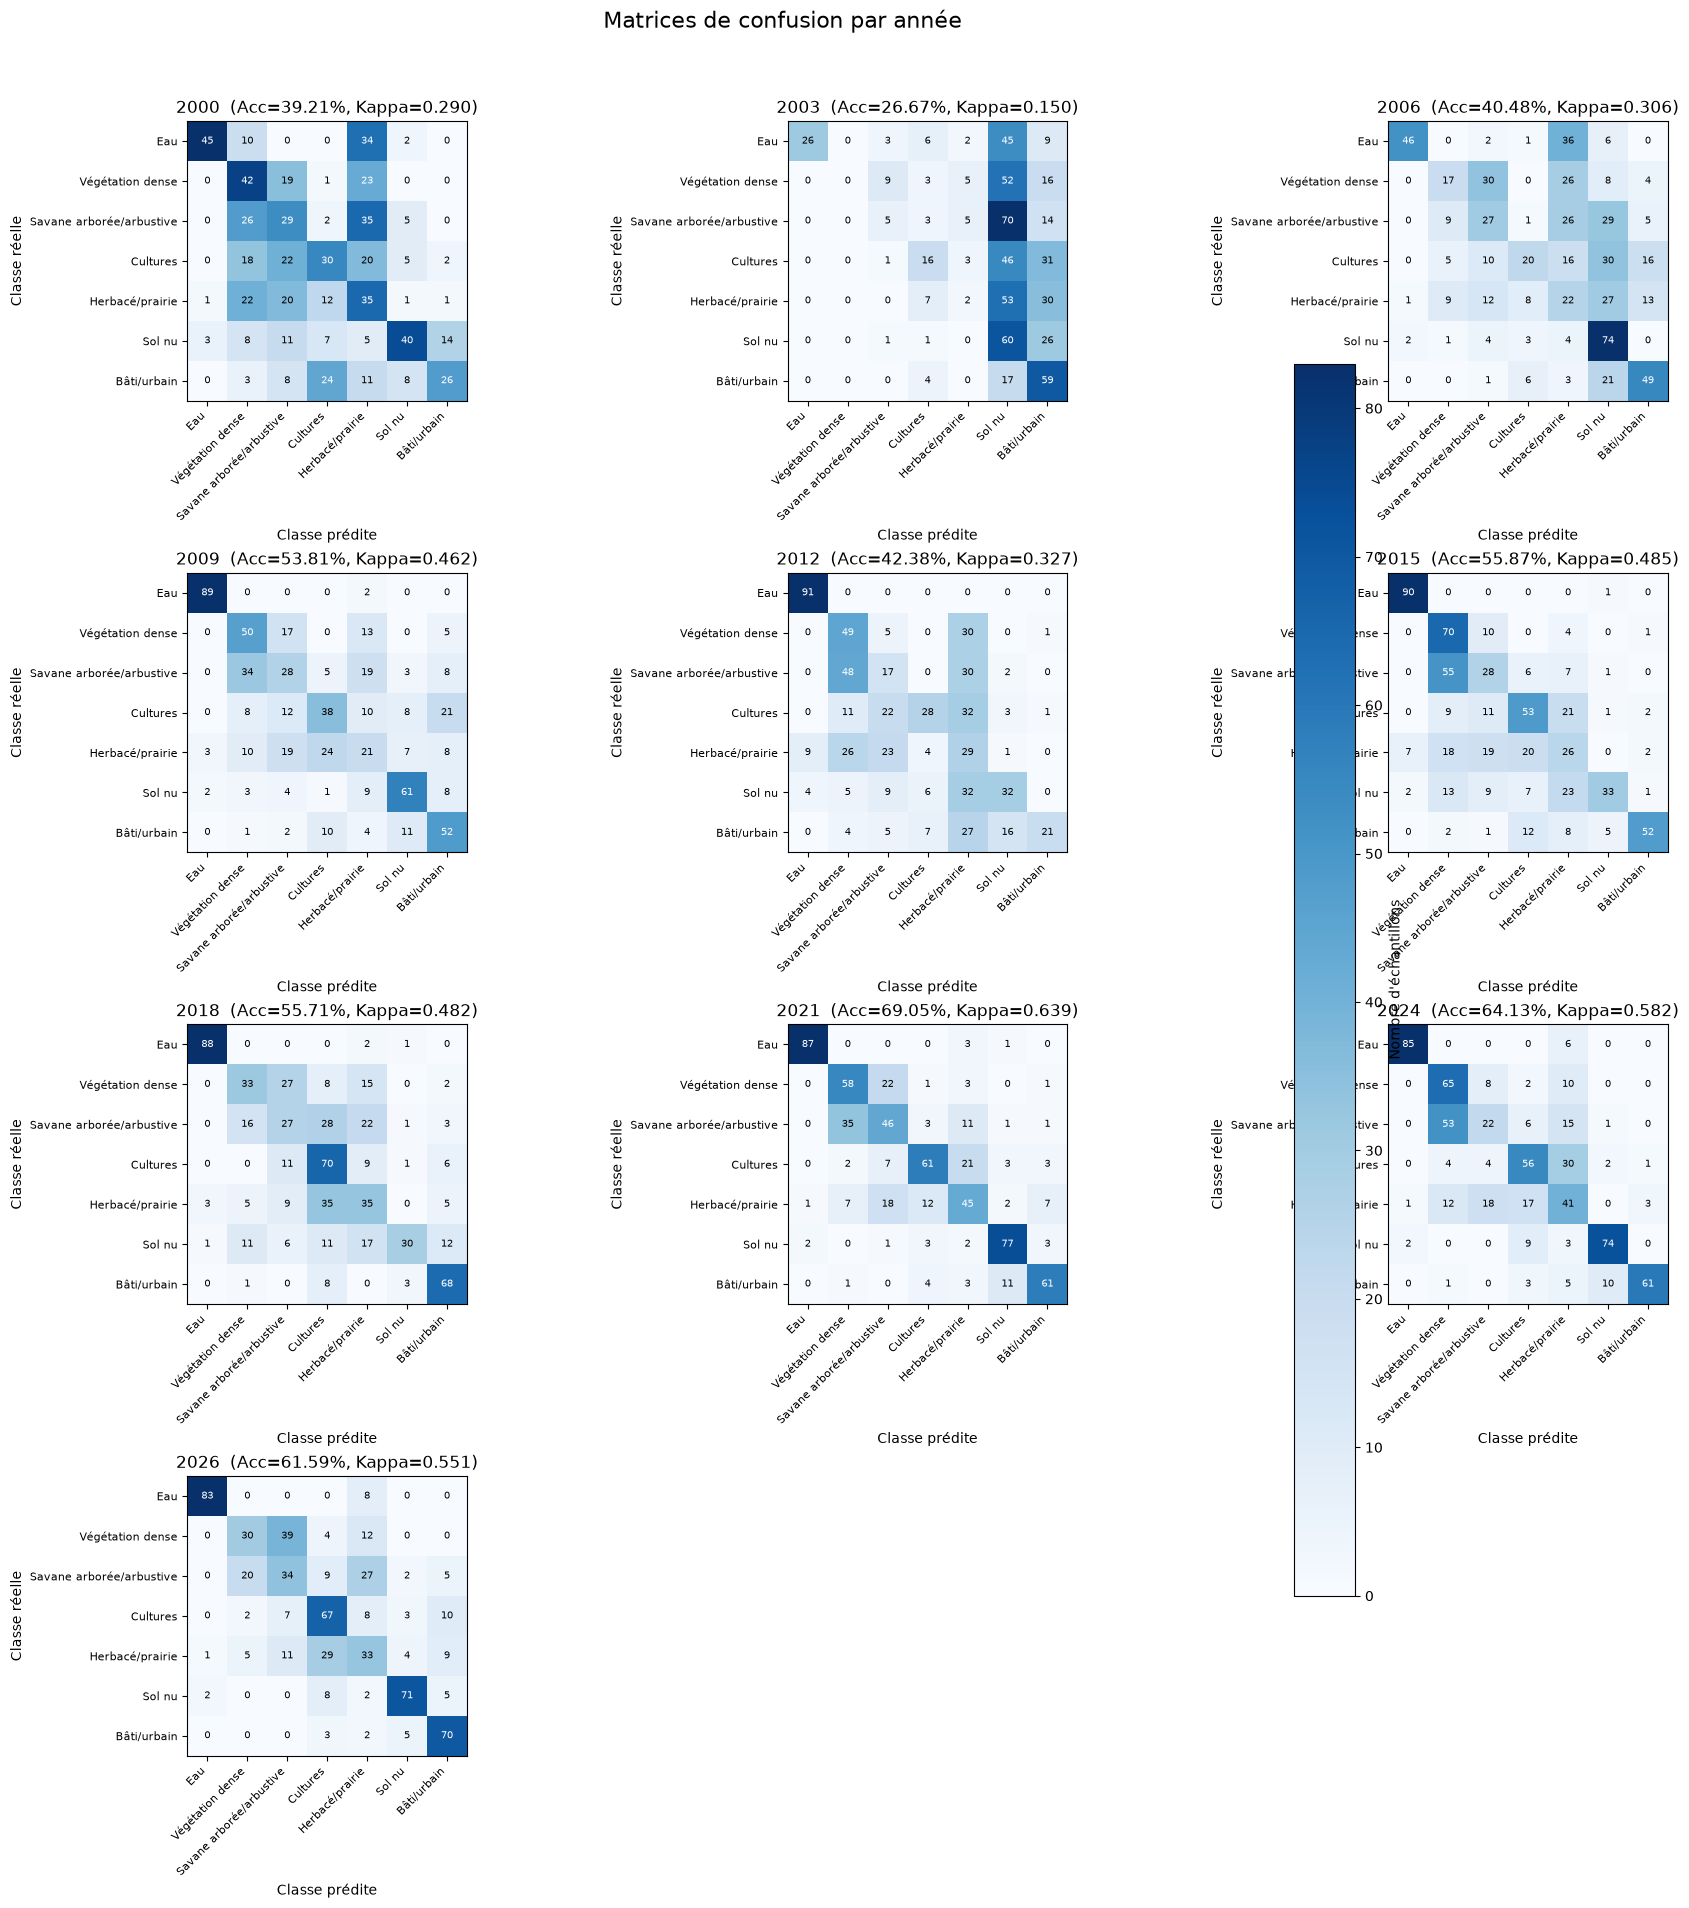

In [5]:
# Matrices de confusion pour chaque année
cms = {}
accs = {}
kappas = {}

for annee in ANNEES:
    comp = composite_annuel(annee)
    pred = comp.select(BANDES_CLASS).classify(classifieur).rename('pred')
    sample = (pred.sampleRegions(
                collection=jeu_valid,
                properties=['classe'],
                scale=RESOLUTION,
                tileScale=4)
              .filter(ee.Filter.notNull(['pred'])))
    matrice = sample.errorMatrix('classe', 'pred')
    cm = np.array(matrice.getInfo())
    if cm.shape == (N_CLASSES + 1, N_CLASSES + 1):
        cm = cm[1:, 1:]
    cms[annee] = cm
    accs[annee] = matrice.accuracy().getInfo()
    kappas[annee] = matrice.kappa().getInfo()
    print(f'{annee} : précision = {accs[annee]:.3f} | kappa = {kappas[annee]:.3f}')

n = len(ANNEES)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, annee in zip(axes, ANNEES):
    cm = cms[annee]
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(f'{annee}  (Acc={accs[annee]:.2%}, Kappa={kappas[annee]:.3f})')
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(NOMS, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(NOMS, fontsize=8)
    ax.set_xlabel('Classe prédite'); ax.set_ylabel('Classe réelle')
    seuil = cm.max() / 2
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > seuil else 'black', fontsize=7)

for ax in axes[len(ANNEES):]:
    ax.axis('off')

fig.colorbar(im, ax=axes[:len(ANNEES)].tolist(), shrink=0.8, label='Nombre d\'échantillons')
fig.suptitle('Matrices de confusion par année', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.savefig(f'{DOSSIER_SORTIE}/06_matrices_confusion_par_annee.png', dpi=200)
plt.show()

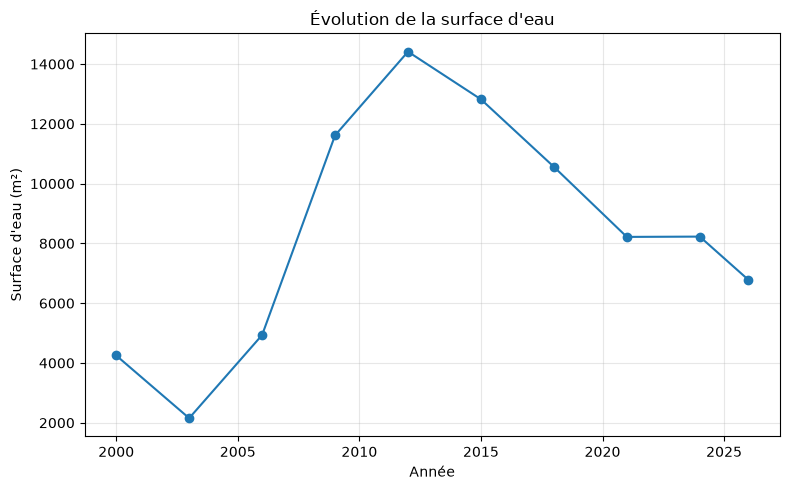

In [9]:
eau_m2 = df_surf['Eau']*10 

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(eau_m2.index, eau_m2.values, marker='o', color='#1f78b4')
ax.set_title("Évolution de la surface d'eau")
ax.set_xlabel("Année")
ax.set_ylabel("Surface d'eau (m²)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
"""
================================================================================
ANALYSE TOPO-HYDROLOGIQUE - Bassin de la KAYANGA (Anambé) - PYTHON / matplotlib
Google Earth Engine (API Python) + matplotlib
================================================================================

Produit :
  - Relief ombré + altitude, et carte de pente
  - Lignes de CRÊTES (TPI) et thalwegs
  - Réseau hydrographique (MERIT Hydro) + eau permanente
  - Zones basses / inondables (HAND)
  - Carte de synthèse (crêtes + réseau + bassins + eau sur le relief)
  - Métriques : altitude, pente, densité de drainage

PRÉREQUIS :
    pip install earthengine-api geemap rasterio matplotlib numpy scipy

Jeux de données (identifiants vérifiés) :
    SRTM 30 m          : USGS/SRTMGL1_003
    MERIT Hydro ~90 m  : MERIT/Hydro/v1_0_1  (upa, hnd, wat)
    HydroBASINS niv.8  : WWF/HydroSHEDS/v1/Basins/hybas_8
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LightSource
from matplotlib.patches import Patch
from scipy.ndimage import uniform_filter
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()   # 1re exécution
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_hydro'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMÈTRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4');

ROI = Zone_etude.geometry()

RES = 60             # m : résolution de travail pour l'analyse/affichage
RAYON_TPI_M = 500    # m : échelle des crêtes/thalwegs
SEUIL_CRETE = 4      # m : TPI mini pour une crête
SEUIL_THALWEG = -4   # m : TPI maxi pour un thalweg
SEUIL_RIVIERE = 1.0  # km² : surface drainée mini pour un cours d'eau
SEUIL_HAND = 5       # m : HAND maxi pour zone basse/inondable

# --------------------------------------------------------------------------
# 2. PILE D'IMAGES EE (bandes à projection fixe uniquement)
# --------------------------------------------------------------------------
dem = ee.Image('USGS/SRTMGL1_003').rename('elv')
merit = ee.Image('MERIT/Hydro/v1_0_1')

pile = (dem
        .addBands(merit.select('upa'))     # surface drainée amont (km²)
        .addBands(merit.select('hnd'))     # HAND (m)
        .addBands(merit.select('wat')))    # eau permanente (0/1)

# Les bassins sont traités en VECTEUR (tracés avec matplotlib), pas rasterisés
bassins = ee.FeatureCollection('WWF/HydroSHEDS/v1/Basins/hybas_8').filterBounds(ROI)

# --------------------------------------------------------------------------
# 3. TÉLÉCHARGEMENT (robuste)
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    # 1) ee_export_image (getDownloadURL) : fiable pour les petites emprises
    try:
        geemap.ee_export_image(image, filename=fn, scale=scale, region=ROI,
                               crs='EPSG:4326', file_per_band=False)
    except Exception as e:
        print(f'  ee_export_image a échoué ({e})')
    # 2) repli : download_ee_image (tuilé) si le fichier n'est pas créé
    if not os.path.exists(fn):
        try:
            geemap.download_ee_image(image, filename=fn, region=ROI,
                                     scale=scale, crs='EPSG:4326')
        except Exception as e:
            print(f'  download_ee_image a aussi échoué ({e})')
    return os.path.exists(fn)


def charger_pile(image, noms_bandes, scale):
    """Télécharge et lit la pile. Essaie en un seul fichier (toFloat pour éviter
    l'erreur de types mélangés), puis en dernier recours bande par bande."""
    fn = f'{DOSSIER}/pile_hydro.tif'
    if telecharger(image.toFloat(), fn, scale):
        with rasterio.open(fn) as src:
            return src.read().astype(float), src.transform
    # Repli : une bande à la fois (type uniforme garanti)
    print('Téléchargement combiné échoué -> tentative bande par bande...')
    arrs, transform = [], None
    for b in noms_bandes:
        fb = f'{DOSSIER}/band_{b}.tif'
        if not telecharger(image.select(b).toFloat(), fb, scale):
            raise RuntimeError(f'Échec du téléchargement de la bande {b}. '
                               'Réduis la ROI, augmente RES, ou exporte via Drive.')
        with rasterio.open(fb) as src:
            arrs.append(src.read(1).astype(float))
            transform = src.transform
    return np.stack(arrs), transform


data, transform = charger_pile(pile, ['elv', 'upa', 'hnd', 'wat'], RES)
print('Pile chargée, dimensions :', data.shape)

elv = data[0]
upa = data[1]
hnd = data[2]
wat = data[3]
elv[elv <= -1000] = np.nan            # nodata éventuel

# Récupération des limites de bassins (vecteur)
bassins_geo = bassins.getInfo()

# --------------------------------------------------------------------------
# 4. CALCULS TOPO-HYDRO (numpy)
# --------------------------------------------------------------------------
ls = LightSource(azdeg=315, altdeg=45)

# TPI = altitude - moyenne locale -> crêtes (TPI>0) / thalwegs (TPI<0)
taille = max(3, int(round(RAYON_TPI_M / RES)) * 2 + 1)
elv_rempli = np.where(np.isnan(elv), np.nanmean(elv), elv)
moy_locale = uniform_filter(elv_rempli, size=taille)
tpi = elv_rempli - moy_locale
cretes = tpi > SEUIL_CRETE
thalwegs = tpi < SEUIL_THALWEG

# Pente (degrés)
gy, gx = np.gradient(elv_rempli, RES, RES)
pente = np.degrees(np.arctan(np.sqrt(gx**2 + gy**2)))

# Réseau hydrographique : ordre approximatif par seuils de surface drainée
ordre = ((upa >= 1).astype(int) + (upa >= 10) + (upa >= 50) + (upa >= 200))
ordre = np.ma.masked_where(upa < SEUIL_RIVIERE, ordre)

# Zones basses / inondables (HAND) et eau permanente
zones_basses = np.ma.masked_where(~(hnd <= SEUIL_HAND), np.ones_like(hnd))
eau = np.ma.masked_where(wat != 1, np.ones_like(wat))

# --------------------------------------------------------------------------
# 5. MÉTRIQUES
# --------------------------------------------------------------------------
surface_km2 = ROI.area().getInfo() / 1e6
long_reseau_km = int(np.sum(upa >= SEUIL_RIVIERE)) * RES / 1000.0
densite = long_reseau_km / surface_km2
print(f'Altitude (m)  min={np.nanmin(elv):.0f}  moy={np.nanmean(elv):.0f}  max={np.nanmax(elv):.0f}')
print(f'Pente moyenne : {np.nanmean(pente):.2f} deg')
print(f'Surface ROI : {surface_km2:.0f} km2')
print(f'Longueur du reseau : {long_reseau_km:.0f} km')
print(f'Densite de drainage : {densite:.3f} km/km2')

# --------------------------------------------------------------------------
# Fonction : tracer les limites de bassins (vecteur -> pixels)
# --------------------------------------------------------------------------
def tracer_bassins(ax, geojson, transform, color='black', lw=1.2):
    for feat in geojson['features']:
        geom = feat['geometry']
        if geom['type'] == 'Polygon':
            polygones = [geom['coordinates']]
        elif geom['type'] == 'MultiPolygon':
            polygones = geom['coordinates']
        else:
            continue
        for poly in polygones:
            ring = poly[0]                       # anneau extérieur
            xs = [c[0] for c in ring]
            ys = [c[1] for c in ring]
            rows, cols = rowcol(transform, xs, ys)
            ax.plot(cols, rows, color=color, lw=lw)

# --------------------------------------------------------------------------
# 6. CARTE 1 : RELIEF + PENTE
# --------------------------------------------------------------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6))
rgb = ls.shade(elv_rempli, cmap=plt.cm.terrain, blend_mode='soft',
               vert_exag=20, dx=RES, dy=RES)
a1.imshow(rgb); a1.set_title('Relief ombre + altitude'); a1.axis('off')
im = a2.imshow(pente, cmap='YlOrRd', vmax=np.nanpercentile(pente, 98))
a2.set_title('Pente (degres)'); a2.axis('off')
fig.colorbar(im, ax=a2, shrink=0.7, label='deg')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_relief_pente.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 7. CARTE 2 : LIGNES DE CRÊTES ET THALWEGS
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(ls.hillshade(elv_rempli, vert_exag=20, dx=RES, dy=RES), cmap='gray')
ax.imshow(np.ma.masked_where(~thalwegs, np.ones_like(elv)),
          cmap=ListedColormap(['#3690c0']), alpha=0.7)
ax.imshow(np.ma.masked_where(~cretes, np.ones_like(elv)),
          cmap=ListedColormap(['#e31a1c']), alpha=0.9)
ax.set_title('Lignes de cretes (rouge) et thalwegs (bleu)'); ax.axis('off')
ax.legend(handles=[Patch(color='#e31a1c', label='Lignes de cretes'),
                   Patch(color='#3690c0', label='Thalwegs (fonds de vallee)')],
          loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/02_cretes_thalwegs.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. CARTE 3 : RÉSEAU HYDROGRAPHIQUE + ZONES BASSES (HAND)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(ls.hillshade(elv_rempli, vert_exag=20, dx=RES, dy=RES), cmap='gray')
ax.imshow(zones_basses, cmap=ListedColormap(['#41b6c4']), alpha=0.4)
ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.9)
ax.imshow(eau, cmap=ListedColormap(['#0868ac']))
ax.set_title('Reseau hydrographique + zones basses (HAND)'); ax.axis('off')
ax.legend(handles=[Patch(color='#08306b', label='Reseau (ordre croissant)'),
                   Patch(color='#0868ac', label='Eau permanente'),
                   Patch(color='#41b6c4', label=f'Zones basses (HAND<{SEUIL_HAND} m)')],
          loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_reseau_hand.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 9. CARTE 4 : SYNTHÈSE (crêtes + réseau + bassins + eau sur le relief)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(rgb)                                             # relief ombre couleur
ax.imshow(np.ma.masked_where(~cretes, np.ones_like(elv)),
          cmap=ListedColormap(['#e31a1c']), alpha=0.9)     # cretes
ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.95)  # reseau
ax.imshow(eau, cmap=ListedColormap(['#0868ac']))            # eau
tracer_bassins(ax, bassins_geo, transform, color='black', lw=1.4)  # partage des eaux
ax.set_xlim(0, elv.shape[1]); ax.set_ylim(elv.shape[0], 0)
ax.set_title('Synthese hydrologique - Bassin de la Kayanga'); ax.axis('off')
ax.legend(handles=[
    Patch(color='#e31a1c', label='Lignes de cretes'),
    Patch(color='black', label='Partage des eaux (bassins)'),
    Patch(color='#08306b', label='Reseau hydrographique'),
    Patch(color='#0868ac', label='Eau permanente')],
    loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/04_synthese_hydro.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
for f in ['01_relief_pente', '02_cretes_thalwegs',
          '03_reseau_hand', '04_synthese_hydro']:
    print(f'  {f}.png')

Generating URL ...
Please wait ...
Data downloaded to c:\Users\DELL\Downloads\sorties_hydro\pile_hydro.tif
Pile chargée, dimensions : (4, 663, 688)
Altitude (m)  min=16  moy=52  max=90
Pente moyenne : 1.33 deg
Surface ROI : 1157 km2
Longueur du reseau : 1595 km
Densite de drainage : 1.379 km/km2

Termine. Resultats dans : sorties_hydro/
  01_relief_pente.png
  02_cretes_thalwegs.png
  03_reseau_hand.png
  04_synthese_hydro.png


In [19]:
pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.5/37.4 MB 376.6 kB/s eta 0:01:38
    --------------------------------------- 0.5/37.4 MB 376.6 kB/s eta 0:01:38
    --------------------------------------- 0.5/37.4 MB 376.6 kB/s eta 0:01:38
    --------------------------------------- 0.8/37.4 MB 404.2 kB/s eta 0:01:31
    --------------------------------------- 0.8/37.4 M


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
"""
================================================================================
ANALYSE TOPO-HYDROLOGIQUE - Bassin de la KAYANGA (Anambé) - PYTHON / matplotlib
Google Earth Engine (API Python) + matplotlib
================================================================================

Produit :
  - Relief ombré + altitude, et carte de pente
  - Lignes de CRÊTES (TPI) et thalwegs
  - Réseau hydrographique (MERIT Hydro) + eau permanente
  - Zones basses / inondables (HAND)
  - Carte de synthèse (crêtes + réseau + bassins + eau sur le relief)
  - Métriques : altitude, pente, densité de drainage

PRÉREQUIS :
    pip install earthengine-api rasterio matplotlib numpy scipy

Jeux de données (identifiants vérifiés) :
    SRTM 30 m          : USGS/SRTMGL1_003
    MERIT Hydro ~90 m  : MERIT/Hydro/v1_0_1  (upa, hnd, wat)
    HydroBASINS niv.8  : WWF/HydroSHEDS/v1/Basins/hybas_8
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LightSource
from matplotlib.patches import Patch
from scipy.ndimage import uniform_filter
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()   # 1re exécution
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_hydro'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMÈTRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4');

ROI = Zone_etude.geometry()

RES = 60             # m : résolution de travail pour l'analyse/affichage
RAYON_TPI_M = 500    # m : échelle des crêtes/thalwegs
SEUIL_CRETE = 4      # m : TPI mini pour une crête
SEUIL_THALWEG = -4   # m : TPI maxi pour un thalweg
SEUIL_RIVIERE = 1.0  # km² : surface drainée mini pour un cours d'eau
SEUIL_HAND = 5       # m : HAND maxi pour zone basse/inondable

# --------------------------------------------------------------------------
# 2. PILE D'IMAGES EE (bandes à projection fixe uniquement)
# --------------------------------------------------------------------------
dem = ee.Image('USGS/SRTMGL1_003').rename('elv')
merit = ee.Image('MERIT/Hydro/v1_0_1')

pile = (dem
        .addBands(merit.select('upa'))     # surface drainée amont (km²)
        .addBands(merit.select('hnd'))     # HAND (m)
        .addBands(merit.select('wat')))    # eau permanente (0/1)

# Les bassins sont traités en VECTEUR (tracés avec matplotlib), pas rasterisés
bassins = ee.FeatureCollection('WWF/HydroSHEDS/v1/Basins/hybas_8').filterBounds(ROI)

# --------------------------------------------------------------------------
# 3. TÉLÉCHARGEMENT (robuste)
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    """Télécharge une image EE en GeoTIFF via getDownloadURL (sans geemap).
    Affiche l'erreur exacte d'Earth Engine en cas d'échec."""
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']   # emprise en GeoJSON
    try:
        url = image.getDownloadURL({
            'scale': scale,
            'region': region,
            'crs': 'EPSG:4326',
            'format': 'GEO_TIFF'      # -> un seul GeoTIFF (pas de zip)
        })
    except Exception as e:
        print(f'  getDownloadURL a échoué : {str(e)[:400]}')
        return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print(f'  téléchargement a échoué : {str(e)[:400]}')
        return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000


def charger_pile(image, noms_bandes, scale):
    """Télécharge et lit la pile. Essaie en un seul fichier (toFloat pour éviter
    l'erreur de types mélangés), puis en dernier recours bande par bande."""
    fn = f'{DOSSIER}/pile_hydro.tif'
    if telecharger(image.toFloat(), fn, scale):
        with rasterio.open(fn) as src:
            return src.read().astype(float), src.transform
    # Repli : une bande à la fois (type uniforme garanti)
    print('Téléchargement combiné échoué -> tentative bande par bande...')
    arrs, transform = [], None
    for b in noms_bandes:
        fb = f'{DOSSIER}/band_{b}.tif'
        if not telecharger(image.select(b).toFloat(), fb, scale):
            raise RuntimeError(f'Échec du téléchargement de la bande {b}. '
                               'Réduis la ROI, augmente RES, ou exporte via Drive.')
        with rasterio.open(fb) as src:
            arrs.append(src.read(1).astype(float))
            transform = src.transform
    return np.stack(arrs), transform


data, transform = charger_pile(pile, ['elv', 'upa', 'hnd', 'wat'], RES)
print('Pile chargée, dimensions :', data.shape)

elv = data[0]
upa = data[1]
hnd = data[2]
wat = data[3]
elv[elv <= -1000] = np.nan            # nodata éventuel

# Récupération des limites de bassins (vecteur)
bassins_geo = bassins.getInfo()

# --------------------------------------------------------------------------
# 4. CALCULS TOPO-HYDRO (numpy)
# --------------------------------------------------------------------------
ls = LightSource(azdeg=315, altdeg=45)

# TPI = altitude - moyenne locale -> crêtes (TPI>0) / thalwegs (TPI<0)
taille = max(3, int(round(RAYON_TPI_M / RES)) * 2 + 1)
elv_rempli = np.where(np.isnan(elv), np.nanmean(elv), elv)
moy_locale = uniform_filter(elv_rempli, size=taille)
tpi = elv_rempli - moy_locale
cretes = tpi > SEUIL_CRETE
thalwegs = tpi < SEUIL_THALWEG

# Pente (degrés)
gy, gx = np.gradient(elv_rempli, RES, RES)
pente = np.degrees(np.arctan(np.sqrt(gx**2 + gy**2)))

# Réseau hydrographique : ordre approximatif par seuils de surface drainée
ordre = ((upa >= 1).astype(int) + (upa >= 10) + (upa >= 50) + (upa >= 200))
ordre = np.ma.masked_where(upa < SEUIL_RIVIERE, ordre)

# Zones basses / inondables (HAND) et eau permanente
zones_basses = np.ma.masked_where(~(hnd <= SEUIL_HAND), np.ones_like(hnd))
eau = np.ma.masked_where(wat != 1, np.ones_like(wat))

# --------------------------------------------------------------------------
# 5. MÉTRIQUES
# --------------------------------------------------------------------------
surface_km2 = ROI.area().getInfo() / 1e6
long_reseau_km = int(np.sum(upa >= SEUIL_RIVIERE)) * RES / 1000.0
densite = long_reseau_km / surface_km2
print(f'Altitude (m)  min={np.nanmin(elv):.0f}  moy={np.nanmean(elv):.0f}  max={np.nanmax(elv):.0f}')
print(f'Pente moyenne : {np.nanmean(pente):.2f} deg')
print(f'Surface ROI : {surface_km2:.0f} km2')
print(f'Longueur du reseau : {long_reseau_km:.0f} km')
print(f'Densite de drainage : {densite:.3f} km/km2')

# --------------------------------------------------------------------------
# Fonction : tracer les limites de bassins (vecteur -> pixels)
# --------------------------------------------------------------------------
def tracer_bassins(ax, geojson, transform, color='black', lw=1.2):
    for feat in geojson['features']:
        geom = feat['geometry']
        if geom['type'] == 'Polygon':
            polygones = [geom['coordinates']]
        elif geom['type'] == 'MultiPolygon':
            polygones = geom['coordinates']
        else:
            continue
        for poly in polygones:
            ring = poly[0]                       # anneau extérieur
            xs = [c[0] for c in ring]
            ys = [c[1] for c in ring]
            rows, cols = rowcol(transform, xs, ys)
            ax.plot(cols, rows, color=color, lw=lw)

# --------------------------------------------------------------------------
# 6. CARTE 1 : RELIEF + PENTE
# --------------------------------------------------------------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6))
rgb = ls.shade(elv_rempli, cmap=plt.cm.terrain, blend_mode='soft',
               vert_exag=20, dx=RES, dy=RES)
a1.imshow(rgb); a1.set_title('Relief ombre + altitude'); a1.axis('off')
im = a2.imshow(pente, cmap='YlOrRd', vmax=np.nanpercentile(pente, 98))
a2.set_title('Pente (degres)'); a2.axis('off')
fig.colorbar(im, ax=a2, shrink=0.7, label='deg')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_relief_pente.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 7. CARTE 2 : LIGNES DE CRÊTES ET THALWEGS
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(ls.hillshade(elv_rempli, vert_exag=20, dx=RES, dy=RES), cmap='gray')
ax.imshow(np.ma.masked_where(~thalwegs, np.ones_like(elv)),
          cmap=ListedColormap(['#3690c0']), alpha=0.7)
ax.imshow(np.ma.masked_where(~cretes, np.ones_like(elv)),
          cmap=ListedColormap(['#e31a1c']), alpha=0.9)
ax.set_title('Lignes de cretes (rouge) et thalwegs (bleu)'); ax.axis('off')
ax.legend(handles=[Patch(color='#e31a1c', label='Lignes de cretes'),
                   Patch(color='#3690c0', label='Thalwegs (fonds de vallee)')],
          loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/02_cretes_thalwegs.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. CARTE 3 : RÉSEAU HYDROGRAPHIQUE + ZONES BASSES (HAND)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(ls.hillshade(elv_rempli, vert_exag=20, dx=RES, dy=RES), cmap='gray')
ax.imshow(zones_basses, cmap=ListedColormap(['#41b6c4']), alpha=0.4)
ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.9)
ax.imshow(eau, cmap=ListedColormap(['#0868ac']))
ax.set_title('Reseau hydrographique + zones basses (HAND)'); ax.axis('off')
ax.legend(handles=[Patch(color='#08306b', label='Reseau (ordre croissant)'),
                   Patch(color='#0868ac', label='Eau permanente'),
                   Patch(color='#41b6c4', label=f'Zones basses (HAND<{SEUIL_HAND} m)')],
          loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_reseau_hand.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 9. CARTE 4 : SYNTHÈSE (crêtes + réseau + bassins + eau sur le relief)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(rgb)                                             # relief ombre couleur
ax.imshow(np.ma.masked_where(~cretes, np.ones_like(elv)),
          cmap=ListedColormap(['#e31a1c']), alpha=0.9)     # cretes
ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.95)  # reseau
ax.imshow(eau, cmap=ListedColormap(['#0868ac']))            # eau
tracer_bassins(ax, bassins_geo, transform, color='black', lw=1.4)  # partage des eaux
ax.set_xlim(0, elv.shape[1]); ax.set_ylim(elv.shape[0], 0)
ax.set_title('Synthese hydrologique - Bassin de la Kayanga'); ax.axis('off')
ax.legend(handles=[
    Patch(color='#e31a1c', label='Lignes de cretes'),
    Patch(color='black', label='Partage des eaux (bassins)'),
    Patch(color='#08306b', label='Reseau hydrographique'),
    Patch(color='#0868ac', label='Eau permanente')],
    loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/04_synthese_hydro.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
for f in ['01_relief_pente', '02_cretes_thalwegs',
          '03_reseau_hand', '04_synthese_hydro']:
    print(f'  {f}.png')

Pile chargée, dimensions : (4, 663, 688)
Altitude (m)  min=16  moy=52  max=90
Pente moyenne : 1.33 deg
Surface ROI : 1157 km2
Longueur du reseau : 1595 km
Densite de drainage : 1.379 km/km2

Termine. Resultats dans : sorties_hydro/
  01_relief_pente.png
  02_cretes_thalwegs.png
  03_reseau_hand.png
  04_synthese_hydro.png


In [12]:
"""
================================================================================
ANALYSE TOPO-HYDROLOGIQUE - Bassin de la KAYANGA (Anambé) - PYTHON / matplotlib
Google Earth Engine (API Python) + matplotlib
================================================================================

Produit :
  - Relief ombré + altitude, et carte de pente
  - LIGNES DE CRÊTES = limites de sous-bassins fins (HydroBASINS) : vraies lignes
    de partage des eaux, continues et topologiquement correctes.
  - Réseau hydrographique (MERIT Hydro) + eau permanente
  - Zones basses / inondables (HAND)
  - Carte de synthèse (crêtes + réseau + bassins + eau sur le relief)
  - Métriques : altitude, pente, densité de drainage

PRÉREQUIS :
    pip install earthengine-api rasterio matplotlib numpy

Jeux de données (identifiants vérifiés) :
    SRTM 30 m           : USGS/SRTMGL1_003
    MERIT Hydro ~90 m   : MERIT/Hydro/v1_0_1  (upa, hnd, wat)
    HydroBASINS niv.8   : WWF/HydroSHEDS/v1/Basins/hybas_8   (bassin principal)
    HydroBASINS niv.10  : WWF/HydroSHEDS/v1/Basins/hybas_10  (crêtes internes)
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LightSource
from matplotlib.patches import Patch
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()   # 1re exécution
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_hydro'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMÈTRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4');

ROI = Zone_etude.geometry()

RES = 60             # m : résolution de travail pour l'analyse/affichage
VERT_EXAG = 4        # exagération verticale de l'ombrage (relief réel = faible)
SEUIL_RIVIERE = 1.0  # km² : surface drainée mini pour un cours d'eau
SEUIL_HAND = 5       # m : HAND maxi pour zone basse/inondable

NIVEAU_BASSIN = 8    # HydroBASINS : contour du bassin principal (Kayanga)
NIVEAU_CRETES = 10   # HydroBASINS : sous-bassins fins -> lignes de crêtes internes
                     # (mettre 12 pour des crêtes plus fines, 9 pour plus larges)

# --------------------------------------------------------------------------
# 2. PILE D'IMAGES EE (bandes à projection fixe uniquement)
# --------------------------------------------------------------------------
dem = ee.Image('USGS/SRTMGL1_003').rename('elv')
merit = ee.Image('MERIT/Hydro/v1_0_1')

pile = (dem
        .addBands(merit.select('upa'))     # surface drainée amont (km²)
        .addBands(merit.select('hnd'))     # HAND (m)
        .addBands(merit.select('wat')))    # eau permanente (0/1)

# Bassins (vecteurs) : contour principal (niv.8) + crêtes internes (niv.10)
bassins_principal = ee.FeatureCollection(
    f'WWF/HydroSHEDS/v1/Basins/hybas_{NIVEAU_BASSIN}').filterBounds(ROI)
cretes_bassins = ee.FeatureCollection(
    f'WWF/HydroSHEDS/v1/Basins/hybas_{NIVEAU_CRETES}').filterBounds(ROI)

# --------------------------------------------------------------------------
# 3. TÉLÉCHARGEMENT (robuste, via getDownloadURL)
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    """Télécharge une image EE en GeoTIFF via getDownloadURL (sans geemap)."""
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({
            'scale': scale, 'region': region,
            'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print(f'  getDownloadURL a échoué : {str(e)[:400]}')
        return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print(f'  téléchargement a échoué : {str(e)[:400]}')
        return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000


def charger_pile(image, noms_bandes, scale):
    """Télécharge et lit la pile ; repli bande par bande si besoin."""
    fn = f'{DOSSIER}/pile_hydro.tif'
    if telecharger(image.toFloat(), fn, scale):
        with rasterio.open(fn) as src:
            return src.read().astype(float), src.transform
    print('Téléchargement combiné échoué -> tentative bande par bande...')
    arrs, transform = [], None
    for b in noms_bandes:
        fb = f'{DOSSIER}/band_{b}.tif'
        if not telecharger(image.select(b).toFloat(), fb, scale):
            raise RuntimeError(f'Échec du téléchargement de la bande {b}.')
        with rasterio.open(fb) as src:
            arrs.append(src.read(1).astype(float))
            transform = src.transform
    return np.stack(arrs), transform


data, transform = charger_pile(pile, ['elv', 'upa', 'hnd', 'wat'], RES)
print('Pile chargée, dimensions :', data.shape)

elv = data[0]
upa = data[1]
hnd = data[2]
wat = data[3]
elv[elv <= -1000] = np.nan

# Limites de bassins (vecteurs)
geo_principal = bassins_principal.getInfo()
geo_cretes = cretes_bassins.getInfo()

# --------------------------------------------------------------------------
# 4. CALCULS TOPO-HYDRO (numpy)
# --------------------------------------------------------------------------
ls = LightSource(azdeg=315, altdeg=45)
elv_rempli = np.where(np.isnan(elv), np.nanmean(elv), elv)

# Pente (degrés)
gy, gx = np.gradient(elv_rempli, RES, RES)
pente = np.degrees(np.arctan(np.sqrt(gx**2 + gy**2)))

# Réseau hydrographique : ordre approximatif par seuils de surface drainée
ordre = ((upa >= 1).astype(int) + (upa >= 10) + (upa >= 50) + (upa >= 200))
ordre = np.ma.masked_where(upa < SEUIL_RIVIERE, ordre)

# Zones basses / inondables (HAND) et eau permanente
zones_basses = np.ma.masked_where(~(hnd <= SEUIL_HAND), np.ones_like(hnd))
eau = np.ma.masked_where(wat != 1, np.ones_like(wat))

# --------------------------------------------------------------------------
# 5. MÉTRIQUES
# --------------------------------------------------------------------------
surface_km2 = ROI.area().getInfo() / 1e6
long_reseau_km = int(np.sum(upa >= SEUIL_RIVIERE)) * RES / 1000.0
densite = long_reseau_km / surface_km2
print(f'Altitude (m)  min={np.nanmin(elv):.0f}  moy={np.nanmean(elv):.0f}  max={np.nanmax(elv):.0f}')
print(f'Pente moyenne : {np.nanmean(pente):.2f} deg')
print(f'Surface ROI : {surface_km2:.0f} km2')
print(f'Longueur du reseau : {long_reseau_km:.0f} km')
print(f'Densite de drainage : {densite:.3f} km/km2')

# --------------------------------------------------------------------------
# Fonction : tracer des limites de bassins (vecteur -> pixels)
# --------------------------------------------------------------------------
def tracer_limites(ax, geojson, transform, color='black', lw=1.2):
    for feat in geojson['features']:
        geom = feat['geometry']
        if geom['type'] == 'Polygon':
            polygones = [geom['coordinates']]
        elif geom['type'] == 'MultiPolygon':
            polygones = geom['coordinates']
        else:
            continue
        for poly in polygones:
            ring = poly[0]
            xs = [c[0] for c in ring]
            ys = [c[1] for c in ring]
            rows, cols = rowcol(transform, xs, ys)
            ax.plot(cols, rows, color=color, lw=lw)


def cadrer(ax):
    ax.set_xlim(0, elv.shape[1]); ax.set_ylim(elv.shape[0], 0); ax.axis('off')

# --------------------------------------------------------------------------
# 6. CARTE 1 : RELIEF + PENTE
# --------------------------------------------------------------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6))
rgb = ls.shade(elv_rempli, cmap=plt.cm.terrain, blend_mode='soft',
               vert_exag=VERT_EXAG, dx=RES, dy=RES)
a1.imshow(rgb); a1.set_title('Relief ombre + altitude'); a1.axis('off')
im = a2.imshow(pente, cmap='YlOrRd', vmax=np.nanpercentile(pente, 98))
a2.set_title('Pente (degres)'); a2.axis('off')
fig.colorbar(im, ax=a2, shrink=0.7, label='deg')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_relief_pente.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 7. CARTE 2 : LIGNES DE CRÊTES (partage des eaux fin)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(ls.hillshade(elv_rempli, vert_exag=VERT_EXAG, dx=RES, dy=RES), cmap='gray')
tracer_limites(ax, geo_cretes, transform, color='#e31a1c', lw=0.9)     # crêtes internes
tracer_limites(ax, geo_principal, transform, color='black', lw=1.8)    # bassin principal
cadrer(ax)
ax.set_title(f'Lignes de cretes = partage des eaux (HydroBASINS niv.{NIVEAU_CRETES})')
ax.legend(handles=[Patch(color='#e31a1c', label='Lignes de cretes (sous-bassins)'),
                   Patch(color='black', label='Contour du bassin principal')],
          loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/02_cretes.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. CARTE 3 : RÉSEAU HYDROGRAPHIQUE + ZONES BASSES (HAND)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(ls.hillshade(elv_rempli, vert_exag=VERT_EXAG, dx=RES, dy=RES), cmap='gray')
ax.imshow(zones_basses, cmap=ListedColormap(['#41b6c4']), alpha=0.4)
ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.9)
ax.imshow(eau, cmap=ListedColormap(['#0868ac']))
ax.set_title('Reseau hydrographique + zones basses (HAND)'); ax.axis('off')
ax.legend(handles=[Patch(color='#08306b', label='Reseau (ordre croissant)'),
                   Patch(color='#0868ac', label='Eau permanente'),
                   Patch(color='#41b6c4', label=f'Zones basses (HAND<{SEUIL_HAND} m)')],
          loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_reseau_hand.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 9. CARTE 4 : SYNTHÈSE (crêtes + réseau + bassins + eau sur le relief)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(rgb)                                              # relief ombre couleur
ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.95)  # reseau
ax.imshow(eau, cmap=ListedColormap(['#0868ac']))            # eau
tracer_limites(ax, geo_cretes, transform, color='#e31a1c', lw=0.9)     # crêtes
tracer_limites(ax, geo_principal, transform, color='black', lw=1.8)    # bassin principal
cadrer(ax)
ax.set_title('Synthese hydrologique - Bassin de la Kayanga')
ax.legend(handles=[
    Patch(color='#e31a1c', label='Lignes de cretes (partage des eaux)'),
    Patch(color='black', label='Contour du bassin principal'),
    Patch(color='#08306b', label='Reseau hydrographique'),
    Patch(color='#0868ac', label='Eau permanente')],
    loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/04_synthese_hydro.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
for f in ['01_relief_pente', '02_cretes', '03_reseau_hand', '04_synthese_hydro']:
    print(f'  {f}.png')

Pile chargée, dimensions : (4, 663, 688)
Altitude (m)  min=16  moy=52  max=90
Pente moyenne : 1.33 deg
Surface ROI : 1157 km2
Longueur du reseau : 1595 km
Densite de drainage : 1.379 km/km2

Termine. Resultats dans : sorties_hydro/
  01_relief_pente.png
  02_cretes.png
  03_reseau_hand.png
  04_synthese_hydro.png


In [14]:
"""
================================================================================
ÉVOLUTION DES BERGES DE LA KAYANGA à l'AVAL du BARRAGE DU CONFLUENT
(Anambé-Kayanga, Kolda, Sénégal) - Landsat 7/8/9 - PYTHON / matplotlib
================================================================================

Répond à l'OS1 : cartographier et quantifier l'érosion / l'accrétion des berges
à partir d'images multi-dates, EN COMPARANT PLUSIEURS SECTEURS À L'INTÉRIEUR
DE LA ZONE AVAL (selon leur distance au barrage), afin d'identifier les
secteurs les plus vulnérables (érosion la plus forte) ou les plus stables
(accrétion la plus forte).

MÉTHODE
  1. Composite Landsat de SAISON SÈCHE par an (L7 <2013, L8 2013-2022, L9 >2022).
  2. Extraction du chenal / plan d'eau par indice d'eau MNDWI (seuillage).
  3. Superposition multi-dates -> visualisation de la migration du chenal.
  4. Érosion (terre -> eau) et accrétion (eau -> terre) entre 1re et dernière année.
  5. Segmentation de la zone AVAL en NB_SECTEURS bandes selon la distance au
     barrage, et statistiques comparées (ha) par secteur.

PRÉREQUIS :
    pip install earthengine-api rasterio matplotlib numpy

Barrage du Confluent : 12.84677 N, -14.06654 E
Zone d'étude : ROI = ton shapefile aval (asset Extract_CBan11)
Données : Landsat 7/8/9 Collection 2 Level 2 (30 m)
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_berges'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMÈTRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()          # zone d'étude = AVAL uniquement

DAM_LON, DAM_LAT = -14.06654, 12.84677        # barrage du Confluent (repère, hors ROI ou en bordure)

ANNEES = list(range(2000, 2025, 3)) + [2026]   # 2000, 2003, ..., 2024, 2026
RES = 30                                        # m (résolution Landsat)
SEUIL_EAU = 0.0                                 # MNDWI : eau si > seuil
NUAGES_MAX = 40                                 # % nuages max par scène

NB_SECTEURS = 3     # <-- MODIFIE ICI le nombre de secteurs à l'intérieur de l'aval

# Fenêtre de SAISON SÈCHE (basses eaux) - stade comparable entre années
def fenetre(y):
    return f'{y}-02-01', f'{y}-05-15'

# --------------------------------------------------------------------------
# 2. SÉLECTION DU CAPTEUR + EXTRACTION DE L'EAU (MNDWI multi-capteurs)
# --------------------------------------------------------------------------
def masque_nuages(img):
    qa = img.select('QA_PIXEL')
    m = (qa.bitwiseAnd(1 << 1).eq(0)
         .And(qa.bitwiseAnd(1 << 3).eq(0))
         .And(qa.bitwiseAnd(1 << 4).eq(0)))
    return img.updateMask(m)

def collection_annee(y):
    deb, fin = fenetre(y)
    if y < 2013:
        cid = 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        cid = 'LANDSAT/LC08/C02/T1_L2'
    else:
        cid = 'LANDSAT/LC09/C02/T1_L2'
    return (ee.ImageCollection(cid)
            .filterBounds(ROI).filterDate(deb, fin)
            .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX))
            .map(masque_nuages))

def eau_annee(y):
    comp = collection_annee(y).median()
    # L7 : vert=SR_B2, swir1=SR_B5  |  L8/L9 : vert=SR_B3, swir1=SR_B6
    green, swir1 = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    mndwi = comp.normalizedDifference([green, swir1])
    return mndwi.gt(SEUIL_EAU).rename(f'eau_{y}').unmask(0).clip(ROI)

eaux = ee.Image.cat([eau_annee(y) for y in ANNEES])

def rgb_annee(y):
    comp = collection_annee(y).median()
    bandes = ['SR_B3', 'SR_B2', 'SR_B1'] if y < 2013 else ['SR_B4', 'SR_B3', 'SR_B2']
    return comp.select(bandes).multiply(0.0000275).add(-0.2).clip(ROI)

rgb_ctx = rgb_annee(ANNEES[-1])

# --------------------------------------------------------------------------
# 3. TÉLÉCHARGEMENT ROBUSTE (getDownloadURL + urllib)
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print(f'  getDownloadURL a échoué : {str(e)[:400]}')
        return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print(f'  téléchargement a échoué : {str(e)[:400]}')
        return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000

masques, transform = {}, None
for y in ANNEES:
    fn = f'{DOSSIER}/eau_{y}.tif'
    if not telecharger(eaux.select(f'eau_{y}').toFloat(), fn, RES):
        raise RuntimeError(f'Échec téléchargement eau {y}.')
    with rasterio.open(fn) as src:
        masques[y] = (src.read(1) > 0.5)
        transform = src.transform
    print(f'Masque eau {y} chargé.')

fn_rgb = f'{DOSSIER}/rgb_contexte.tif'
rgb = None
if telecharger(rgb_ctx.toFloat(), fn_rgb, RES):
    with rasterio.open(fn_rgb) as src:
        rgb = np.transpose(src.read(), (1, 2, 0))
    rgb = np.clip(rgb / 0.3, 0, 1)

H, W = masques[ANNEES[0]].shape

# --------------------------------------------------------------------------
# 4. SEGMENTATION DE LA ZONE AVAL EN SECTEURS (selon distance au barrage)
# --------------------------------------------------------------------------
# Latitude de chaque ligne de pixels (grille EPSG:4326)
lignes = np.arange(H)
lat_par_ligne = transform.f + (lignes + 0.5) * transform.e     # e < 0
lat_grille = np.repeat(lat_par_ligne[:, None], W, axis=1)

# La zone d'étude étant à l'AVAL (au sud du barrage), la distance au barrage
# augmente quand on descend vers le sud : distance = DAM_LAT - latitude
dist_barrage = np.clip(DAM_LAT - lat_grille, 0, None)   # en degrés, >= 0 dans l'aval

# Bordures de la zone réellement couverte par les données (évite les NaN/bords vides)
lat_valide = lat_par_ligne[(lat_par_ligne < DAM_LAT)]
dist_max = float(DAM_LAT - lat_valide.min()) if lat_valide.size else float(dist_barrage.max())

bornes = np.linspace(0, dist_max, NB_SECTEURS + 1)
secteur_id = np.clip(np.digitize(dist_barrage, bornes) - 1, 0, NB_SECTEURS - 1)

NOMS_SECTEURS = []
for i in range(NB_SECTEURS):
    if i == 0:
        NOMS_SECTEURS.append('Secteur 1 (proche barrage)')
    elif i == NB_SECTEURS - 1:
        NOMS_SECTEURS.append(f'Secteur {i+1} (eloigne)')
    else:
        NOMS_SECTEURS.append(f'Secteur {i+1}')

secteurs = [secteur_id == i for i in range(NB_SECTEURS)]   # liste de masques booléens
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

# Lignes de séparation entre secteurs (pour affichage), en indices de ligne (row)
lignes_bornes = []
for b in bornes[1:-1]:
    lat_b = DAM_LAT - b
    row_b = int(round((lat_b - transform.f) / transform.e))
    lignes_bornes.append(row_b)

# --------------------------------------------------------------------------
# 5. ÉROSION / ACCRÉTION (première -> dernière année)
# --------------------------------------------------------------------------
a0, a1 = ANNEES[0], ANNEES[-1]
w0, w1 = masques[a0], masques[a1]
erosion = w1 & (~w0)      # terre -> eau : le chenal s'élargit (érosion de berge)
accretion = w0 & (~w1)    # eau -> terre : dépôt / rétrécissement du chenal
duree = a1 - a0

pix_ha = (RES * RES) / 1e4     # surface d'un pixel en hectares

def bilan(masque_zone, nom):
    ero = int(np.sum(erosion & masque_zone)) * pix_ha
    acc = int(np.sum(accretion & masque_zone)) * pix_ha
    print(f'  {nom:28s} : erosion = {ero:7.1f} ha | accretion = {acc:7.1f} ha '
          f'| net = {ero - acc:+7.1f} ha  (sur {duree} ans)')
    return ero, acc

print(f'\n=== BILAN ÉROSION / ACCRÉTION PAR SECTEUR (zone AVAL) {a0} -> {a1} ===')
resultats = [bilan(m, nom) for m, nom in zip(secteurs, NOMS_SECTEURS)]
eros = [r[0] for r in resultats]
accs = [r[1] for r in resultats]

secteur_max_erosion = NOMS_SECTEURS[int(np.argmax(eros))]
secteur_max_accretion = NOMS_SECTEURS[int(np.argmax(accs))]
print(f'\n  -> Secteur le plus VULNÉRABLE (érosion max)  : {secteur_max_erosion}')
print(f'  -> Secteur avec le plus d\'ACCRÉTION (avancée) : {secteur_max_accretion}')

# --------------------------------------------------------------------------
# 6. CARTE 1 : MIGRATION DU CHENAL (superposition multi-dates)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
if rgb is not None:
    ax.imshow(rgb)
couleurs = plt.cm.viridis(np.linspace(0, 1, len(ANNEES)))
for y, c in zip(ANNEES, couleurs):
    ax.imshow(np.ma.masked_where(~masques[y], np.ones((H, W))),
              cmap=ListedColormap([c]), alpha=0.5)
ax.plot(dam_col, dam_row, 'r^', ms=12)
ax.text(dam_col + 8, dam_row, 'Barrage', color='red', fontsize=10, va='center')
for rb, nom in zip(lignes_bornes, NOMS_SECTEURS[:-1]):
    ax.axhline(rb, color='white', lw=1, ls='--', alpha=0.7)
for i, nom in enumerate(NOMS_SECTEURS):
    ligne_centre = int(np.mean(np.where(secteurs[i].any(axis=1))[0])) if secteurs[i].any() else H // (NB_SECTEURS+1) * (i+1)
    ax.text(5, ligne_centre, nom, color='white', fontsize=9, weight='bold')
ax.set_title('Migration du chenal de la Kayanga - secteur AVAL (Landsat, saison seche)')
ax.axis('off')
ax.legend(handles=[Patch(color=couleurs[i], label=str(y))
                   for i, y in enumerate(ANNEES)],
          loc='lower center', ncol=min(len(ANNEES), 6), bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_migration_chenal.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 7. CARTE 2 : ÉROSION / ACCRÉTION (avec limites de secteurs)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
if rgb is not None:
    ax.imshow(rgb * 0.6)
ax.imshow(np.ma.masked_where(~(w0 | w1), np.ones((H, W))),
          cmap=ListedColormap(['#3a7ca5']), alpha=0.35)   # chenal (union)
ax.imshow(np.ma.masked_where(~erosion, np.ones((H, W))),
          cmap=ListedColormap(['#e31a1c']))                # erosion
ax.imshow(np.ma.masked_where(~accretion, np.ones((H, W))),
          cmap=ListedColormap(['#33a02c']))                # accretion
ax.plot(dam_col, dam_row, 'y^', ms=12)
for rb in lignes_bornes:
    ax.axhline(rb, color='yellow', lw=1, ls='--', alpha=0.8)
ax.set_title(f'Erosion (rouge) et accretion (vert) par secteur - zone AVAL  {a0} -> {a1}')
ax.axis('off')
ax.legend(handles=[Patch(color='#e31a1c', label='Erosion (chenal elargi)'),
                   Patch(color='#33a02c', label='Accretion (depot)'),
                   Patch(color='#3a7ca5', label='Chenal')],
          loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/02_erosion_accretion.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. GRAPHIQUE : BILAN COMPARÉ PAR SECTEUR (zone AVAL)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(NB_SECTEURS)
larg = 0.35
ax.bar(x - larg/2, eros, larg, label='Erosion', color='#e31a1c')
ax.bar(x + larg/2, accs, larg, label='Accretion', color='#33a02c')
ax.set_xticks(x)
ax.set_xticklabels(NOMS_SECTEURS, rotation=15, ha='right')
ax.set_ylabel('Surface (ha)')
ax.set_title(f'Bilan erosion / accretion par secteur - zone AVAL ({a0}-{a1})')
ax.legend()
for i, (e, a) in enumerate(zip(eros, accs)):
    ax.text(i - larg/2, e, f'{e:.0f}', ha='center', va='bottom', fontsize=9)
    ax.text(i + larg/2, a, f'{a:.0f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_bilan_secteurs_aval.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
for f in ['01_migration_chenal', '02_erosion_accretion', '03_bilan_secteurs_aval']:
    print(f'  {f}.png')

Masque eau 2000 chargé.
Masque eau 2003 chargé.
Masque eau 2006 chargé.
Masque eau 2009 chargé.
Masque eau 2012 chargé.
Masque eau 2015 chargé.
Masque eau 2018 chargé.
Masque eau 2021 chargé.
Masque eau 2024 chargé.
Masque eau 2026 chargé.

=== BILAN ÉROSION / ACCRÉTION PAR SECTEUR (zone AVAL) 2000 -> 2026 ===
  Secteur 1 (proche barrage)   : erosion =   322.1 ha | accretion =   205.4 ha | net =  +116.7 ha  (sur 26 ans)
  Secteur 2                    : erosion =     0.0 ha | accretion =     0.0 ha | net =    +0.0 ha  (sur 26 ans)
  Secteur 3 (eloigne)          : erosion =     0.0 ha | accretion =     0.0 ha | net =    +0.0 ha  (sur 26 ans)

  -> Secteur le plus VULNÉRABLE (érosion max)  : Secteur 1 (proche barrage)
  -> Secteur avec le plus d'ACCRÉTION (avancée) : Secteur 1 (proche barrage)

Termine. Resultats dans : sorties_berges/
  01_migration_chenal.png
  02_erosion_accretion.png
  03_bilan_secteurs_aval.png


In [35]:
%pip install scikit-image

   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.0 MB 1.6 MB/s eta 0:00:08
   - -------------------------------------- 0.5/12.0 MB 1.6 MB/s eta 0:00:08
   - -------------------------------------- 0.5/12.0 MB 1.6 MB/s eta 0:00:08
   - -------------------------------------- 0.5/12.0 MB 1.6 MB/s eta 0:00:08
   - -------------------------------------- 0.5/12.0 MB 1.6 MB/s eta 0:00:08
   -- ------------------------------------- 0.8/12.0 MB 423.9 kB/s eta 0:00:27
   --- ------------------------------------ 1.0/12.0 MB 549.2 kB/s eta 0:00:20
   ---- ----------------------------------- 1.3/12.0 MB 635.3 kB/s eta 0:00:17
   ---- ----------------------------------- 1.3/12.0 MB 635.3 kB/s eta 0:00:17
   ----- ---------------------------------- 1.6/12.0 MB 639.2 kB/s eta 0:00:17
   ------ 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
"""
================================================================================
DSAS - TAUX D'ÉROSION DES BERGES DE LA KAYANGA (m/an) autour du BARRAGE DU CONFLUENT
Analyse par transects perpendiculaires + volet historique - PYTHON / matplotlib
================================================================================

VOLET A (principal) : Sentinel-2 (10 m), 2016-2025
  - Extraction du chenal (MNDWI) chaque annee de saison seche.
  - Axe central du fleuve construit automatiquement (squelette du chenal).
  - Transects perpendiculaires reguliers ; a chaque transect on mesure la
    position de la RIVE GAUCHE et de la RIVE DROITE chaque annee.
  - Taux de deplacement de berge : EPR (point a point) et LRR (regression),
    en m/an, separement par rive et par secteur AMONT / AVAL du barrage.

VOLET B (contexte historique) : Landsat 5/7 (30 m), 1990-2010
  - Contours du chenal aux dates anciennes, superposes (deplacement long terme).
  - Resolution 30 m : contexte decennal, pas mesure fine.

PREREQUIS :
    pip install earthengine-api rasterio matplotlib numpy scipy scikit-image networkx

Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.stats import linregress
from skimage.morphology import skeletonize
from skimage.measure import find_contours
import networkx as nx
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_dsas'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMETRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()          # zone d'étude = AVAL uniquement

DAM_LON, DAM_LAT = -14.06654, 12.84677   # barrage (repère pour la carte, hors zone de calcul)

ANNEES = list(range(2000, 2025, 3)) + [2026]   # 2000, 2003, ..., 2024, 2026 (volet A)
ANNEES_HIST = [1990, 2000, 2010]          # Landsat (contexte historique, volet B)
RES = 30                                   # m (Landsat, remplace Sentinel-2)
RES_HIST = 30                              # m (Landsat) - inchangé
SEUIL_EAU = 0.0                            # MNDWI : eau si > seuil
NUAGES_MAX = 40
ESPACEMENT_TRANSECTS_M = 200               # distance entre transects le long du fleuve
MAX_DEMI_LARGEUR_M = 1200                  # longueur max d'un demi-transect (censure)
LISSAGE_AXE = 7                            # fenetre de lissage de l'axe central

def fenetre(y):
    return f'{y}-02-01', f'{y}-05-15'      # saison seche (etiage)

# --------------------------------------------------------------------------
# 2. EXTRACTION DE L'EAU
# --------------------------------------------------------------------------
def eau_annee(y):
    deb, fin = fenetre(y)
    def mask(img):
        qa = img.select('QA_PIXEL')
        return img.updateMask(qa.bitwiseAnd(1 << 1).eq(0)
                              .And(qa.bitwiseAnd(1 << 3).eq(0))
                              .And(qa.bitwiseAnd(1 << 4).eq(0)))
    if y < 2013:
        cid = 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        cid = 'LANDSAT/LC08/C02/T1_L2'
    else:
        cid = 'LANDSAT/LC09/C02/T1_L2'
    col = (ee.ImageCollection(cid)
           .filterBounds(ROI).filterDate(deb, fin)
           .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX)).map(mask))
    green, swir1 = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    mndwi = col.median().normalizedDifference([green, swir1])
    return mndwi.gt(SEUIL_EAU).rename(f'eau_{y}').unmask(0).clip(ROI)

def eau_landsat(y):
    deb, fin = fenetre(y)
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0))
             .And(qa.bitwiseAnd(1 << 4).eq(0)))
        sr = img.select('SR_B.').multiply(0.0000275).add(-0.2)
        return sr.updateMask(m)
    def f(cid):
        return (ee.ImageCollection(cid).filterBounds(ROI).filterDate(deb, fin)
                .filter(ee.Filter.lt('CLOUD_COVER', 60)).map(prep))
    col = f('LANDSAT/LT05/C02/T1_L2').merge(f('LANDSAT/LT05/C02/T2_L2')) \
          .merge(f('LANDSAT/LE07/C02/T1_L2')).merge(f('LANDSAT/LE07/C02/T2_L2'))
    mndwi = col.median().normalizedDifference(['SR_B2', 'SR_B5'])  # vert / MIR1
    return mndwi.gt(SEUIL_EAU).rename(f'eauH_{y}').unmask(0)

# --------------------------------------------------------------------------
# 3. TELECHARGEMENT
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print(f'  getDownloadURL a echoue : {str(e)[:300]}'); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print(f'  telechargement a echoue : {str(e)[:300]}'); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000

masques, transform = {}, None
for y in ANNEES:
    fn = f'{DOSSIER}/eau_{y}.tif'
    if not telecharger(eau_annee(y).toFloat(), fn, RES):
        raise RuntimeError(f'Echec telechargement eau {y}.')
    with rasterio.open(fn) as src:
        masques[y] = (src.read(1) > 0.5)
        transform = src.transform
    print(f'Masque eau {y} charge.')

H, W = masques[ANNEES[0]].shape

# --------------------------------------------------------------------------
# 4. AXE CENTRAL DU FLEUVE (squelette du chenal principal)
# --------------------------------------------------------------------------
union = np.zeros((H, W), bool)
for y in ANNEES:
    union |= masques[y]

# On garde la plus grande composante connexe (chenal principal + retenue)
lab, n = ndimage.label(union)
if n == 0:
    raise RuntimeError('Aucun pixel d\'eau detecte.')
tailles = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
principal = (lab == (np.argmax(tailles) + 1))

squelette = skeletonize(principal)

# Graphe du squelette -> axe central = plus long chemin (diametre)
coords = np.argwhere(squelette)
sset = set(map(tuple, coords))
G = nx.Graph()
for (r, c) in coords:
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr or dc:
                nb = (r + dr, c + dc)
                if nb in sset:
                    G.add_edge((r, c), nb, weight=float(np.hypot(dr, dc)))

def plus_loin(src):
    d = nx.single_source_dijkstra_path_length(G, src)
    node = max(d, key=d.get)
    return node, d[node]

depart = next(iter(G.nodes))
u, _ = plus_loin(depart)
v, _ = plus_loin(u)
axe = np.array(nx.dijkstra_path(G, u, v))     # liste ordonnee (row, col)

# Lissage de l'axe (moyenne glissante) pour des perpendiculaires stables
def lisser(a, k):
    if len(a) < k:
        return a
    ker = np.ones(k) / k
    r = np.convolve(a[:, 0], ker, 'same')
    c = np.convolve(a[:, 1], ker, 'same')
    out = np.column_stack([r, c])
    out[:k], out[-k:] = a[:k], a[-k:]         # bords non lisses
    return out

axe = lisser(axe.astype(float), LISSAGE_AXE)

# --------------------------------------------------------------------------
# 5. TRANSECTS + MESURE DES RIVES
# --------------------------------------------------------------------------
pas = max(1, int(round(ESPACEMENT_TRANSECTS_M / RES)))
idx = np.arange(0, len(axe), pas)
max_pas = int(round(MAX_DEMI_LARGEUR_M / RES))

def distance_rive(mask, r0, c0, dr, dc):
    """Distance (en pixels) du centre a la 1re berge dans la direction (dr,dc)."""
    for s in range(max_pas):
        r = int(round(r0 + dr * s)); c = int(round(c0 + dc * s))
        if r < 0 or r >= H or c < 0 or c >= W:
            return s
        if s == 0 and not mask[r, c]:
            return np.nan                      # centre hors eau cette annee
        if not mask[r, c]:
            return s
    return np.nan                              # berge non trouvee (censure)

transects = []
for i in idx:
    r0, c0 = axe[i]
    j0, j1 = max(0, i - pas), min(len(axe) - 1, i + pas)
    tan = axe[j1] - axe[j0]
    norme = np.hypot(*tan)
    if norme == 0:
        continue
    perp = np.array([-tan[1], tan[0]]) / norme     # perpendiculaire unitaire
    lat = transform.f + (r0 + 0.5) * transform.e
    secteur = 'AVAL'   # tous les transects sont dans la zone aval (ROI = shapefile aval)
    dist_g, dist_d = {}, {}
    for y in ANNEES:
        dg = distance_rive(masques[y], r0, c0, perp[0], perp[1])
        dd = distance_rive(masques[y], r0, c0, -perp[0], -perp[1])
        dist_g[y] = dg * RES if np.isfinite(dg) else np.nan
        dist_d[y] = dd * RES if np.isfinite(dd) else np.nan
    transects.append({'i': i, 'r': r0, 'c': c0, 'lat': lat, 'secteur': secteur,
                      'perp': perp, 'g': dist_g, 'd': dist_d})

# Taux de deplacement par rive : EPR (point-a-point) et LRR (regression)
def taux(dists):
    ys = [y for y in ANNEES if np.isfinite(dists[y])]
    if len(ys) < 2:
        return np.nan, np.nan
    epr = (dists[ys[-1]] - dists[ys[0]]) / (ys[-1] - ys[0])
    lrr = linregress(ys, [dists[y] for y in ys]).slope
    return epr, lrr

for t in transects:
    t['epr_g'], t['lrr_g'] = taux(t['g'])
    t['epr_d'], t['lrr_d'] = taux(t['d'])
    # taux moyen d'erosion de berge (positif = recul/elargissement)
    vals = [v for v in [t['epr_g'], t['epr_d']] if np.isfinite(v)]
    t['epr_moy'] = np.mean(vals) if vals else np.nan

# --------------------------------------------------------------------------
# 6. STATISTIQUES AMONT / AVAL
# --------------------------------------------------------------------------
def stats(secteur):
    eprs = [t['epr_moy'] for t in transects
            if t['secteur'] == secteur and np.isfinite(t['epr_moy'])]
    if not eprs:
        return None
    eprs = np.array(eprs)
    return dict(n=len(eprs), moy=eprs.mean(), med=np.median(eprs),
                ero=eprs[eprs > 0].mean() if np.any(eprs > 0) else 0,
                acc=eprs[eprs < 0].mean() if np.any(eprs < 0) else 0)

print(f'\n=== TAUX DE DEPLACEMENT DES BERGES (m/an), {ANNEES[0]}-{ANNEES[-1]} (zone AVAL) ===')
print('(EPR positif = recul de berge / elargissement du chenal = EROSION)')
s = stats('AVAL')
if s:
    print(f'  AVAL   : {s["n"]:3d} transects | moyenne = {s["moy"]:+.2f} m/an '
          f'| mediane = {s["med"]:+.2f} | erosion moy = {s["ero"]:+.2f} '
          f'| accretion moy = {s["acc"]:+.2f}')

# Export CSV des transects
import csv
try:
    with open(f'{DOSSIER}/transects_taux.csv', 'w', newline='') as fcsv:
        w = csv.writer(fcsv)
        w.writerow(['id', 'lat', 'secteur', 'EPR_rive_gauche', 'EPR_rive_droite',
                    'LRR_gauche', 'LRR_droite', 'EPR_moyen'])
        for k, t in enumerate(transects):
            w.writerow([k, f'{t["lat"]:.5f}', t['secteur'],
                        f'{t["epr_g"]:.3f}', f'{t["epr_d"]:.3f}',
                        f'{t["lrr_g"]:.3f}', f'{t["lrr_d"]:.3f}', f'{t["epr_moy"]:.3f}'])

except PermissionError:
    print("Le fichier transects_taux.csv est ouvert ailleurs (Excel ?) - ferme-le puis relance cette cellule.")
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

# --------------------------------------------------------------------------
# 7. CARTE : TRANSECTS COLORES PAR TAUX D'EROSION
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.ma.masked_where(~union, np.ones((H, W))),
          cmap=ListedColormap(['#cfe8f3']))
ax.plot(axe[:, 1], axe[:, 0], color='#555555', lw=1, label='Axe du fleuve')
vmax = np.nanpercentile([abs(t['epr_moy']) for t in transects
                         if np.isfinite(t['epr_moy'])] or [1], 90)

for t in transects:
    if not np.isfinite(t['epr_moy']):
        continue
    L = 12
    p = t['perp'] * L
    x = [t['c'] - p[1], t['c'] + p[1]]
    yv = [t['r'] - p[0], t['r'] + p[0]]
    val = np.clip(t['epr_moy'] / (vmax if vmax else 1), -1, 1)
    col = plt.cm.RdBu_r((val + 1) / 2)         # rouge = erosion, bleu = accretion
    ax.plot(x, yv, color=col, lw=2.5)
ax.axhline(dam_row, color='black', lw=1.2, ls='--')
ax.plot(dam_col, dam_row, 'k^', ms=12)
ax.text(dam_col + 4, dam_row, 'Barrage', fontsize=10, va='center')
ax.text(5, 12, 'AMONT', fontsize=12, weight='bold')
ax.text(5, H - 12, 'AVAL', fontsize=12, weight='bold', va='bottom')
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title(f'Taux de deplacement des berges par transect (m/an)  '
             f'{ANNEES[0]}-{ANNEES[-1]}')
sm = plt.cm.ScalarMappable(cmap='RdBu_r',
                           norm=plt.Normalize(-vmax, vmax))
fig.colorbar(sm, ax=ax, shrink=0.6, label='m/an  (rouge=erosion, bleu=accretion)')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_transects_taux.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. GRAPHIQUE : DISTRIBUTION DES TAUX AMONT vs AVAL (boxplot)
# --------------------------------------------------------------------------
dv = [t['epr_moy'] for t in transects if np.isfinite(t['epr_moy'])]
fig, ax = plt.subplots(figsize=(6, 6))
if v:
    bp = ax.boxplot(v, tick_labels=[f'AVAL\n(n={len(v)})'], patch_artist=True, showmeans=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#74add1')
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_ylabel('Taux de deplacement de berge (m/an)')
    ax.set_title(f'Distribution des taux de deplacement des berges - zone AVAL '
                 f'({ANNEES[0]}-{ANNEES[-1]})')
    plt.tight_layout()
    plt.savefig(f'{DOSSIER}/02_boxplot_aval.png', dpi=200, bbox_inches='tight')
else:
    print('Aucun transect valide pour le boxplot.')
plt.close()

# --------------------------------------------------------------------------
# 9. VOLET B : CONTOURS HISTORIQUES DU CHENAL (Landsat 1990-2010)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.ma.masked_where(~masques[ANNEES[-1]], np.ones((H, W))),
          cmap=ListedColormap(['#cfe8f3']))
couleurs_h = plt.cm.autumn(np.linspace(0, 0.8, len(ANNEES_HIST)))
trace_hist = False
for y, c in zip(ANNEES_HIST, couleurs_h):
    fnh = f'{DOSSIER}/eauH_{y}.tif'
    ok = telecharger(eau_landsat(y).toFloat(), fnh, RES_HIST)
    if not ok:
        print(f'  (historique {y} indisponible)')
        continue
    with rasterio.open(fnh) as src:
        mh = src.read(1) > 0.5
    # redimensionnement grossier a la grille S2 pour superposition
    mh_big = np.kron(mh, np.ones((RES_HIST // RES, RES_HIST // RES)))[:H, :W]
    for ct in find_contours(mh_big.astype(float), 0.5):
        ax.plot(ct[:, 1], ct[:, 0], color=c, lw=1.2)
    trace_hist = True
# contour recent pour comparaison
for ct in find_contours(masques[ANNEES[-1]].astype(float), 0.5):
    ax.plot(ct[:, 1], ct[:, 0], color='blue', lw=1.0)
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)
ax.plot(dam_col, dam_row, 'k^', ms=12)
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title('Deplacement historique du chenal (Landsat 30 m, contexte)')
handles = [Patch(color=couleurs_h[i], label=str(y)) for i, y in enumerate(ANNEES_HIST)]
handles.append(Patch(color='blue', label=str(ANNEES[-1]) + ' (S2)'))
ax.legend(handles=handles, loc='lower center', ncol=len(handles),
          bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_historique_chenal.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
print('  01_transects_taux.png     (taux m/an par transect)')
print('  02_boxplot_amont_aval.png (distribution amont vs aval)')
print('  03_historique_chenal.png  (contexte Landsat 1990-2010)')
print('  transects_taux.csv        (tableau des taux par transect)')

Masque eau 2000 charge.
Masque eau 2003 charge.
Masque eau 2006 charge.
Masque eau 2009 charge.
Masque eau 2012 charge.
Masque eau 2015 charge.
Masque eau 2018 charge.
Masque eau 2021 charge.
Masque eau 2024 charge.
Masque eau 2026 charge.

=== TAUX DE DEPLACEMENT DES BERGES (m/an), 2000-2026 (zone AVAL) ===
(EPR positif = recul de berge / elargissement du chenal = EROSION)
  AVAL   :  64 transects | moyenne = -1.41 m/an | mediane = +0.00 | erosion moy = +7.53 | accretion moy = -10.99
  getDownloadURL a echoue : Image.normalizedDifference: No band named 'SR_B2'. Available band names: [].
  (historique 1990 indisponible)

Termine. Resultats dans : sorties_dsas/
  01_transects_taux.png     (taux m/an par transect)
  02_boxplot_amont_aval.png (distribution amont vs aval)
  03_historique_chenal.png  (contexte Landsat 1990-2010)
  transects_taux.csv        (tableau des taux par transect)


In [4]:
"""
================================================================================
DSAS - TAUX D'ÉROSION DES BERGES DE LA KAYANGA (m/an) autour du BARRAGE DU CONFLUENT
Analyse par transects perpendiculaires + volet historique - PYTHON / matplotlib
================================================================================

VOLET A (principal) : Sentinel-2 (10 m), 2016-2025
  - Extraction du chenal (MNDWI) chaque annee de saison seche.
  - Axe central du fleuve construit automatiquement (squelette du chenal).
  - Transects perpendiculaires reguliers ; a chaque transect on mesure la
    position de la RIVE GAUCHE et de la RIVE DROITE chaque annee.
  - Taux de deplacement de berge : EPR (point a point) et LRR (regression),
    en m/an, separement par rive et par secteur AMONT / AVAL du barrage.

VOLET B (contexte historique) : Landsat 5/7 (30 m), 1990-2010
  - Contours du chenal aux dates anciennes, superposes (deplacement long terme).
  - Resolution 30 m : contexte decennal, pas mesure fine.

PREREQUIS :
    pip install earthengine-api rasterio matplotlib numpy scipy scikit-image networkx

Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.stats import linregress, mannwhitneyu
from skimage.morphology import skeletonize
from skimage.measure import find_contours
import networkx as nx
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_dsas'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMETRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()          # zone d'étude = AVAL uniquement

DAM_LON, DAM_LAT = -14.06654, 12.84677   # barrage (repère pour la carte)

ANNEES = list(range(2000, 2025, 3)) + [2026]   # 2000, 2003, ..., 2024, 2026
ANNEES_HIST = [1990, 2000, 2010]          # Landsat (contexte historique) - inchangé
RES = 30                                   # m (Landsat, remplace Sentinel-2)
RES_HIST = 30                              # inchangé                             # m (Landsat)
SEUIL_EAU = 0.0                            # MNDWI : eau si > seuil
NUAGES_MAX = 40

ESPACEMENT_TRANSECTS_M = 200               # distance entre transects le long du fleuve
MAX_DEMI_LARGEUR_M = 1200                  # longueur max d'un demi-transect (censure)
LISSAGE_AXE = 7                            # fenetre de lissage de l'axe central

# Fenetre saisonniere RESSERREE : meme periode courte chaque annee (fin de saison
# seche, plan d'eau au plus bas et stable) -> minimise l'effet du niveau d'eau.
FENETRE_DEB, FENETRE_FIN = '01-01', '05-01'   # avril (elargir si trop peu de scenes)

def fenetre(y):
    return f'{y}-{FENETRE_DEB}', f'{y}-{FENETRE_FIN}'

# --------------------------------------------------------------------------
# 2. EXTRACTION DE L'EAU
# --------------------------------------------------------------------------
def eau_annee(y):
    deb, fin = fenetre(y)
    def mask(img):
        qa = img.select('QA_PIXEL')
        return img.updateMask(qa.bitwiseAnd(1 << 1).eq(0)
                              .And(qa.bitwiseAnd(1 << 3).eq(0))
                              .And(qa.bitwiseAnd(1 << 4).eq(0)))
    if y < 2013:
        cid = 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        cid = 'LANDSAT/LC08/C02/T1_L2'
    else:
        cid = 'LANDSAT/LC09/C02/T1_L2'
    col = (ee.ImageCollection(cid)
           .filterBounds(ROI).filterDate(deb, fin)
           .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX)).map(mask))
    green, swir1 = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    mndwi = col.median().normalizedDifference([green, swir1])
    return mndwi.gt(SEUIL_EAU).rename(f'eau_{y}').unmask(0).clip(ROI)

def eau_landsat(y):
    deb, fin = fenetre(y)
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0))
             .And(qa.bitwiseAnd(1 << 4).eq(0)))
        sr = img.select('SR_B.').multiply(0.0000275).add(-0.2)
        return sr.updateMask(m)
    def f(cid):
        return (ee.ImageCollection(cid).filterBounds(ROI).filterDate(deb, fin)
                .filter(ee.Filter.lt('CLOUD_COVER', 60)).map(prep))
    col = f('LANDSAT/LT05/C02/T1_L2').merge(f('LANDSAT/LT05/C02/T2_L2')) \
          .merge(f('LANDSAT/LE07/C02/T1_L2')).merge(f('LANDSAT/LE07/C02/T2_L2'))
    mndwi = col.median().normalizedDifference(['SR_B2', 'SR_B5'])  # vert / MIR1
    return mndwi.gt(SEUIL_EAU).rename(f'eauH_{y}').unmask(0)

# --------------------------------------------------------------------------
# 3. TELECHARGEMENT
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print(f'  getDownloadURL a echoue : {str(e)[:300]}'); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print(f'  telechargement a echoue : {str(e)[:300]}'); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000

masques, transform = {}, None
for y in ANNEES:
    fn = f'{DOSSIER}/eau_{y}.tif'
    if not telecharger(eau_annee(y).toFloat(), fn, RES):
        raise RuntimeError(f'Echec telechargement eau {y}.')
    with rasterio.open(fn) as src:
        masques[y] = (src.read(1) > 0.5)
        transform = src.transform
    print(f'Masque eau {y} charge.')

H, W = masques[ANNEES[0]].shape

# --------------------------------------------------------------------------
# 4. AXE CENTRAL DU FLEUVE (squelette du chenal principal)
# --------------------------------------------------------------------------
union = np.zeros((H, W), bool)
for y in ANNEES:
    union |= masques[y]
# On garde la plus grande composante connexe (chenal principal + retenue)
lab, n = ndimage.label(union)
if n == 0:
    raise RuntimeError('Aucun pixel d\'eau detecte.')
tailles = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
principal = (lab == (np.argmax(tailles) + 1))

squelette = skeletonize(principal)

# Graphe du squelette -> axe central = plus long chemin (diametre)
coords = np.argwhere(squelette)
sset = set(map(tuple, coords))
G = nx.Graph()
for (r, c) in coords:
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr or dc:
                nb = (r + dr, c + dc)
                if nb in sset:
                    G.add_edge((r, c), nb, weight=float(np.hypot(dr, dc)))

def plus_loin(src):
    d = nx.single_source_dijkstra_path_length(G, src)
    node = max(d, key=d.get)
    return node, d[node]

depart = next(iter(G.nodes))
u, _ = plus_loin(depart)
v, _ = plus_loin(u)
axe = np.array(nx.dijkstra_path(G, u, v))     # liste ordonnee (row, col)

# Lissage de l'axe (moyenne glissante) pour des perpendiculaires stables
def lisser(a, k):
    if len(a) < k:
        return a
    ker = np.ones(k) / k
    r = np.convolve(a[:, 0], ker, 'same')
    c = np.convolve(a[:, 1], ker, 'same')
    out = np.column_stack([r, c])
    out[:k], out[-k:] = a[:k], a[-k:]         # bords non lisses
    return out

axe = lisser(axe.astype(float), LISSAGE_AXE)

# --------------------------------------------------------------------------
# 5. TRANSECTS + MESURE DES RIVES
# --------------------------------------------------------------------------
pas = max(1, int(round(ESPACEMENT_TRANSECTS_M / RES)))
idx = np.arange(0, len(axe), pas)
max_pas = int(round(MAX_DEMI_LARGEUR_M / RES))

def distance_rive(mask, r0, c0, dr, dc):
    """Distance (en pixels) du centre a la 1re berge dans la direction (dr,dc)."""
    for s in range(max_pas):
        r = int(round(r0 + dr * s)); c = int(round(c0 + dc * s))
        if r < 0 or r >= H or c < 0 or c >= W:
            return s
        if s == 0 and not mask[r, c]:
            return np.nan                      # centre hors eau cette annee
        if not mask[r, c]:
            return s
    return np.nan                              # berge non trouvee (censure)

transects = []
for i in idx:
    r0, c0 = axe[i]
    j0, j1 = max(0, i - pas), min(len(axe) - 1, i + pas)
    tan = axe[j1] - axe[j0]
    norme = np.hypot(*tan)
    if norme == 0:
        continue
    perp = np.array([-tan[1], tan[0]]) / norme     # perpendiculaire unitaire
    lat = transform.f + (r0 + 0.5) * transform.e
    secteur = 'AVAL'   # tous les transects sont dans la zone aval (ROI = shapefile aval)
    dist_g, dist_d = {}, {}
    for y in ANNEES:
        dg = distance_rive(masques[y], r0, c0, perp[0], perp[1])
        dd = distance_rive(masques[y], r0, c0, -perp[0], -perp[1])
        dist_g[y] = dg * RES if np.isfinite(dg) else np.nan
        dist_d[y] = dd * RES if np.isfinite(dd) else np.nan
    transects.append({'i': i, 'r': r0, 'c': c0, 'lat': lat, 'secteur': secteur,
                      'perp': perp, 'g': dist_g, 'd': dist_d})
# Taux de deplacement par rive : EPR (point-a-point) et LRR (regression)
def taux(dists):
    ys = [y for y in ANNEES if np.isfinite(dists[y])]
    if len(ys) < 2:
        return np.nan, np.nan
    epr = (dists[ys[-1]] - dists[ys[0]]) / (ys[-1] - ys[0])
    lrr = linregress(ys, [dists[y] for y in ys]).slope
    return epr, lrr

for t in transects:
    t['epr_g'], t['lrr_g'] = taux(t['g'])
    t['epr_d'], t['lrr_d'] = taux(t['d'])
    # taux moyen d'erosion de berge (positif = recul/elargissement)
    vals = [v for v in [t['epr_g'], t['epr_d']] if np.isfinite(v)]
    t['epr_moy'] = np.mean(vals) if vals else np.nan

# --------------------------------------------------------------------------
# 6. STATISTIQUES AMONT / AVAL
# --------------------------------------------------------------------------
print(f'\n=== TAUX DE DEPLACEMENT DES BERGES (m/an), {ANNEES[0]}-{ANNEES[-1]} (zone AVAL) ===')
print('(EPR positif = recul de berge / elargissement du chenal = EROSION)')
s = stats('AVAL')
if s:
    print(f'  AVAL   : {s["n"]:3d} transects | moyenne = {s["moy"]:+.2f} m/an '
          f'| mediane = {s["med"]:+.2f} | erosion moy = {s["ero"]:+.2f} '
          f'| accretion moy = {s["acc"]:+.2f}')

p_value = None   # plus de comparaison AMONT/AVAL possible (zone unique = AVAL)

# Export CSV des transects
import csv
try:
    with open(f'{DOSSIER}/transects_taux.csv', 'w', newline='') as fcsv:
        w = csv.writer(fcsv)
        w.writerow(['id', 'lat', 'secteur', 'EPR_rive_gauche', 'EPR_rive_droite',
                    'LRR_gauche', 'LRR_droite', 'EPR_moyen'])
        for k, t in enumerate(transects):
            w.writerow([k, f'{t["lat"]:.5f}', t['secteur'],
                        f'{t["epr_g"]:.3f}', f'{t["epr_d"]:.3f}',
                        f'{t["lrr_g"]:.3f}', f'{t["lrr_d"]:.3f}', f'{t["epr_moy"]:.3f}'])
except PermissionError:
    print("Le fichier transects_taux.csv est ouvert ailleurs (Excel ?) - ferme-le puis relance cette cellule.")

dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

# --------------------------------------------------------------------------
# 7. CARTE : TRANSECTS COLORES PAR TAUX D'EROSION
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.ma.masked_where(~union, np.ones((H, W))),
          cmap=ListedColormap(['#cfe8f3']))
ax.plot(axe[:, 1], axe[:, 0], color='#555555', lw=1, label='Axe du fleuve')
vmax = np.nanpercentile([abs(t['epr_moy']) for t in transects
                         if np.isfinite(t['epr_moy'])] or [1], 90)
for t in transects:
    if not np.isfinite(t['epr_moy']):
        continue
    L = 12
    p = t['perp'] * L
    x = [t['c'] - p[1], t['c'] + p[1]]
    yv = [t['r'] - p[0], t['r'] + p[0]]
    val = np.clip(t['epr_moy'] / (vmax if vmax else 1), -1, 1)
    col = plt.cm.RdBu_r((val + 1) / 2)         # rouge = erosion, bleu = accretion
    ax.plot(x, yv, color=col, lw=2.5)
ax.axhline(dam_row, color='black', lw=1.2, ls='--')
ax.plot(dam_col, dam_row, 'k^', ms=12)
ax.text(dam_col + 4, dam_row, 'Barrage', fontsize=10, va='center')
ax.text(5, 12, 'AMONT', fontsize=12, weight='bold')
ax.text(5, H - 12, 'AVAL', fontsize=12, weight='bold', va='bottom')
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title(f'Taux de deplacement des berges par transect (m/an)  '
             f'{ANNEES[0]}-{ANNEES[-1]}')
sm = plt.cm.ScalarMappable(cmap='RdBu_r',
                           norm=plt.Normalize(-vmax, vmax))
fig.colorbar(sm, ax=ax, shrink=0.6, label='m/an  (rouge=erosion, bleu=accretion)')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_transects_taux.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. GRAPHIQUE : DISTRIBUTION DES TAUX AMONT vs AVAL (boxplot)
# --------------------------------------------------------------------------
v = [t['epr_moy'] for t in transects if np.isfinite(t['epr_moy'])]
fig, ax = plt.subplots(figsize=(6, 6))
if v:
    bp = ax.boxplot(v, tick_labels=[f'AVAL\n(n={len(v)})'], patch_artist=True, showmeans=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#74add1')
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_ylabel('Taux de deplacement de berge (m/an)')
    ax.set_title(f'Distribution des taux de deplacement des berges - zone AVAL '
                 f'({ANNEES[0]}-{ANNEES[-1]})')
    plt.tight_layout()
    plt.savefig(f'{DOSSIER}/02_boxplot_aval.png', dpi=200, bbox_inches='tight')
else:
    print('Aucun transect valide pour le boxplot.')
plt.close()
# --------------------------------------------------------------------------
# 9. VOLET B : CONTOURS HISTORIQUES DU CHENAL (Landsat 1990-2010)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.ma.masked_where(~masques[ANNEES[-1]], np.ones((H, W))),
          cmap=ListedColormap(['#cfe8f3']))
couleurs_h = plt.cm.autumn(np.linspace(0, 0.8, len(ANNEES_HIST)))
trace_hist = False
for y, c in zip(ANNEES_HIST, couleurs_h):
    fnh = f'{DOSSIER}/eauH_{y}.tif'
    ok = telecharger(eau_landsat(y).toFloat(), fnh, RES_HIST)
    if not ok:
        print(f'  (historique {y} indisponible)')
        continue
    with rasterio.open(fnh) as src:
        mh = src.read(1) > 0.5
    # redimensionnement grossier a la grille S2 pour superposition
    mh_big = np.kron(mh, np.ones((RES_HIST // RES, RES_HIST // RES)))[:H, :W]
    for ct in find_contours(mh_big.astype(float), 0.5):
        ax.plot(ct[:, 1], ct[:, 0], color=c, lw=1.2)
    trace_hist = True
# contour recent pour comparaison
for ct in find_contours(masques[ANNEES[-1]].astype(float), 0.5):
    ax.plot(ct[:, 1], ct[:, 0], color='blue', lw=1.0)
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)
ax.plot(dam_col, dam_row, 'k^', ms=12)
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title('Deplacement historique du chenal (Landsat 30 m, contexte)')
handles = [Patch(color=couleurs_h[i], label=str(y)) for i, y in enumerate(ANNEES_HIST)]
handles.append(Patch(color='blue', label=str(ANNEES[-1]) + ' (S2)'))
ax.legend(handles=handles, loc='lower center', ncol=len(handles),
          bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_historique_chenal.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
print('  01_transects_taux.png     (taux m/an par transect)')
print('  02_boxplot_amont_aval.png (distribution amont vs aval)')
print('  03_historique_chenal.png  (contexte Landsat 1990-2010)')
print('  transects_taux.csv        (tableau des taux par transect)')

Masque eau 2000 charge.
Masque eau 2003 charge.
Masque eau 2006 charge.
Masque eau 2009 charge.
Masque eau 2012 charge.
Masque eau 2015 charge.
Masque eau 2018 charge.
Masque eau 2021 charge.
Masque eau 2024 charge.
Masque eau 2026 charge.

=== TAUX DE DEPLACEMENT DES BERGES (m/an), 2000-2026 (zone AVAL) ===
(EPR positif = recul de berge / elargissement du chenal = EROSION)
  AVAL   :  66 transects | moyenne = -7.87 m/an | mediane = +0.00 | erosion moy = +5.12 | accretion moy = -27.49
  getDownloadURL a echoue : Image.normalizedDifference: No band named 'SR_B2'. Available band names: [].
  (historique 1990 indisponible)

Termine. Resultats dans : sorties_dsas/
  01_transects_taux.png     (taux m/an par transect)
  02_boxplot_amont_aval.png (distribution amont vs aval)
  03_historique_chenal.png  (contexte Landsat 1990-2010)
  transects_taux.csv        (tableau des taux par transect)


In [8]:
"""
================================================================================
DSAS - TAUX D'ÉROSION DES BERGES DE LA KAYANGA (m/an) autour du BARRAGE DU CONFLUENT
Analyse par transects perpendiculaires + volet historique - PYTHON / matplotlib
================================================================================

VOLET A (principal) : Sentinel-2 (10 m), 2016-2025
  - Extraction du chenal (MNDWI) chaque annee de saison seche.
  - Axe central du fleuve construit automatiquement (squelette du chenal).
  - Transects perpendiculaires reguliers ; a chaque transect on mesure la
    position de la RIVE GAUCHE et de la RIVE DROITE chaque annee.
  - Taux de deplacement de berge : EPR (point a point) et LRR (regression),
    en m/an, separement par rive et par secteur AMONT / AVAL du barrage.

VOLET B (contexte historique) : Landsat 5/7 (30 m), 1990-2010
  - Contours du chenal aux dates anciennes, superposes (deplacement long terme).
  - Resolution 30 m : contexte decennal, pas mesure fine.

PREREQUIS :
    pip install earthengine-api rasterio matplotlib numpy scipy scikit-image networkx

Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.stats import linregress, mannwhitneyu
from skimage.morphology import skeletonize
from skimage.measure import find_contours
import networkx as nx
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

# ee.Authenticate()
ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_dsas'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMETRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()          # zone d'étude = AVAL uniquement

DAM_LON, DAM_LAT = -14.06654, 12.84677

ANNEES = list(range(2000, 2025, 3)) + [2026]   # 2000, 2003, ..., 2024, 2026
RES = 30                                        # m (Landsat)
SEUIL_EAU = 0.0
NUAGES_MAX = 40
ESPACEMENT_TRANSECTS_M = 200
MAX_DEMI_LARGEUR_M = 1200
LISSAGE_AXE = 7
RIVERAIN_EXTENT_M = 150

# Fenetre saisonniere RESSERREE : meme periode courte chaque annee (fin de saison
# seche, plan d'eau au plus bas et stable) -> minimise l'effet du niveau d'eau.
FENETRE_DEB, FENETRE_FIN = '01-01', '05-01'   # avril (elargir si trop peu de scenes)

def fenetre(y):
    return f'{y}-{FENETRE_DEB}', f'{y}-{FENETRE_FIN}'

# --------------------------------------------------------------------------
# 2. EXTRACTION DE L'EAU
# --------------------------------------------------------------------------
def eau_annee(y):
    deb, fin = fenetre(y)
    def mask(img):
        qa = img.select('QA_PIXEL')
        return img.updateMask(qa.bitwiseAnd(1 << 1).eq(0)
                              .And(qa.bitwiseAnd(1 << 3).eq(0))
                              .And(qa.bitwiseAnd(1 << 4).eq(0)))
    if y < 2013:
        cid = 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        cid = 'LANDSAT/LC08/C02/T1_L2'
    else:
        cid = 'LANDSAT/LC09/C02/T1_L2'

    def collection(d, f):
        return (ee.ImageCollection(cid)
                .filterBounds(ROI).filterDate(d, f)
                .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX)).map(mask))

    col = collection(deb, fin)
    if col.size().getInfo() == 0:
        deb_large, fin_large = f'{y}-03-01', f'{y}-05-31'
        print(f'  (annee {y} : aucune image en {FENETRE_DEB}/{FENETRE_FIN}, '
              f'elargissement a {deb_large} -> {fin_large})')
        col = collection(deb_large, fin_large)
        if col.size().getInfo() == 0:
            raise RuntimeError(f'Aucune image Landsat disponible pour {y}, meme en fenetre elargie.')

    green, swir1 = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    mndwi = col.median().normalizedDifference([green, swir1])
    return mndwi.gt(SEUIL_EAU).rename(f'eau_{y}').unmask(0).clip(ROI)

def eau_landsat(y):
    deb, fin = fenetre(y)
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0))
             .And(qa.bitwiseAnd(1 << 4).eq(0)))
        sr = img.select('SR_B.').multiply(0.0000275).add(-0.2)
        return sr.updateMask(m)
    def f(cid):
        return (ee.ImageCollection(cid).filterBounds(ROI).filterDate(deb, fin)
                .filter(ee.Filter.lt('CLOUD_COVER', 60)).map(prep))
    col = f('LANDSAT/LT05/C02/T1_L2').merge(f('LANDSAT/LT05/C02/T2_L2')) \
          .merge(f('LANDSAT/LE07/C02/T1_L2')).merge(f('LANDSAT/LE07/C02/T2_L2'))
    mndwi = col.median().normalizedDifference(['SR_B2', 'SR_B5'])  # vert / MIR1
    return mndwi.gt(SEUIL_EAU).rename(f'eauH_{y}').unmask(0)

# --------------------------------------------------------------------------
# 3. TELECHARGEMENT
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print(f'  getDownloadURL a echoue : {str(e)[:300]}'); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print(f'  telechargement a echoue : {str(e)[:300]}'); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000

masques, transform = {}, None
for y in ANNEES:
    fn = f'{DOSSIER}/eau_{y}.tif'
    if not telecharger(eau_annee(y).toFloat(), fn, RES):
        raise RuntimeError(f'Echec telechargement eau {y}.')
    with rasterio.open(fn) as src:
        masques[y] = (src.read(1) > 0.5)
        transform = src.transform
    print(f'Masque eau {y} charge.')

H, W = masques[ANNEES[0]].shape

# --------------------------------------------------------------------------
# 4. AXE CENTRAL DU FLEUVE (squelette du chenal principal)
# --------------------------------------------------------------------------
union = np.zeros((H, W), bool)
for y in ANNEES:
    union |= masques[y]

# On garde la plus grande composante connexe (chenal principal + retenue)
lab, n = ndimage.label(union)
if n == 0:
    raise RuntimeError('Aucun pixel d\'eau detecte.')
tailles = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
principal = (lab == (np.argmax(tailles) + 1))

squelette = skeletonize(principal)

# Graphe du squelette -> axe central = plus long chemin (diametre)
coords = np.argwhere(squelette)
sset = set(map(tuple, coords))
G = nx.Graph()
for (r, c) in coords:
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr or dc:
                nb = (r + dr, c + dc)
                if nb in sset:
                    G.add_edge((r, c), nb, weight=float(np.hypot(dr, dc)))

def plus_loin(src):
    d = nx.single_source_dijkstra_path_length(G, src)
    node = max(d, key=d.get)
    return node, d[node]

depart = next(iter(G.nodes))
u, _ = plus_loin(depart)
v, _ = plus_loin(u)
axe = np.array(nx.dijkstra_path(G, u, v))     # liste ordonnee (row, col)

# Lissage de l'axe (moyenne glissante) pour des perpendiculaires stables
def lisser(a, k):
    if len(a) < k:
        return a
    ker = np.ones(k) / k
    r = np.convolve(a[:, 0], ker, 'same')
    c = np.convolve(a[:, 1], ker, 'same')
    out = np.column_stack([r, c])
    out[:k], out[-k:] = a[:k], a[-k:]         # bords non lisses
    return out

axe = lisser(axe.astype(float), LISSAGE_AXE)

# --------------------------------------------------------------------------
# 5. TRANSECTS + MESURE DES RIVES
# --------------------------------------------------------------------------
pas = max(1, int(round(ESPACEMENT_TRANSECTS_M / RES)))
idx = np.arange(0, len(axe), pas)
max_pas = int(round(MAX_DEMI_LARGEUR_M / RES))

def distance_rive(mask, r0, c0, dr, dc):
    """Distance (en pixels) du centre a la 1re berge dans la direction (dr,dc)."""
    for s in range(max_pas):
        r = int(round(r0 + dr * s)); c = int(round(c0 + dc * s))
        if r < 0 or r >= H or c < 0 or c >= W:
            return s
        if s == 0 and not mask[r, c]:
            return np.nan                      # centre hors eau cette annee
        if not mask[r, c]:
            return s
    return np.nan                              # berge non trouvee (censure)

transects = []
for i in idx:
    r0, c0 = axe[i]
    j0, j1 = max(0, i - pas), min(len(axe) - 1, i + pas)
    tan = axe[j1] - axe[j0]
    norme = np.hypot(*tan)
    if norme == 0:
        continue
    perp = np.array([-tan[1], tan[0]]) / norme     # perpendiculaire unitaire
    lat = transform.f + (r0 + 0.5) * transform.e
    secteur = 'AVAL'   # tous les transects sont dans la zone aval (ROI = shapefile aval)
    dist_g, dist_d = {}, {}
    for y in ANNEES:
        dg = distance_rive(masques[y], r0, c0, perp[0], perp[1])
        dd = distance_rive(masques[y], r0, c0, -perp[0], -perp[1])
        dist_g[y] = dg * RES if np.isfinite(dg) else np.nan
        dist_d[y] = dd * RES if np.isfinite(dd) else np.nan
    transects.append({'i': i, 'r': r0, 'c': c0, 'lat': lat, 'secteur': secteur,
                      'perp': perp, 'g': dist_g, 'd': dist_d})

# Taux de deplacement par rive : EPR (point-a-point) et LRR (regression)
def taux(dists):
    ys = [y for y in ANNEES if np.isfinite(dists[y])]
    if len(ys) < 2:
        return np.nan, np.nan
    epr = (dists[ys[-1]] - dists[ys[0]]) / (ys[-1] - ys[0])
    lrr = linregress(ys, [dists[y] for y in ys]).slope
    return epr, lrr

for t in transects:
    t['epr_g'], t['lrr_g'] = taux(t['g'])
    t['epr_d'], t['lrr_d'] = taux(t['d'])
    # taux moyen d'erosion de berge (positif = recul/elargissement)
    vals = [v for v in [t['epr_g'], t['epr_d']] if np.isfinite(v)]
    t['epr_moy'] = np.mean(vals) if vals else np.nan

# --------------------------------------------------------------------------
# 6. STATISTIQUES AMONT / AVAL
# --------------------------------------------------------------------------
def stats(secteur):
    eprs = [t['epr_moy'] for t in transects
            if t['secteur'] == secteur and np.isfinite(t['epr_moy'])]
    if not eprs:
        return None
    eprs = np.array(eprs)
    return dict(n=len(eprs), moy=eprs.mean(), med=np.median(eprs),
                ero=eprs[eprs > 0].mean() if np.any(eprs > 0) else 0,
                acc=eprs[eprs < 0].mean() if np.any(eprs < 0) else 0)

print(f'\n=== TAUX DE DEPLACEMENT DES BERGES (m/an), {ANNEES[0]}-{ANNEES[-1]} (zone AVAL) ===')
print('(EPR positif = recul de berge / elargissement du chenal = EROSION)')
s = stats('AVAL')
if s:
    print(f'  AVAL   : {s["n"]:3d} transects | moyenne = {s["moy"]:+.2f} m/an '
          f'| mediane = {s["med"]:+.2f} | erosion moy = {s["ero"]:+.2f} '
          f'| accretion moy = {s["acc"]:+.2f}')

p_value = None   # plus de comparaison AMONT/AVAL possible (zone unique = AVAL)

# --- Test de significativite AMONT vs AVAL (Mann-Whitney U, non parametrique) ---
epr_amont = [t['epr_moy'] for t in transects
             if t['secteur'] == 'AMONT' and np.isfinite(t['epr_moy'])]
epr_aval = [t['epr_moy'] for t in transects
            if t['secteur'] == 'AVAL' and np.isfinite(t['epr_moy'])]
p_value = None
if len(epr_amont) >= 3 and len(epr_aval) >= 3:
    U, p_value = mannwhitneyu(epr_amont, epr_aval, alternative='two-sided')
    signif = 'SIGNIFICATIVE' if p_value < 0.05 else 'NON significative'
    print(f'\nTest de Mann-Whitney (AMONT vs AVAL) : U = {U:.0f} | p = {p_value:.4f}')
    print(f'  -> difference {signif} au seuil 0.05')
    print(f'  (mediane AMONT = {np.median(epr_amont):+.2f} m/an, '
          f'AVAL = {np.median(epr_aval):+.2f} m/an)')

# Export CSV des transects
try:
    with open(f'{DOSSIER}/transects_taux.csv', 'w', newline='') as fcsv:
        w = csv.writer(fcsv)
        w.writerow(['id', 'lat', 'secteur', 'EPR_rive_gauche', 'EPR_rive_droite',
                    'LRR_gauche', 'LRR_droite', 'EPR_moyen'])
        for k, t in enumerate(transects):
            w.writerow([k, f'{t["lat"]:.5f}', t['secteur'],
                        f'{t["epr_g"]:.3f}', f'{t["epr_d"]:.3f}',
                        f'{t["lrr_g"]:.3f}', f'{t["lrr_d"]:.3f}', f'{t["epr_moy"]:.3f}'])
except PermissionError:
    print("Le fichier transects_taux.csv est ouvert ailleurs (Excel ?) - ferme-le puis relance cette cellule.")

dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

# --------------------------------------------------------------------------
# 7. CARTE : TRANSECTS COLORES PAR TAUX D'EROSION
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.ma.masked_where(~union, np.ones((H, W))),
          cmap=ListedColormap(['#cfe8f3']))
ax.plot(axe[:, 1], axe[:, 0], color='#555555', lw=1, label='Axe du fleuve')
vmax = np.nanpercentile([abs(t['epr_moy']) for t in transects
                         if np.isfinite(t['epr_moy'])] or [1], 90)
for t in transects:
    if not np.isfinite(t['epr_moy']):
        continue
    L = 12
    p = t['perp'] * L
    x = [t['c'] - p[1], t['c'] + p[1]]
    yv = [t['r'] - p[0], t['r'] + p[0]]
    val = np.clip(t['epr_moy'] / (vmax if vmax else 1), -1, 1)
    col = plt.cm.RdBu_r((val + 1) / 2)         # rouge = erosion, bleu = accretion
    ax.plot(x, yv, color=col, lw=2.5)
ax.axhline(dam_row, color='black', lw=1.2, ls='--')
ax.plot(dam_col, dam_row, 'k^', ms=12)
ax.text(dam_col + 4, dam_row, 'Barrage', fontsize=10, va='center')
ax.text(5, 12, 'AMONT', fontsize=12, weight='bold')
ax.text(5, H - 12, 'AVAL', fontsize=12, weight='bold', va='bottom')
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title(f'Taux de deplacement des berges par transect (m/an)  '
             f'{ANNEES[0]}-{ANNEES[-1]}')
sm = plt.cm.ScalarMappable(cmap='RdBu_r',
                           norm=plt.Normalize(-vmax, vmax))
fig.colorbar(sm, ax=ax, shrink=0.6, label='m/an  (rouge=erosion, bleu=accretion)')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_transects_taux.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. GRAPHIQUE : DISTRIBUTION DES TAUX AMONT vs AVAL (boxplot)
# --------------------------------------------------------------------------
v = [t['epr_moy'] for t in transects if np.isfinite(t['epr_moy'])]
fig, ax = plt.subplots(figsize=(6, 6))
if v:
    bp = ax.boxplot(v, tick_labels=[f'AVAL\n(n={len(v)})'], patch_artist=True, showmeans=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#74add1')
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_ylabel('Taux de deplacement de berge (m/an)')
    ax.set_title(f'Distribution des taux de deplacement des berges - zone AVAL '
                 f'({ANNEES[0]}-{ANNEES[-1]})')
    plt.tight_layout()
    plt.savefig(f'{DOSSIER}/02_boxplot_aval.png', dpi=200, bbox_inches='tight')
else:
    print('Aucun transect valide pour le boxplot.')
plt.close()

# --------------------------------------------------------------------------
# 8bis. CARTE DE SYNTHÈSE STYLÉE (transects sur fond satellite Sentinel-2)
# --------------------------------------------------------------------------
def rgb_annee(y):
    deb, fin = fenetre(y)
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0))
             .And(qa.bitwiseAnd(1 << 4).eq(0)))
        sr = img.select('SR_B.').multiply(0.0000275).add(-0.2)
        return sr.updateMask(m)
    if y < 2013:
        cid = 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        cid = 'LANDSAT/LC08/C02/T1_L2'
    else:
        cid = 'LANDSAT/LC09/C02/T1_L2'
    col = (ee.ImageCollection(cid)
           .filterBounds(ROI).filterDate(deb, fin)
           .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX)).map(prep))
    bandes = ['SR_B3', 'SR_B2', 'SR_B1'] if y < 2013 else ['SR_B4', 'SR_B3', 'SR_B2']
    return col.median().select(bandes)

fn_rgb = f'{DOSSIER}/rgb_landsat.tif'
rgb = None
if telecharger(rgb_annee(ANNEES[-1]).toFloat(), fn_rgb, RES):
    with rasterio.open(fn_rgb) as src:
        rgb = np.transpose(src.read(), (1, 2, 0))
    rgb = np.power(np.clip(rgb / 0.28, 0, 1), 0.8)     # etirement + gamma

fig, ax = plt.subplots(figsize=(13, 11))
if rgb is not None:
    ax.imshow(rgb)
else:
    ax.imshow(np.ma.masked_where(~union, np.ones((H, W))),
              cmap=ListedColormap(['#cfe8f3']))
# Chenal en surbrillance douce + axe du fleuve
ax.imshow(np.ma.masked_where(~union, np.ones((H, W))),
          cmap=ListedColormap(['#3fa9f5']), alpha=0.22)
ax.plot(axe[:, 1], axe[:, 0], color='white', lw=1.3, alpha=0.75)
# Transects colores par taux (rouge = erosion, bleu = accretion)
for t in transects:
    if not np.isfinite(t['epr_moy']):
        continue
    p = t['perp'] * 15
    val = np.clip(t['epr_moy'] / (vmax if vmax else 1), -1, 1)
    ax.plot([t['c'] - p[1], t['c'] + p[1]], [t['r'] - p[0], t['r'] + p[0]],
            color=plt.cm.RdBu_r((val + 1) / 2), lw=3, solid_capstyle='round')
# Barrage
ax.plot(dam_col, dam_row, marker='v', color='yellow', ms=16,
        mec='black', mew=1.5, zorder=6)
ax.annotate('Barrage du Confluent', (dam_col, dam_row),
            xytext=(dam_col + 20, dam_row - 25), color='white', fontsize=11,
            weight='bold', arrowprops=dict(arrowstyle='->', color='white', lw=1.5))
# Reperes amont / aval
ax.text(0.02, 0.03, 'Secteur AVAL du barrage', transform=ax.transAxes, color='white',
        fontsize=13, weight='bold', va='bottom',
        bbox=dict(boxstyle='round', fc='black', alpha=0.4, ec='none'))
# Fleche Nord
ax.annotate('N', xy=(0.96, 0.94), xytext=(0.96, 0.86), transform=ax.transAxes,
            color='white', fontsize=15, weight='bold', ha='center',
            arrowprops=dict(arrowstyle='->', color='white', lw=2.5))
# Echelle (2 km)
bar_px = int(2000 / RES)
x0, y0 = int(W * 0.62), int(H * 0.96)
ax.plot([x0, x0 + bar_px], [y0, y0], color='white', lw=4, solid_capstyle='butt')
ax.text(x0 + bar_px / 2, y0 - 10, '2 km', color='white', ha='center',
        fontsize=11, weight='bold')
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title('Dynamique des berges de la Kayanga - Barrage du Confluent '
             f'({ANNEES[0]}-{ANNEES[-1]})', fontsize=15, weight='bold')
sm = plt.cm.ScalarMappable(cmap='RdBu_r', norm=plt.Normalize(-vmax, vmax))
cb = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.02)
cb.set_label('Taux de deplacement de berge (m/an)\nrouge = erosion  |  bleu = accretion')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/05_synthese_stylee.png', dpi=220, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 9. VOLET B : CONTOURS HISTORIQUES DU CHENAL (Landsat 1990-2010)
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.ma.masked_where(~masques[ANNEES[-1]], np.ones((H, W))),
          cmap=ListedColormap(['#cfe8f3']))
couleurs_h = plt.cm.autumn(np.linspace(0, 0.8, len(ANNEES_HIST)))
trace_hist = False
for y, c in zip(ANNEES_HIST, couleurs_h):
    fnh = f'{DOSSIER}/eauH_{y}.tif'
    ok = telecharger(eau_landsat(y).toFloat(), fnh, RES_HIST)
    if not ok:
        print(f'  (historique {y} indisponible)')
        continue
    with rasterio.open(fnh) as src:
        mh = src.read(1) > 0.5
    # redimensionnement grossier a la grille S2 pour superposition
    mh_big = np.kron(mh, np.ones((RES_HIST // RES, RES_HIST // RES)))[:H, :W]
    for ct in find_contours(mh_big.astype(float), 0.5):
        ax.plot(ct[:, 1], ct[:, 0], color=c, lw=1.2)
    trace_hist = True
# contour recent pour comparaison
for ct in find_contours(masques[ANNEES[-1]].astype(float), 0.5):
    ax.plot(ct[:, 1], ct[:, 0], color='blue', lw=1.0)
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)
ax.plot(dam_col, dam_row, 'k^', ms=12)
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title('Deplacement historique du chenal (Landsat 30 m, contexte)')
handles = [Patch(color=couleurs_h[i], label=str(y)) for i, y in enumerate(ANNEES_HIST)]
handles.append(Patch(color='blue', label=str(ANNEES[-1]) + ' (S2)'))
ax.legend(handles=handles, loc='lower center', ncol=len(handles),
          bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_historique_chenal.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
print('  01_transects_taux.png     (taux m/an par transect)')
print('  02_boxplot_amont_aval.png (distribution amont vs aval + Mann-Whitney)')
print('  05_synthese_stylee.png    (carte stylee sur fond satellite)')
print('  03_historique_chenal.png  (contexte Landsat 1990-2010)')
print('  transects_taux.csv        (tableau des taux par transect)')

Masque eau 2000 charge.
Masque eau 2003 charge.
Masque eau 2006 charge.
Masque eau 2009 charge.
Masque eau 2012 charge.
Masque eau 2015 charge.
Masque eau 2018 charge.
Masque eau 2021 charge.
Masque eau 2024 charge.
Masque eau 2026 charge.

=== TAUX DE DEPLACEMENT DES BERGES (m/an), 2000-2026 (zone AVAL) ===
(EPR positif = recul de berge / elargissement du chenal = EROSION)
  AVAL   :  66 transects | moyenne = -7.87 m/an | mediane = +0.00 | erosion moy = +5.12 | accretion moy = -27.49
  getDownloadURL a echoue : Image.normalizedDifference: No band named 'SR_B2'. Available band names: [].
  (historique 1990 indisponible)

Termine. Resultats dans : sorties_dsas/
  01_transects_taux.png     (taux m/an par transect)
  02_boxplot_amont_aval.png (distribution amont vs aval + Mann-Whitney)
  05_synthese_stylee.png    (carte stylee sur fond satellite)
  03_historique_chenal.png  (contexte Landsat 1990-2010)
  transects_taux.csv        (tableau des taux par transect)


In [10]:
"""
================================================================================
OS2 - TEST CIBLE : LIEN VEGETATION RIVERAINE (saison humide) x EROSION DE BERGE
Analyse transect par transect - Kayanga / Barrage du Confluent - PYTHON
================================================================================

Ameliore le test precedent sur deux points :
  1. NDVI calcule en SAISON HUMIDE (juillet-octobre) -> discrimine reellement
     le couvert vegetal (ripisylve vs cultures/sol), contrairement a la saison seche.
  2. Analyse TRANSECT PAR TRANSECT : a chaque transect DSAS on associe le taux de
     deplacement de berge (EPR, m/an) ET le NDVI riverain adjacent, puis on teste
     leur correlation (Spearman). Test plus cible que la comparaison de zones.

Question : les berges les plus vegetalisees s'erodent-elles moins ?

PREREQUIS : pip install earthengine-api rasterio matplotlib numpy scipy scikit-image networkx

Donnees : COPERNICUS/S2_HARMONIZED (10 m)
Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.stats import linregress, spearmanr
from skimage.morphology import skeletonize
import networkx as nx
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_os2_ndvi'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMETRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()          # zone d'étude = AVAL uniquement

DAM_LON, DAM_LAT = -14.06654, 12.84677

ANNEES = list(range(2000, 2025, 3)) + [2026]   # 2000, 2003, ..., 2024, 2026
RES = 30                                        # m (Landsat)
SEUIL_EAU = 0.0
NUAGES_MAX = 40
ESPACEMENT_TRANSECTS_M = 200
MAX_DEMI_LARGEUR_M = 1200
LISSAGE_AXE = 7
RIVERAIN_EXTENT_M = 150

def fenetre_seche(y):
    return f'{y}-01-01', f'{y}-05-01'
ANNEE_NDVI = 2024                       # annee de reference pour le NDVI (saison humide)
FENETRE_HUMIDE = (f'{ANNEE_NDVI}-07-01', f'{ANNEE_NDVI}-10-31')

# --------------------------------------------------------------------------
# 2. IMAGES EE
# --------------------------------------------------------------------------
def mask_landsat(img):
    qa = img.select('QA_PIXEL')
    return img.updateMask(qa.bitwiseAnd(1 << 1).eq(0)
                          .And(qa.bitwiseAnd(1 << 3).eq(0))
                          .And(qa.bitwiseAnd(1 << 4).eq(0)))

def capteur(y):
    if y < 2013:
        return 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        return 'LANDSAT/LC08/C02/T1_L2'
    else:
        return 'LANDSAT/LC09/C02/T1_L2'

def eau(y):
    col = (ee.ImageCollection(capteur(y))
           .filterBounds(ROI).filterDate(*fenetre_seche(y))
           .filter(ee.Filter.lt('CLOUD_COVER', NUAGES_MAX)).map(mask_landsat))
    green, swir1 = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    return col.median().normalizedDifference([green, swir1]).gt(SEUIL_EAU).unmask(0).clip(ROI)

# NDVI saison humide (annee ANNEE_NDVI), avec le capteur adapte a cette annee
_nir, _red = ('SR_B4', 'SR_B3') if ANNEE_NDVI < 2013 else ('SR_B5', 'SR_B4')
ndvi_humide = (ee.ImageCollection(capteur(ANNEE_NDVI))
               .filterBounds(ROI).filterDate(*FENETRE_HUMIDE)
               .filter(ee.Filter.lt('CLOUD_COVER', 70)).map(mask_landsat)
               .median().normalizedDifference([_nir, _red]).clip(ROI))

# --------------------------------------------------------------------------
# 3. TELECHARGEMENT
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as ex:
        print('  getDownloadURL:', str(ex)[:300]); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as ex:
        print('  download:', str(ex)[:300]); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 1000

masques, transform = {}, None
for y in ANNEES:
    fn = f'{DOSSIER}/eau_{y}.tif'
    if not telecharger(eau(y).toFloat(), fn, RES):
        raise RuntimeError(f'Echec eau {y}')
    with rasterio.open(fn) as src:
        masques[y] = src.read(1) > 0.5
        transform = src.transform
    print(f'eau {y} charge.')

fn = f'{DOSSIER}/ndvi_humide.tif'
if not telecharger(ndvi_humide.toFloat(), fn, RES):
    raise RuntimeError('Echec NDVI humide')
with rasterio.open(fn) as src:
    ndvi_a = src.read(1)
print('NDVI saison humide charge.')

H, W = masques[ANNEES[0]].shape

# --------------------------------------------------------------------------
# 4. AXE CENTRAL + TRANSECTS (identique DSAS)
# --------------------------------------------------------------------------
union = np.zeros((H, W), bool)
for y in ANNEES:
    union |= masques[y]
lab, n = ndimage.label(union)
tailles = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
principal = (lab == (np.argmax(tailles) + 1))
squelette = skeletonize(principal)

coords = np.argwhere(squelette)
sset = set(map(tuple, coords))
G = nx.Graph()
for (r, c) in coords:
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr or dc:
                nb = (r + dr, c + dc)
                if nb in sset:
                    G.add_edge((r, c), nb, weight=float(np.hypot(dr, dc)))

def plus_loin(src):
    d = nx.single_source_dijkstra_path_length(G, src)
    node = max(d, key=d.get)
    return node, d[node]
u, _ = plus_loin(next(iter(G.nodes)))
v, _ = plus_loin(u)
axe = np.array(nx.dijkstra_path(G, u, v)).astype(float)

def lisser(a, k):
    if len(a) < k:
        return a
    ker = np.ones(k) / k
    out = np.column_stack([np.convolve(a[:, 0], ker, 'same'),
                           np.convolve(a[:, 1], ker, 'same')])
    out[:k], out[-k:] = a[:k], a[-k:]
    return out
axe = lisser(axe, LISSAGE_AXE)

pas = max(1, int(ESPACEMENT_TRANSECTS_M / RES))
idx = np.arange(0, len(axe), pas)
max_pas = int(MAX_DEMI_LARGEUR_M / RES)
ext_pas = int(RIVERAIN_EXTENT_M / RES)

def dist_rive(mask, r0, c0, dr, dc):
    for s in range(max_pas):
        r = int(round(r0 + dr * s)); c = int(round(c0 + dc * s))
        if r < 0 or r >= H or c < 0 or c >= W:
            return s
        if s == 0 and not mask[r, c]:
            return np.nan
        if not mask[r, c]:
            return s
    return np.nan

def ndvi_bande(r0, c0, dr, dc, d_bank):
    """NDVI moyen dans la bande riveraine, de la berge jusqu'a +RIVERAIN_EXTENT."""
    if not np.isfinite(d_bank):
        return np.nan
    vals = []
    for s in range(int(d_bank), int(d_bank) + ext_pas):
        r = int(round(r0 + dr * s)); c = int(round(c0 + dc * s))
        if 0 <= r < H and 0 <= c < W and np.isfinite(ndvi_a[r, c]):
            vals.append(ndvi_a[r, c])
    return np.mean(vals) if vals else np.nan

def taux(dists):
    ys = [y for y in ANNEES if np.isfinite(dists[y])]
    if len(ys) < 2:
        return np.nan
    return linregress(ys, [dists[y] for y in ys]).slope   # LRR (m/an)

transects = []
for i in idx:
    r0, c0 = axe[i]
    j0, j1 = max(0, i - pas), min(len(axe) - 1, i + pas)
    tan = axe[j1] - axe[j0]
    nrm = np.hypot(*tan)
    if nrm == 0:
        continue
    perp = np.array([-tan[1], tan[0]]) / nrm
    lat = transform.f + (r0 + 0.5) * transform.e
    secteur = 'AVAL'   # tous les transects sont dans la zone aval (ROI = shapefile aval)
    # taux de berge (EPR moyen des deux rives)
    dg = {y: (dist_rive(masques[y], r0, c0, perp[0], perp[1])) for y in ANNEES}
    dd = {y: (dist_rive(masques[y], r0, c0, -perp[0], -perp[1])) for y in ANNEES}
    dg = {y: (dg[y] * RES if np.isfinite(dg[y]) else np.nan) for y in ANNEES}
    dd = {y: (dd[y] * RES if np.isfinite(dd[y]) else np.nan) for y in ANNEES}
    tg, td = taux(dg), taux(dd)
    epr = np.nanmean([tg, td]) if np.any(np.isfinite([tg, td])) else np.nan
    # NDVI riverain adjacent (moyenne des deux rives, sur l'union du chenal)
    dbg = dist_rive(union, r0, c0, perp[0], perp[1])
    dbd = dist_rive(union, r0, c0, -perp[0], -perp[1])
    ng = ndvi_bande(r0, c0, perp[0], perp[1], dbg)
    nd = ndvi_bande(r0, c0, -perp[0], -perp[1], dbd)
    ndvi_t = np.nanmean([ng, nd]) if np.any(np.isfinite([ng, nd])) else np.nan
    transects.append({'secteur': secteur, 'epr': epr, 'ndvi': ndvi_t, 'lat': lat})

# --------------------------------------------------------------------------
# 5. CORRELATION EPR x NDVI (Spearman)
# --------------------------------------------------------------------------
def paires(sect=None):
    e = [t['epr'] for t in transects if np.isfinite(t['epr']) and np.isfinite(t['ndvi'])
         and (sect is None or t['secteur'] == sect)]
    nv = [t['ndvi'] for t in transects if np.isfinite(t['epr']) and np.isfinite(t['ndvi'])
          and (sect is None or t['secteur'] == sect)]
    return np.array(e), np.array(nv)

print('\n=== CORRELATION taux de berge (EPR) x NDVI riverain (saison humide) ===')
print('(EPR>0 = erosion ; correlation negative attendue si la vegetation protege)')
for sect in [None, 'AMONT', 'AVAL']:
    e, nv = paires(sect)
    nom = sect or 'GLOBAL'
    if len(e) >= 5:
        rho, p = spearmanr(nv, e)
        signif = 'significatif' if p < 0.05 else 'NON significatif'
        print(f'  {nom:6s} : n={len(e):3d} | Spearman rho={rho:+.3f} | p={p:.4f} -> {signif}')

# --------------------------------------------------------------------------
# 6. NUAGE DE POINTS EPR vs NDVI
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
for sect, col in [('AMONT', '#fdae61'), ('AVAL', '#74add1')]:
    e, nv = paires(sect)
    ax.scatter(nv, e, c=col, label=sect, alpha=0.7, edgecolors='k', linewidths=0.3)
e, nv = paires(None)
if len(e) >= 5:
    rho, p = spearmanr(nv, e)
    b = np.polyfit(nv, e, 1)
    xs = np.linspace(nv.min(), nv.max(), 50)
    ax.plot(xs, np.polyval(b, xs), 'r--',
            label=f'Tendance (Spearman rho={rho:+.2f}, p={p:.3f})')
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xlabel('NDVI riverain - saison humide (couvert vegetal de berge)')
ax.set_ylabel('Taux de deplacement de berge EPR (m/an)  [>0 = erosion]')
ax.set_title('Vegetation riveraine vs erosion de berge - par transect')
ax.legend()
plt.tight_layout()
plt.savefig(f'{DOSSIER}/01_correlation_ndvi_erosion.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 7. NDVI riverain AMONT vs AVAL (contexte)
# --------------------------------------------------------------------------
v = [t['ndvi'] for t in transects if np.isfinite(t['ndvi'])]
fig, ax = plt.subplots(figsize=(6, 6))
if v:
    bp = ax.boxplot(v, tick_labels=[f'AVAL\n(n={len(v)})'], patch_artist=True, showmeans=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#74add1'); patch.set_alpha(0.6)
ax.set_ylabel('NDVI riverain (saison humide)')
ax.set_title('Vegetation riveraine - zone AVAL (saison humide)')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/02_ndvi_aval.png', dpi=200, bbox_inches='tight')
plt.close()

print(f'\nTermine. Resultats dans : {DOSSIER}/')
print('  01_correlation_ndvi_erosion.png')
print('  02_ndvi_amont_aval.png')

eau 2000 charge.
eau 2003 charge.
eau 2006 charge.
eau 2009 charge.
eau 2012 charge.
eau 2015 charge.
eau 2018 charge.
eau 2021 charge.
eau 2024 charge.
eau 2026 charge.
NDVI saison humide charge.

=== CORRELATION taux de berge (EPR) x NDVI riverain (saison humide) ===
(EPR>0 = erosion ; correlation negative attendue si la vegetation protege)
  GLOBAL : n= 65 | Spearman rho=+0.206 | p=0.0998 -> NON significatif
  AVAL   : n= 65 | Spearman rho=+0.206 | p=0.0998 -> NON significatif

Termine. Resultats dans : sorties_os2_ndvi/
  01_correlation_ndvi_erosion.png
  02_ndvi_amont_aval.png


In [19]:
"""
================================================================================
OS2 - OCCUPATION DU SOL RIVERAINE avec GLC_FCS30D (produit valide, 30 m, annuel)
Kayanga / Barrage du Confluent - PYTHON / matplotlib
================================================================================

Renforce l'OS2 avec un PRODUIT D'OCCUPATION DU SOL VALIDE dans la litterature
(Zhang et al., 2024, ESSD) au lieu de la seule classification maison :
  1. Charge GLC_FCS30D (30 m, annuel 2000-2022) et regroupe ses 35 classes
     vers les 7 classes du memoire.
  2. Cartographie l'occupation du sol du corridor pour plusieurs annees.
  3. Analyse l'occupation du sol RIVERAINE (bande tampon) AMONT vs AVAL et son
     EVOLUTION 2000 -> 2022 (profondeur historique inaccessible a Sentinel-2).

Interet : produit externe valide (credibilite), serie longue (depuis 2000).
Limite : reste un produit satellite (pas de la verite-terrain).

PREREQUIS : pip install earthengine-api rasterio matplotlib numpy scipy
Asset : projects/sat-io/open-datasets/GLC-FCS30D/annual
Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy import ndimage
import rasterio
from rasterio.transform import rowcol
import urllib.request
import os

ee.Initialize(project='phrasal-bond-492112-f3')

DOSSIER = 'sorties_glcfcs'
os.makedirs(DOSSIER, exist_ok=True)

# --------------------------------------------------------------------------
# 1. PARAMETRES
# --------------------------------------------------------------------------
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()          # zone d'étude = AVAL uniquement

DAM_LON, DAM_LAT = -14.06654, 12.84677

# GLC_FCS30D ne couvre que 2000-2022 (23 bandes fixes) -> impossible d'atteindre 2026
# avec ce produit. On garde l'intervalle de 3 ans jusqu'a la derniere annee disponible.
ANNEES = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2021]
RES = 30
BUFFER_RIVERAIN_M = 300

PALETTE = ['#1f78b4', '#006400', '#78c679', '#ffd92f',
           '#c2e699', '#b15928', '#e31a1c']
NOMS = ['Eau', 'Veg. dense', 'Savane arb.', 'Cultures',
        'Herbace', 'Sol nu', 'Bati']

# --------------------------------------------------------------------------
# 2. GLC_FCS30D : regroupement des 35 classes vers les 7 classes du memoire
# --------------------------------------------------------------------------
# Valeurs GLC_FCS30D -> classe memoire (1..7 ; 0 = ignore)
GLC_DE = [10,11,12,20, 51,52,61,62,71,72,81,82,91,92, 120,121,122,
          130,140,150,152,153, 181,182,183,184,185,186,187,
          190, 200,201,202, 210, 220, 0]
GLC_VERS = [4,4,4,4,  2,2,2,2,2,2,2,2,2,2,  3,3,3,
            5,5,5,5,5,  5,5,5,5,5,5,5,
            7,  6,6,6,  1,  6,  0]

glc = ee.ImageCollection('projects/sat-io/open-datasets/GLC-FCS30D/annual').filterBounds(ROI)

def occupation(annee):
    """Occupation du sol GLC_FCS30D pour une annee, regroupee en 7 classes."""
    idx = annee - 2000                       # b1 = 2000 ... b23 = 2022
    img = glc.mosaic().select([idx])
    return img.remap(GLC_DE, GLC_VERS).rename('occ').clip(ROI)

# --------------------------------------------------------------------------
# 3. EAU / CHENAL (Sentinel-2) pour la bande tampon riveraine
# --------------------------------------------------------------------------
def mask_landsat(img):
    qa = img.select('QA_PIXEL')
    return img.updateMask(qa.bitwiseAnd(1 << 1).eq(0)
                          .And(qa.bitwiseAnd(1 << 3).eq(0))
                          .And(qa.bitwiseAnd(1 << 4).eq(0)))

def capteur(y):
    if y < 2013:
        return 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022:
        return 'LANDSAT/LC08/C02/T1_L2'
    else:
        return 'LANDSAT/LC09/C02/T1_L2'

def eau_annee(y):
    col = (ee.ImageCollection(capteur(y)).filterBounds(ROI)
           .filterDate(f'{y}-01-01', f'{y}-05-01')
           .filter(ee.Filter.lt('CLOUD_COVER', 40)).map(mask_landsat))
    green, swir1 = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    return col.median().normalizedDifference([green, swir1]).gt(0).unmask(0).clip(ROI)

# --------------------------------------------------------------------------
# 4. TELECHARGEMENT
# --------------------------------------------------------------------------
def telecharger(image, fn, scale):
    if os.path.exists(fn):
        os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as ex:
        print('  getDownloadURL:', str(ex)[:300]); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as ex:
        print('  download:', str(ex)[:300]); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 800

occ_arr, transform = {}, None
for y in ANNEES:
    fn = f'{DOSSIER}/glc_{y}.tif'
    if not telecharger(occupation(y).toFloat(), fn, RES):
        raise RuntimeError(f'Echec GLC {y}')
    with rasterio.open(fn) as src:
        occ_arr[y] = np.rint(src.read(1)).astype(int)
        transform = src.transform
    print(f'GLC_FCS30D {y} charge.')

# --------------------------------------------------------------------------
# 4bis. COMPLETER 2024 ET 2026 AVEC TA PROPRE CLASSIFICATION LANDSAT
#       (GLC_FCS30D s'arrete en 2022, ces annees viennent de ta cellule 3)
# --------------------------------------------------------------------------
DOSSIER_CLASSIF = r'C:\Users\DELL\Downloads\sorties_classification'
ANNEES_PROPRES = [2024, 2026]

for y in ANNEES_PROPRES:
    fn = os.path.join(DOSSIER_CLASSIF, f'classif_{y}.tif')
    with rasterio.open(fn) as src:
        arr = np.rint(src.read(1)).astype(int)
    if arr.shape != (H, W):
        raise RuntimeError(
            f'La grille de classif_{y}.tif ({arr.shape}) ne correspond pas '
            f'a celle de GLC_FCS30D ({H, W}) - verifie que tu as utilise le meme ROI et le meme RES.')
    occ_arr[y] = arr
    print(f'Classification {y} (ta propre classification Landsat) integree.')

ANNEES = ANNEES + ANNEES_PROPRES   # etend la serie a 2024 et 2026 pour la suite du script

# Chenal (union eau S2 2016 & 2024) pour la bande riveraine
# Chenal (union eau Landsat 2000-2026, tous les 3 ans) pour la bande riveraine
ANNEES_CHENAL = list(range(2000, 2025, 3)) + [2026]   # 2000, 2003, ..., 2024, 2026
for y in ANNEES_CHENAL:
    fn = f'{DOSSIER}/eau_{y}.tif'
    if not telecharger(eau_annee(y).toFloat(), fn, RES):
        raise RuntimeError(f'Echec eau {y}')
masq = {}
for y in ANNEES_CHENAL:
    with rasterio.open(f'{DOSSIER}/eau_{y}.tif') as src:
        masq[y] = src.read(1) > 0.5
chenal = np.zeros_like(next(iter(masq.values())), dtype=bool)
for y in ANNEES_CHENAL:
    chenal |= masq[y]
H, W = chenal.shape

# --------------------------------------------------------------------------
# 5. BANDE RIVERAINE + AMONT/AVAL
# --------------------------------------------------------------------------
buf_px = int(BUFFER_RIVERAIN_M / RES)
riverain = ndimage.binary_dilation(chenal, iterations=buf_px) & (~chenal)
NB_SECTEURS = 3   # decoupage de la zone aval selon la distance au barrage

lignes = np.arange(H)
lat_par_ligne = transform.f + (lignes + 0.5) * transform.e     # e < 0
lat_grille = np.repeat(lat_par_ligne[:, None], W, axis=1)

dist_barrage = np.clip(DAM_LAT - lat_grille, 0, None)   # distance au barrage (degres), >=0 en aval
lat_valide = lat_par_ligne[lat_par_ligne < DAM_LAT]
dist_max = float(DAM_LAT - lat_valide.min()) if lat_valide.size else float(dist_barrage.max())
bornes = np.linspace(0, dist_max, NB_SECTEURS + 1)
secteur_id = np.clip(np.digitize(dist_barrage, bornes) - 1, 0, NB_SECTEURS - 1)

NOMS_SECTEURS = ['Secteur 1 (proche barrage)', 'Secteur 2 (intermediaire)', 'Secteur 3 (eloigne)']
secteurs = [secteur_id == i for i in range(NB_SECTEURS)]   # liste de masques booleens

aval = np.ones((H, W), dtype=bool)   # conserve pour compatibilite (section evolution)
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)
# Aligner les grilles (GLC et eau doivent avoir la meme taille - meme ROI/scale/crs)
for y in ANNEES:
    if occ_arr[y].shape != (H, W):
        occ_arr[y] = occ_arr[y][:H, :W]

# --------------------------------------------------------------------------
# 6. CARTES D'OCCUPATION DU SOL GLC_FCS30D
# --------------------------------------------------------------------------
cmap = ListedColormap(PALETTE)
norm = BoundaryNorm(np.arange(0.5, 8.5, 1), cmap.N)
fig, axes = plt.subplots(1, len(ANNEES), figsize=(5*len(ANNEES), 5))
for ax, y in zip(np.atleast_1d(axes), ANNEES):
    a = occ_arr[y].astype(float); a[a == 0] = np.nan
    ax.imshow(a, cmap=cmap, norm=norm); ax.set_title(f'GLC_FCS30D {y}'); ax.axis('off')
patches = [Patch(color=PALETTE[i], label=f'{i+1} - {NOMS[i]}') for i in range(7)]
fig.legend(handles=patches, loc='lower center', ncol=7, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Occupation du sol GLC_FCS30D (produit valide, 30 m) - corridor de la Kayanga', fontsize=13)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.savefig(f'{DOSSIER}/01_cartes_glcfcs.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 7. OCCUPATION RIVERAINE AMONT vs AVAL (annee recente) + EVOLUTION
# --------------------------------------------------------------------------
def composition(occ, zone):
    sel = riverain & zone
    tot = np.sum(sel)
    return np.array([100*np.sum((occ == k) & sel)/tot if tot else 0 for k in range(1, 8)])

# a) Comparaison amont/aval pour l'annee la plus recente
an_ref = ANNEES[-1]
comp_secteurs = [composition(occ_arr[an_ref], s) for s in secteurs]

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(7)
larg = 0.8 / NB_SECTEURS
couleurs_sect = ['#fdae61', '#74add1', '#7b3294']
for i, (comp, nom, c) in enumerate(zip(comp_secteurs, NOMS_SECTEURS, couleurs_sect)):
    ax.bar(x + (i - (NB_SECTEURS - 1) / 2) * larg, comp, larg, label=nom, color=c)
ax.set_xticks(x); ax.set_xticklabels(NOMS, rotation=30, ha='right')
ax.set_ylabel('Part de la bande riveraine (%)')
ax.set_title(f'Occupation du sol riveraine GLC_FCS30D ({an_ref}) - secteurs de la zone AVAL')
ax.legend()
plt.tight_layout()
plt.savefig(f'{DOSSIER}/02_riveraine_secteurs_aval.png', dpi=200, bbox_inches='tight')
plt.close()

# Secteur le plus vulnerable = celui avec le moins de vegetation ligneuse (indices 1 et 2 = Veg.dense + Savane arb.)
ligneux_secteurs = [c[1] + c[2] for c in comp_secteurs]
secteur_moins_vegetalise = NOMS_SECTEURS[int(np.argmin(ligneux_secteurs))]
secteur_plus_vegetalise = NOMS_SECTEURS[int(np.argmax(ligneux_secteurs))]
print(f'\n-> Secteur le moins vegetalise (potentiellement le plus vulnerable) : {secteur_moins_vegetalise}')
print(f'-> Secteur le plus vegetalise (rive la mieux protegee)               : {secteur_plus_vegetalise}')

# b) Evolution 2000 -> 2022 de la composition riveraine (toutes rives)
evol = np.array([composition(occ_arr[y], riverain > -1) for y in ANNEES])  # (nAnnees,7)
fig, ax = plt.subplots(figsize=(10, 6))
bas = np.zeros(len(ANNEES))
for k in range(7):
    ax.bar([str(a) for a in ANNEES], evol[:, k], bottom=bas, color=PALETTE[k], label=NOMS[k])
    bas += evol[:, k]
ax.set_ylabel('Part de la bande riveraine (%)'); ax.set_xlabel('Annee')
ax.set_title('Evolution de l\'occupation du sol riveraine (GLC_FCS30D, 2000-2022)')
ax.legend(fontsize=8, ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{DOSSIER}/03_evolution_riveraine.png', dpi=200, bbox_inches='tight')
plt.close()

# --------------------------------------------------------------------------
# 8. STATISTIQUES
# --------------------------------------------------------------------------
print(f'\n=== OCCUPATION RIVERAINE {an_ref} (GLC_FCS30D) - secteurs zone AVAL ===')
for i, nom in enumerate(NOMS):
    ligne = f'  {nom:12s} : ' + ' | '.join(
        f'{NOMS_SECTEURS[k]} {comp_secteurs[k][i]:5.1f}%' for k in range(NB_SECTEURS))
    print(ligne)
print('\n=== EVOLUTION riveraine (vegetation ligneuse = Veg.dense + Savane) ===')
for j, y in enumerate(ANNEES):
    ligneux = evol[j, 1] + evol[j, 2]
    cultures = evol[j, 3]
    print(f'  {y} : ligneux {ligneux:5.1f}%  |  cultures {cultures:5.1f}%')

# --------------------------------------------------------------------------
# NOTE : VALIDATION CROISEE (optionnelle) avec ta classification Landsat
# --------------------------------------------------------------------------
# Pour comparer GLC_FCS30D a ta propre classification (accord + kappa inter-produits),
# fournis le chemin d'un GeoTIFF de ta classification (meme annee, meme grille) :
#   with rasterio.open('ta_classif_2022.tif') as s: ma = s.read(1)
#   commun = np.isin(occ_arr[2022],[1,2,3,4,5,6,7]) & np.isin(ma,[1,2,3,4,5,6,7])
#   accord = np.mean(occ_arr[2022][commun] == ma[commun])
#   print('Accord inter-produits :', accord)

print(f'\nTermine. Resultats dans : {DOSSIER}/')
for f in ['01_cartes_glcfcs', '02_riveraine_aval', '03_evolution_riveraine']:
    print(f'  {f}.png')

C:\Users\DELL\AppData\Local\Temp\ipykernel_64076\1500680463.py:126: RuntimeWarning: invalid value encountered in cast
  occ_arr[y] = np.rint(src.read(1)).astype(int)


GLC_FCS30D 2000 charge.
GLC_FCS30D 2003 charge.
GLC_FCS30D 2006 charge.
GLC_FCS30D 2009 charge.
GLC_FCS30D 2012 charge.
GLC_FCS30D 2015 charge.
GLC_FCS30D 2018 charge.
GLC_FCS30D 2021 charge.
Classification 2024 (ta propre classification Landsat) integree.
Classification 2026 (ta propre classification Landsat) integree.

-> Secteur le moins vegetalise (potentiellement le plus vulnerable) : Secteur 2 (intermediaire)
-> Secteur le plus vegetalise (rive la mieux protegee)               : Secteur 1 (proche barrage)

=== OCCUPATION RIVERAINE 2026 (GLC_FCS30D) - secteurs zone AVAL ===
  Eau          : Secteur 1 (proche barrage)   0.1% | Secteur 2 (intermediaire)   0.0% | Secteur 3 (eloigne)   0.0%
  Veg. dense   : Secteur 1 (proche barrage)  15.1% | Secteur 2 (intermediaire)   0.0% | Secteur 3 (eloigne)   0.0%
  Savane arb.  : Secteur 1 (proche barrage)  15.3% | Secteur 2 (intermediaire)   0.0% | Secteur 3 (eloigne)   0.0%
  Cultures     : Secteur 1 (proche barrage)  13.2% | Secteur 2 (inter

In [29]:
"""
================================================================================
PIPELINE COMPLET - STABILITE DES BERGES DE LA KAYANGA (Barrage du Confluent)
Multi-capteurs : GLC_FCS30D (2000-2010) | Landsat 8 (2013) | Sentinel-2 (2016-2025)
Google Earth Engine (Python) + matplotlib
================================================================================

Refait l'ensemble du travail, organise en 4 MODULES activables :
  MODULE 1 - Occupation du sol (serie 2000-2025, multi-sources, 7 classes)
  MODULE 2 - Dynamique des berges amont/aval (Sentinel-2, DSAS, m/an)
  MODULE 3 - Contexte hydrologique (SRTM + MERIT Hydro + HydroBASINS)
  MODULE 4 - Facteurs (climat CHIRPS, occupation riveraine) + vulnerabilite

STRATEGIE DES DONNEES (dates : 2000,2003,2010,2013,2016,2018,2020,2022,2024,2025)
  2000, 2003, 2010  -> GLC_FCS30D (produit valide, 30 m) utilise directement
  2013              -> Landsat 8, classification RF (labels GLC_FCS30D 2013)
  2016..2025        -> Sentinel-2, classification RF (labels GLC_FCS30D 2022)
  Eau/berges        -> Sentinel-2 (MNDWI) ; Sentinel-1 en secours si USE_S1=True

PREREQUIS : pip install earthengine-api rasterio matplotlib numpy scipy scikit-image networkx

Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.stats import linregress, mannwhitneyu
import rasterio
from rasterio.transform import rowcol

ee.Initialize(project='phrasal-bond-492112-f3')
OUT = 'sorties_pipeline'; os.makedirs(OUT, exist_ok=True)

# ==========================================================================
# CONFIGURATION
# ==========================================================================
FAIRE_OCCUPATION = True
FAIRE_BERGES     = True
FAIRE_HYDRO      = True
FAIRE_FACTEURS   = True
USE_S1           = False        # Sentinel-1 en secours pour l'eau (zones nuageuses)

DDAM_LON, DAM_LAT = -14.06654, 12.84677
BARRAGE = ee.Geometry.Point([DAM_LON, DAM_LAT])

# --- Zone d'etude limitee a l'AVAL du barrage ---
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()

ANNEES_AVAL = list(range(2000, 2025, 3)) + [2026]   # 2000,2003,2006,2009,2012,2015,2018,2021,2024,2026

DATES_GLC = [y for y in ANNEES_AVAL if y <= 2021]   # GLC_FCS30D utilise directement (2000-2021)
DATES_LS  = [y for y in ANNEES_AVAL if y > 2021]    # classification RF Landsat 7/8/9 -> 2024, 2026
DATES_LC  = DATES_GLC + DATES_LS
DATES_BERG = ANNEES_AVAL
RES_LC = 30
RES_BERG = 30                                  # resolution COMMUNE berges (Landsat 30m + S2 reechantillonne)

BANDES = ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
BANDES_CLASS = BANDES + ['NDVI', 'MNDWI', 'BSI', 'SAVI', 'MSAVI', 'NDMI', 'EVI', 'NDWI']
PALETTE = ['#1f78b4', '#006400', '#78c679', '#ffd92f', '#c2e699', '#b15928', '#e31a1c']
NOMS = ['Eau', 'Veg. dense', 'Savane arb.', 'Cultures', 'Herbace', 'Sol nu', 'Bati']

def fenetre_seche(y): return f'{y}-04-01', f'{y}-04-30'
def fenetre_sec_large(y): return f'{y}-01-01', f'{y}-05-31'

# ==========================================================================
# HELPERS
# ==========================================================================
def telecharger(image, fn, scale):
    if os.path.exists(fn): os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region,
                                    'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print('  getDownloadURL:', str(e)[:250]); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print('  download:', str(e)[:250]); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 800

def charger(image, nom, scale, multi=False):
    fn = f'{OUT}/{nom}.tif'
    if not telecharger(image.toFloat(), fn, scale):
        raise RuntimeError(f'Echec telechargement {nom}')
    with rasterio.open(fn) as src:
        return (src.read().astype(float) if multi else src.read(1)), src.transform

def maskS2(img):
    qa = img.select('QA60')
    return img.updateMask(qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0)))

def compS2(y, fen=fenetre_seche):
    col = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED').filterBounds(ROI)
           .filterDate(*fen(y)).filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50)).map(maskS2))
    c = col.median().divide(10000)
    return c.select(['B2', 'B3', 'B4', 'B8', 'B11', 'B12'], BANDES)

def capteur_id(y):
    if y < 2013: return 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022: return 'LANDSAT/LC08/C02/T1_L2'
    else: return 'LANDSAT/LC09/C02/T1_L2'

def compLandsat(y, fen=fenetre_sec_large):
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0)).And(qa.bitwiseAnd(1 << 4).eq(0)))
        sr = img.select('SR_B.').multiply(0.0000275).add(-0.2)
        return sr.updateMask(m)
    bands_src = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7'] if y < 2013 else \
                ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']
    col = (ee.ImageCollection(capteur_id(y)).filterBounds(ROI).filterDate(*fen(y))
           .filter(ee.Filter.lt('CLOUD_COVER', 50)).map(prep))
    return col.median().select(bands_src, BANDES)

def indices(img):
    ndvi = img.normalizedDifference(['nir', 'red']).rename('NDVI')
    mndwi = img.normalizedDifference(['green', 'swir1']).rename('MNDWI')
    ndwi = img.normalizedDifference(['green', 'nir']).rename('NDWI')
    ndmi = img.normalizedDifference(['nir', 'swir1']).rename('NDMI')
    bsi = img.expression('((S+R)-(N+B))/((S+R)+(N+B))', {'S': img.select('swir1'),
          'R': img.select('red'), 'N': img.select('nir'), 'B': img.select('blue')}).rename('BSI')
    savi = img.expression('((N-R)/(N+R+0.5))*1.5', {'N': img.select('nir'), 'R': img.select('red')}).rename('SAVI')
    msavi = img.expression('(2*N+1-sqrt((2*N+1)*(2*N+1)-8*(N-R)))/2',
            {'N': img.select('nir'), 'R': img.select('red')}).rename('MSAVI')
    evi = img.expression('2.5*((N-R)/(N+6*R-7.5*B+1))', {'N': img.select('nir'),
          'R': img.select('red'), 'B': img.select('blue')}).rename('EVI')
    return img.addBands([ndvi, mndwi, ndwi, ndmi, bsi, savi, msavi, evi])

# --- GLC_FCS30D : 35 classes -> 7 classes ---
GLC_DE = [10,11,12,20, 51,52,61,62,71,72,81,82,91,92, 120,121,122, 130,140,150,152,153,
          181,182,183,184,185,186,187, 190, 200,201,202, 210, 220, 0]
GLC_VERS = [4,4,4,4, 2,2,2,2,2,2,2,2,2,2, 3,3,3, 5,5,5,5,5, 5,5,5,5,5,5,5, 7, 6,6,6, 1, 6, 0]
GLC = ee.ImageCollection('projects/sat-io/open-datasets/GLC-FCS30D/annual').filterBounds(ROI)

def occupation_glc(y):
    idx = min(max(y - 2000, 0), 22)        # b1=2000 ... b23=2022
    return GLC.mosaic().select([idx]).remap(GLC_DE, GLC_VERS).rename('occ').clip(ROI)

# --- Sentinel-1 (eau) optionnel ---
def eau_s1(y):
    col = (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(ROI).filterDate(*fenetre_seche(y))
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')).select('VV'))
    return col.median().focal_median(30, 'circle', 'meters').lt(-16).rename('eau')  # VV faible = eau

def eau_landsat(y):
    """Chenal par MNDWI Landsat 7/8/9 (comble SLC-off via lissage focal)."""
    comp = compLandsat(y, fenetre_sec_large)
    comp = comp.focal_mean(2, 'square', 'pixels', 2).blend(comp)
    return comp.normalizedDifference(['green', 'swir1']).gt(0).rename('eau').unmask(0)

def masque_eau(y):
    e = eau_landsat(y)
    if USE_S1:
        e = e.Or(eau_s1(y))
    return e.unmask(0)

def masque_eau_date(y):
    return masque_eau(y)

# ==========================================================================
# ENTRAINEMENT DES CLASSIFIEURS (labels = GLC_FCS30D)
# ==========================================================================
def entrainer(comp_ref, an_label, res):
    labels = occupation_glc(an_label)
    labels = labels.updateMask(labels.neq(0))
    pile = comp_ref.select(BANDES_CLASS).addBands(labels)
    ech = pile.stratifiedSample(numPoints=250, classBand='occ', region=ROI,
                                scale=max(res, 30), seed=42, tileScale=4)
    ech = ech.randomColumn('a', 42)
    tr = ech.filter(ee.Filter.lt('a', 0.7)); va = ech.filter(ee.Filter.gte('a', 0.7))
    clf = ee.Classifier.smileRandomForest(150).train(tr, 'occ', BANDES_CLASS)
    mat = va.classify(clf).errorMatrix('occ', 'classification')
    return clf, mat

# Contrainte bati (WorldCover) pour eviter le sur-classement
def zone_bati_ee():
    wc = ee.ImageCollection('ESA/WorldCover/v200').first().clip(ROI).eq(50)
    return wc.focal_max(300, 'circle', 'meters')

# ==========================================================================
# MODULE 1 - OCCUPATION DU SOL (serie 2000-2025)
# ==========================================================================
def module_occupation():
    print('\n########## MODULE 1 : OCCUPATION DU SOL ##########')
    clf_ls, mat_ls = entrainer(indices(compLandsat(2022)), 2022, RES_LC)
    print('Kappa RF Landsat (2022) :', round(mat_ls.kappa().getInfo(), 3))
    hors_bati = zone_bati_ee().unmask(0).eq(0)

    def carte_annee(y):
        if y in DATES_GLC:
            return occupation_glc(y)                       # produit valide direct
        comp = indices(compL8(y)) if y == DATE_L8 else indices(compS2(y))
        clf = clf_l8 if y == DATE_L8 else clf_s2
        c = comp.select(BANDES_CLASS).classify(clf).rename('occ')
        # reaffecte le faux bati hors zones habitees
        sans = comp.select(BANDES_CLASS).classify(
            ee.Classifier.smileRandomForest(150))  # placeholder remplace ci-dessous
        return c.clip(ROI)

    arrs, transform = {}, None
    for y in DATES_LC:
        img = occupation_glc(y) if y in DATES_GLC else indices(compLandsat(y)).select(BANDES_CLASS).classify(clf_ls).rename('occ')
        if y not in DATES_GLC:
            img = img.where(img.eq(7).And(hors_bati), 6)
        a, transform = charger(img.clip(ROI), f'occ_{y}', RES_LC)
        arrs[y] = np.rint(a).astype(int)
        print(f'  occupation {y} : ok')

    H, W = arrs[DATES_LC[0]].shape
    for y in DATES_LC:
        if arrs[y].shape != (H, W): arrs[y] = arrs[y][:H, :W]

    cmap = ListedColormap(PALETTE); norm = BoundaryNorm(np.arange(0.5, 8.5, 1), cmap.N)
    nc = 5; nr = int(np.ceil(len(DATES_LC)/nc))
    fig, axes = plt.subplots(nr, nc, figsize=(4*nc, 4*nr)); axes = np.array(axes).reshape(-1)
    for ax, y in zip(axes, DATES_LC):
        a = arrs[y].astype(float); a[a == 0] = np.nan
        src = 'GLC' if y in DATES_GLC else 'Landsat'
        ax.imshow(a, cmap=cmap, norm=norm); ax.set_title(f'{y} ({src})'); ax.axis('off')
    for ax in axes[len(DATES_LC):]: ax.axis('off')
    fig.legend(handles=[Patch(color=PALETTE[i], label=f'{i+1}-{NOMS[i]}') for i in range(7)],
               loc='lower center', ncol=7, fontsize=8, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle('Occupation du sol 2000-2026 - zone AVAL (GLC_FCS30D | Landsat 7/8/9)', fontsize=14)
    plt.tight_layout(rect=[0, 0.04, 1, 0.97])
    plt.savefig(f'{OUT}/M1_cartes_occupation.png', dpi=200, bbox_inches='tight'); plt.close()

    pix_ha = (RES_LC**2)/1e4
    surf = {y: [np.sum(arrs[y] == k)*pix_ha for k in range(1, 8)] for y in DATES_LC}
    fig, ax = plt.subplots(figsize=(12, 6))
    for k in range(7):
        ax.plot(DATES_LC, [surf[y][k] for y in DATES_LC], marker='o', color=PALETTE[k], label=NOMS[k])
    ax.set_ylabel('Surface (ha)'); ax.set_xlabel('Annee')
    ax.set_title('Evolution des surfaces par classe (2000-2026) - zone AVAL')
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f'{OUT}/M1_evolution_surfaces.png', dpi=200, bbox_inches='tight'); plt.close()
    print('MODULE 1 termine.')
    return arrs, transform

# ==========================================================================
# MODULE 2 - DYNAMIQUE DES BERGES (Sentinel-2, DSAS)
# ==========================================================================
def module_berges():
    print('\n########## MODULE 2 : DYNAMIQUE DES BERGES ##########')
    from skimage.morphology import skeletonize
    import networkx as nx
    masq, transform = {}, None
    for y in DATES_BERG:
        a, transform = charger(masque_eau_date(y), f'eauB_{y}', RES_BERG)
        masq[y] = a > 0.5
        print(f'  eau {y} : ok')
    H, W = masq[DATES_BERG[0]].shape
    union = np.zeros((H, W), bool)
    for y in DATES_BERG: union |= masq[y]              # union toutes dates (affichage)
    # AXE CENTRAL fixe, construit sur les annees SENTINEL-2 (chenal bien detecte
    # amont ET aval) ; les berges de TOUTES les dates seront mesurees le long de
    # cet axe fixe -> methode DSAS correcte + reequilibrage amont/aval.
    union_axe = np.zeros((H, W), bool)
    for y in DATES_BERG: union_axe |= masq[y]
    lab, n = ndimage.label(union_axe)
    principal = (lab == (np.argmax(ndimage.sum(np.ones_like(lab), lab, range(1, n+1)))+1))
    sk = skeletonize(principal)
    coords = np.argwhere(sk); sset = set(map(tuple, coords)); G = nx.Graph()
    for (r, c) in coords:
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                if (dr or dc) and (r+dr, c+dc) in sset:
                    G.add_edge((r, c), (r+dr, c+dc), weight=float(np.hypot(dr, dc)))
    def loin(s):
        d = nx.single_source_dijkstra_path_length(G, s); nn = max(d, key=d.get); return nn, d[nn]
    u, _ = loin(next(iter(G.nodes))); v, _ = loin(u)
    axe = np.array(nx.dijkstra_path(G, u, v)).astype(float)
    k = 7; ker = np.ones(k)/k
    axe = np.column_stack([np.convolve(axe[:, 0], ker, 'same'), np.convolve(axe[:, 1], ker, 'same')])
    pas = int(150/RES_BERG); maxp = int(1200/RES_BERG)
    def drive(mask, r0, c0, dr, dc):
        for s in range(maxp):
            r, c = int(round(r0+dr*s)), int(round(c0+dc*s))
            if r < 0 or r >= H or c < 0 or c >= W: return s
            if s == 0 and not mask[r, c]: return np.nan
            if not mask[r, c]: return s
        return np.nan
    def taux(d):
        ys = [y for y in DATES_BERG if np.isfinite(d[y])]
        return linregress(ys, [d[y] for y in ys]).slope if len(ys) >= 2 else np.nan
    trans = []
    for i in range(0, len(axe), pas):
        r0, c0 = axe[i]; j0, j1 = max(0, i-pas), min(len(axe)-1, i+pas)
        t = axe[j1]-axe[j0]; nn = np.hypot(*t)
        if nn == 0: continue
        perp = np.array([-t[1], t[0]])/nn
        lat = transform.f+(r0+0.5)*transform.e
        dg = {y: (lambda x: x*RES_BERG if np.isfinite(x) else np.nan)(drive(masq[y], r0, c0, perp[0], perp[1])) for y in DATES_BERG}
        dd = {y: (lambda x: x*RES_BERG if np.isfinite(x) else np.nan)(drive(masq[y], r0, c0, -perp[0], -perp[1])) for y in DATES_BERG}
        epr = np.nanmean([taux(dg), taux(dd)])
        trans.append({'r': r0, 'c': c0, 'perp': perp, 'epr': epr, 'sect': 'AVAL'})
    av = [t['epr'] for t in trans if t['sect'] == 'AVAL' and np.isfinite(t['epr'])]
    if len(av) >= 3:
        print(f'  Mediane AVAL={np.median(av):+.2f} m/an | Moyenne={np.mean(av):+.2f} m/an')
    fig, ax = plt.subplots(figsize=(7, 6))
    bp = ax.boxplot(av, tick_labels=[f'AVAL\n(n={len(av)})'], patch_artist=True, showmeans=True)
    bp['boxes'][0].set_facecolor('#74add1')
    ax.axhline(0, color='gray', ls='--'); ax.set_ylabel('Taux de berge (m/an)')
    ax.set_title('Dynamique des berges - zone AVAL (2000-2026)')
    plt.tight_layout(); plt.savefig(f'{OUT}/M2_boxplot_berges.png', dpi=200, bbox_inches='tight'); plt.close()
    # carte transects
    dr, dc = rowcol(transform, DAM_LON, DAM_LAT)
    vmax = np.nanpercentile([abs(t['epr']) for t in trans if np.isfinite(t['epr'])] or [1], 90)
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.imshow(np.ma.masked_where(~union, np.ones((H, W))), cmap=ListedColormap(['#cfe8f3']))
    for t in trans:
        if not np.isfinite(t['epr']): continue
        p = t['perp']*12; val = np.clip(t['epr']/(vmax if vmax else 1), -1, 1)
        ax.plot([t['c']-p[1], t['c']+p[1]], [t['r']-p[0], t['r']+p[0]],
                color=plt.cm.RdBu_r((val+1)/2), lw=2.5)
    ax.axhline(dr, color='k', ls='--'); ax.plot(dc, dr, 'k^', ms=12)
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
    ax.set_title('Taux de deplacement des berges par transect (m/an)')
    plt.tight_layout(); plt.savefig(f'{OUT}/M2_carte_transects.png', dpi=200, bbox_inches='tight'); plt.close()
    print('MODULE 2 termine.')

# ==========================================================================
# MODULE 3 - CONTEXTE HYDROLOGIQUE (condense)
# ==========================================================================
def module_hydro():
    print('\n########## MODULE 3 : HYDROLOGIE ##########')
    dem = ee.Image('USGS/SRTMGL1_003')
    merit = ee.Image('MERIT/Hydro/v1_0_1')
    pile = dem.rename('elv').addBands(merit.select('upa')).addBands(merit.select('hnd')).addBands(merit.select('wat'))
    data, transform = charger(pile, 'hydro_pile', 60, multi=True)
    elv, upa, hnd, wat = data
    elv[elv <= -1000] = np.nan
    from matplotlib.colors import LightSource
    ls = LightSource(azdeg=315, altdeg=45)
    elvf = np.where(np.isnan(elv), np.nanmean(elv), elv)
    rgb = ls.shade(elvf, cmap=plt.cm.terrain, blend_mode='soft', vert_exag=4, dx=60, dy=60)
    ordre = ((upa >= 1).astype(int)+(upa >= 10)+(upa >= 50)+(upa >= 200))
    ordre = np.ma.masked_where(upa < 1, ordre)
    eau = np.ma.masked_where(wat != 1, np.ones_like(wat))
    basf = np.ma.masked_where(~(hnd <= 5), np.ones_like(hnd))
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.imshow(rgb); ax.imshow(basf, cmap=ListedColormap(['#41b6c4']), alpha=0.35)
    ax.imshow(ordre, cmap='Blues', vmin=1, vmax=4, alpha=0.9); ax.imshow(eau, cmap=ListedColormap(['#0868ac']))
    ax.axis('off'); ax.set_title('Contexte hydrologique - Bassin de la Kayanga')
    ax.legend(handles=[Patch(color='#08306b', label='Reseau'), Patch(color='#0868ac', label='Eau permanente'),
                       Patch(color='#41b6c4', label='Zones basses (HAND<5m)')],
              loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.04))
    plt.tight_layout(); plt.savefig(f'{OUT}/M3_hydrologie.png', dpi=200, bbox_inches='tight'); plt.close()
    print('MODULE 3 termine.')

# ==========================================================================
# MODULE 4 - FACTEURS (CHIRPS) + VULNERABILITE
# ==========================================================================
def module_facteurs(arrs_lc=None, transform_lc=None):
    print('\n########## MODULE 4 : FACTEURS + VULNERABILITE ##########')
    # a) Pluviometrie CHIRPS
    def pluie(y):
        t = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').filterDate(f'{y}-01-01', f'{y}-12-31')
             .select('precipitation').sum())
        return t.reduceRegion(ee.Reducer.mean(), ROI, 5000).get('precipitation').getInfo()
    ans = list(range(2000, 2025)); vals = [pluie(y) for y in ans]
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(ans, vals, color='#4575b4', alpha=0.85)
    ax.axhline(np.mean(vals), color='red', ls='--', label=f'Moyenne={np.mean(vals):.0f} mm')
    ax.set_ylabel('Pluviometrie annuelle (mm)'); ax.set_xlabel('Annee')
    ax.set_title('Pluviometrie annuelle CHIRPS (2000-2024)'); ax.legend()
    plt.tight_layout(); plt.savefig(f'{OUT}/M4_pluviometrie.png', dpi=200, bbox_inches='tight'); plt.close()
    print(f'  Pluviometrie moyenne : {np.mean(vals):.0f} mm/an')

    # b) Carte de vulnerabilite (NDVI humide + proximite erosion)
        # b) Carte de vulnerabilite (NDVI humide + proximite erosion)
    ndvi = compLandsat(2025, lambda y: (f'{y}-07-01', f'{y}-10-31')).normalizedDifference(['nir', 'red'])
    e16, tr = charger(eau_landsat(2016), 'vf_e16', RES_BERG); e16 = e16 > 0.5
    e26, _ = charger(eau_landsat(2026), 'vf_e26', RES_BERG); e26 = e26 > 0.5
    nd, _ = charger(ndvi, 'vf_ndvi', RES_BERG)
    H, W = e16.shape; e26 = e26[:H, :W]; nd = nd[:H, :W]
    chenal = e16 | e26; erosion = e26 & (~e16)
    riverain = ndimage.binary_dilation(chenal, iterations=int(300/RES_BERG)) & (~chenal)
    ndr = np.where(riverain, nd, np.nan)
    lo, hi = np.nanpercentile(ndr, 5), np.nanpercentile(ndr, 95)
    manque = 1-np.clip((ndr-lo)/(hi-lo+1e-9), 0, 1)
    prox = ndimage.binary_dilation(erosion, iterations=int(120/RES_BERG)).astype(float)
    ind = np.where(riverain, 0.6*manque+0.4*prox, np.nan)
    valides = ind[np.isfinite(ind)]
    vuln = np.full((H, W), np.nan)
    if valides.size >= 10:
        q1, q2 = np.nanpercentile(valides, [40, 75])
        vuln[np.isfinite(ind) & (ind <= q1)] = 1
        vuln[np.isfinite(ind) & (ind > q1) & (ind <= q2)] = 2
        vuln[np.isfinite(ind) & (ind > q2)] = 3
    else:
        print(f'  Attention : seulement {valides.size} pixel(s) riverain(s) valide(s), carte de vulnerabilite non calculee.')
    dr, dc = rowcol(tr, DAM_LON, DAM_LAT)
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.imshow(np.ma.masked_where(~chenal, np.ones((H, W))), cmap=ListedColormap(['#4da6ff']), alpha=0.5)
    ax.imshow(np.ma.masked_invalid(vuln), cmap=ListedColormap(['#1a9850', '#fee08b', '#d73027']), vmin=1, vmax=3)
    ax.axhline(dr, color='k', ls='--'); ax.plot(dc, dr, 'k^', ms=12)
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
    ax.set_title('Vulnerabilite des berges a l\'erosion')
    ax.legend(handles=[Patch(color='#1a9850', label='Faible'), Patch(color='#fee08b', label='Moyenne'),
                       Patch(color='#d73027', label='Forte')], loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.04))
    plt.tight_layout(); plt.savefig(f'{OUT}/M4_vulnerabilite.png', dpi=200, bbox_inches='tight'); plt.close()
    print('MODULE 4 termine.')

# ==========================================================================
# EXECUTION
# ==========================================================================
if __name__ == '__main__':
    arrs_lc = transform_lc = None
    if FAIRE_OCCUPATION: arrs_lc, transform_lc = module_occupation()
    if FAIRE_BERGES:     module_berges()
    if FAIRE_HYDRO:      module_hydro()
    if FAIRE_FACTEURS:   module_facteurs(arrs_lc, transform_lc)
    print(f'\n=== PIPELINE TERMINE. Resultats dans : {OUT}/ ===')


########## MODULE 1 : OCCUPATION DU SOL ##########
Kappa RF Landsat (2022) : 0.612


C:\Users\DELL\AppData\Local\Temp\ipykernel_64076\3639759519.py:215: RuntimeWarning: invalid value encountered in cast
  arrs[y] = np.rint(a).astype(int)


  occupation 2000 : ok
  occupation 2003 : ok
  occupation 2006 : ok
  occupation 2009 : ok
  occupation 2012 : ok
  occupation 2015 : ok
  occupation 2018 : ok
  occupation 2021 : ok
  occupation 2024 : ok
  occupation 2026 : ok
MODULE 1 termine.

########## MODULE 2 : DYNAMIQUE DES BERGES ##########
  eau 2000 : ok
  eau 2003 : ok
  eau 2006 : ok
  eau 2009 : ok
  eau 2012 : ok
  eau 2015 : ok
  eau 2018 : ok
  eau 2021 : ok
  eau 2024 : ok
  eau 2026 : ok


C:\Users\DELL\AppData\Local\Temp\ipykernel_64076\3639759519.py:303: RuntimeWarning: Mean of empty slice
  epr = np.nanmean([taux(dg), taux(dd)])


  Mediane AVAL=+0.00 m/an | Moyenne=-4.93 m/an
MODULE 2 termine.

########## MODULE 3 : HYDROLOGIE ##########
MODULE 3 termine.

########## MODULE 4 : FACTEURS + VULNERABILITE ##########
  Pluviometrie moyenne : 908 mm/an


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:4608: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a


  Attention : seulement 0 pixel(s) riverain(s) valide(s), carte de vulnerabilite non calculee.
MODULE 4 termine.

=== PIPELINE TERMINE. Resultats dans : sorties_pipeline/ ===


In [30]:
"""
================================================================================
VOLET HISTORIQUE - CONTOURS DU CHENAL DE LA KAYANGA 2000-2025 (multi-capteurs)
Kayanga / Barrage du Confluent - PYTHON / matplotlib
================================================================================

Accompagne l'analyse fine des berges (Sentinel-2 2016-2025) par une lecture du
DEPLACEMENT DU TRACE DU CHENAL sur 25 ans, sans mesure par transect (adaptee au
chenal aval etroit). Produit :
  1. Superposition des CONTOURS du chenal a chaque date, colores par annee, sur
     fond satellite Sentinel-2.
  2. Courbe d'evolution de la SURFACE EN EAU (ha) 2000-2025.

Sources (toutes ramenees a 30 m) :
  2000, 2003, 2010 -> Landsat 5/7 (MNDWI, comblement SLC-off)
  2013             -> Landsat 8
  2016..2025       -> Sentinel-2

PREREQUIS : pip install earthengine-api rasterio matplotlib numpy scikit-image
Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from skimage.measure import find_contours
import rasterio
from rasterio.transform import rowcol

ee.Initialize(project='phrasal-bond-492112-f3')
OUT = 'sorties_contours'; os.makedirs(OUT, exist_ok=True)

DAM_LON, DAM_LAT = -14.06654, 12.84677
BARRAGE = ee.Geometry.Point([DAM_LON, DAM_LAT])

# --- Zone d'etude limitee a l'AVAL du barrage ---
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()

DATES = list(range(2000, 2025, 3)) + [2026]   # 2000,2003,2006,2009,2012,2015,2018,2021,2024,2026
RES = 30

def sec_large(y): return f'{y}-01-01', f'{y}-05-31'
def sec_avril(y): return f'{y}-04-01', f'{y}-04-30'

# --- extraction de l'eau ---
def capteur_id(y):
    if y < 2013: return 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022: return 'LANDSAT/LC08/C02/T1_L2'
    else: return 'LANDSAT/LC09/C02/T1_L2'

def eau_landsat(y):
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0)).And(qa.bitwiseAnd(1 << 4).eq(0)))
        return img.select('SR_B.').multiply(0.0000275).add(-0.2).updateMask(m)
    g, sw = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    c = (ee.ImageCollection(capteur_id(y)).filterBounds(ROI).filterDate(*sec_large(y))
         .filter(ee.Filter.lt('CLOUD_COVER', 60)).map(prep).select([g, sw], ['green', 'swir1']))
    comp = c.median()
    comp = comp.focal_mean(2, 'square', 'pixels', 2).blend(comp)
    return comp.normalizedDifference(['green', 'swir1']).gt(0).rename('eau').unmask(0)

def eau(y): return eau_landsat(y)

def rgb_fond(y):
    def prep(img):
        qa = img.select('QA_PIXEL')
        m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0)).And(qa.bitwiseAnd(1 << 4).eq(0)))
        return img.select('SR_B.').multiply(0.0000275).add(-0.2).updateMask(m)
    r, g, b = ('SR_B3', 'SR_B2', 'SR_B1') if y < 2013 else ('SR_B4', 'SR_B3', 'SR_B2')
    c = (ee.ImageCollection(capteur_id(y)).filterBounds(ROI).filterDate(*sec_avril(y))
         .filter(ee.Filter.lt('CLOUD_COVER', 50)).map(prep).median())
    return c.select([r, g, b], ['R', 'G', 'B'])

# --- telechargement ---
def telecharger(image, fn, scale):
    if os.path.exists(fn): os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region, 'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print('  getDownloadURL:', str(e)[:250]); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print('  download:', str(e)[:250]); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 800

masq, transform = {}, None
for y in DATES:
    fn = f'{OUT}/eau_{y}.tif'
    if not telecharger(eau(y).toFloat(), fn, RES):
        print(f'  (annee {y} indisponible)'); continue
    with rasterio.open(fn) as src:
        masq[y] = src.read(1) > 0.5
        transform = src.transform
    print(f'  chenal {y} : ok')

# fond RGB
fn = f'{OUT}/rgb.tif'; rgb = None
if telecharger(rgb_fond(2026).toFloat(), fn, RES):
    with rasterio.open(fn) as src:
        rgb = np.transpose(src.read(), (1, 2, 0))
    rgb = np.power(np.clip(rgb/0.30, 0, 1), 0.85)

annees = [y for y in DATES if y in masq]
H, W = masq[annees[0]].shape
for y in annees:
    if masq[y].shape != (H, W): masq[y] = masq[y][:H, :W]
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

# --------------------------------------------------------------------------
# 1. CARTE : SUPERPOSITION DES CONTOURS PAR ANNEE
# --------------------------------------------------------------------------
cmap = plt.cm.turbo
norm = Normalize(vmin=annees[0], vmax=annees[-1])
fig, ax = plt.subplots(figsize=(13, 11))
if rgb is not None:
    ax.imshow(rgb)
else:
    ax.imshow(np.zeros((H, W)), cmap='gray')
for y in annees:
    for ct in find_contours(masq[y].astype(float), 0.5):
        if len(ct) > 8:                      # ignore les micro-contours (bruit)
            ax.plot(ct[:, 1], ct[:, 0], color=cmap(norm(y)), lw=1.3, alpha=0.9)
ax.plot(dam_col, dam_row, marker='v', color='yellow', ms=16, mec='black', mew=1.5, zorder=6)
ax.annotate('Barrage du Confluent', (dam_col, dam_row), xytext=(dam_col+20, dam_row-25),
            color='white', fontsize=11, weight='bold',
            arrowprops=dict(arrowstyle='->', color='white', lw=1.5))
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
ax.set_title('Deplacement du trace du chenal de la Kayanga (2000-2026) - zone AVAL\n'
             'contours par annee sur fond satellite (Landsat 7/8/9)', fontsize=14, weight='bold')
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.55, pad=0.02, ticks=annees)
cb.set_label('Annee du contour du chenal'); cb.ax.set_yticklabels([str(y) for y in annees])
plt.tight_layout()
plt.savefig(f'{OUT}/01_contours_historiques.png', dpi=200, bbox_inches='tight'); plt.close()

# --------------------------------------------------------------------------
# 2. COURBE : EVOLUTION DE LA SURFACE EN EAU
# --------------------------------------------------------------------------
pix_ha = (RES*RES)/1e4
surf = [np.sum(masq[y])*pix_ha for y in annees]
fig, ax = plt.subplots(figsize=(11, 5))
sources = ['L7' if y < 2013 else ('L8' if y <= 2022 else 'L9') for y in annees]
ax.plot(annees, surf, '-o', color='#1f78b4', lw=2)
for x, s, src in zip(annees, surf, sources):
    ax.annotate(src, (x, s), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=7, color='gray')
ax.set_ylabel('Surface en eau (ha)'); ax.set_xlabel('Annee')
ax.set_title('Evolution de la surface en eau du chenal - zone AVAL (2000-2026)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT}/02_surface_eau_historique.png', dpi=200, bbox_inches='tight'); plt.close()

print('\n=== SURFACE EN EAU (ha) ===')
for y, s, src in zip(annees, surf, sources):
    print(f'  {y} ({src}) : {s:.0f} ha')
print(f'\nTermine. Resultats dans : {OUT}/')
print('  01_contours_historiques.png')
print('  02_surface_eau_historique.png')

  chenal 2000 : ok
  chenal 2003 : ok
  chenal 2006 : ok
  chenal 2009 : ok
  chenal 2012 : ok
  chenal 2015 : ok
  chenal 2018 : ok
  chenal 2021 : ok
  chenal 2024 : ok
  chenal 2026 : ok

=== SURFACE EN EAU (ha) ===
  2000 (L7) : 341 ha
  2003 (L7) : 180 ha
  2006 (L7) : 521 ha
  2009 (L7) : 1182 ha
  2012 (L7) : 1628 ha
  2015 (L8) : 1025 ha
  2018 (L8) : 1081 ha
  2021 (L8) : 496 ha
  2024 (L9) : 463 ha
  2026 (L9) : 443 ha

Termine. Resultats dans : sorties_contours/
  01_contours_historiques.png
  02_surface_eau_historique.png


In [32]:
"""
================================================================================
CARTES DES BERGES SUR FOND HYDROLOGIQUE - Kayanga / Barrage du Confluent
Vulnerabilite + transects superposes sur relief ombre SRTM + reseau MERIT Hydro
Google Earth Engine (Python) + matplotlib
================================================================================

Regenere deux cartes sur un FOND HYDROLOGIQUE (relief ombre + reseau
hydrographique + zones basses HAND), pour lier la dynamique des berges au
contexte topo-hydrologique :
  1. Vulnerabilite des berges a l'erosion (faible / moyen / fort)
  2. Taux de deplacement des berges par transect (m/an)

PREREQUIS : pip install earthengine-api rasterio matplotlib numpy scipy scikit-image networkx
Barrage du Confluent : 12.84677 N, -14.06654 E
================================================================================
"""

import ee, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LightSource, Normalize
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.stats import linregress
from skimage.morphology import skeletonize
import networkx as nx
import rasterio
from rasterio.transform import rowcol

ee.Initialize(project='phrasal-bond-492112-f3')
OUT = 'sorties_fond_hydro'; os.makedirs(OUT, exist_ok=True)

DAM_LON, DAM_LAT = -14.06654, 12.84677
BARRAGE = ee.Geometry.Point([DAM_LON, DAM_LAT])

# --- Zone d'etude limitee a l'AVAL du barrage ---
Zone_etude = ee.FeatureCollection('projects/phrasal-bond-492112-f3/assets/Export_Output_4')
ROI = Zone_etude.geometry()

DATES = list(range(2000, 2025, 3)) + [2026]   # 2000,2003,2006,2009,2012,2015,2018,2021,2024,2026
RES = 30   # resolution native Landsat (au lieu de 10 m Sentinel-2)

def avril(y): return f'{y}-01-01', f'{y}-05-31'

def capteur_id(y):
    if y < 2013: return 'LANDSAT/LE07/C02/T1_L2'
    elif y <= 2022: return 'LANDSAT/LC08/C02/T1_L2'
    else: return 'LANDSAT/LC09/C02/T1_L2'

def maskLandsat(img):
    qa = img.select('QA_PIXEL')
    m = (qa.bitwiseAnd(1 << 1).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0)).And(qa.bitwiseAnd(1 << 4).eq(0)))
    return img.select('SR_B.').multiply(0.0000275).add(-0.2).updateMask(m)

def eau(y):
    g, sw = ('SR_B2', 'SR_B5') if y < 2013 else ('SR_B3', 'SR_B6')
    c = (ee.ImageCollection(capteur_id(y)).filterBounds(ROI).filterDate(*avril(y))
         .filter(ee.Filter.lt('CLOUD_COVER', 50)).map(maskLandsat).median())
    return c.normalizedDifference([g, sw]).gt(0).rename('eau').unmask(0)

ndvi_hum = (ee.ImageCollection(capteur_id(2025)).filterBounds(ROI)
            .filterDate('2025-07-01', '2025-10-31')
            .filter(ee.Filter.lt('CLOUD_COVER', 70)).map(maskLandsat)
            .median().normalizedDifference(['SR_B5', 'SR_B4']))

# --- telechargement ---
def telecharger(image, fn, scale):
    if os.path.exists(fn): os.remove(fn)
    region = ROI.bounds().getInfo()['coordinates']
    try:
        url = image.getDownloadURL({'scale': scale, 'region': region, 'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
    except Exception as e:
        print('  getDownloadURL:', str(e)[:250]); return False
    try:
        urllib.request.urlretrieve(url, fn)
    except Exception as e:
        print('  download:', str(e)[:250]); return False
    return os.path.exists(fn) and os.path.getsize(fn) > 800

def charger(image, nom, scale, multi=False):
    fn = f'{OUT}/{nom}.tif'
    if not telecharger(image.toFloat(), fn, scale):
        raise RuntimeError(f'Echec {nom}')
    with rasterio.open(fn) as src:
        return (src.read().astype(float) if multi else src.read(1)), src.transform

# --------------------------------------------------------------------------
# 1. FOND HYDROLOGIQUE (relief SRTM ombre + reseau MERIT + zones basses HAND)
# --------------------------------------------------------------------------
print('Telechargement du fond hydrologique...')
merit = ee.Image('MERIT/Hydro/v1_0_1')
pile = (ee.Image('USGS/SRTMGL1_003').rename('elv')
        .addBands(merit.select('upa')).addBands(merit.select('hnd')))
data, transform = charger(pile, 'fond', RES, multi=True)
elv, upa, hnd = data
elv[elv <= -1000] = np.nan
H, W = elv.shape
elvf = np.where(np.isnan(elv), np.nanmean(elv), elv)

ls = LightSource(azdeg=315, altdeg=45)
relief = ls.shade(elvf, cmap=plt.cm.terrain, blend_mode='soft', vert_exag=3, dx=RES, dy=RES)
reseau = np.ma.masked_where(upa < 1, (upa >= 1).astype(int)+(upa >= 10)+(upa >= 50)+(upa >= 200))
basfonds = np.ma.masked_where(~(hnd <= 5), np.ones_like(hnd))
dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

def fond_hydro(ax):
    ax.imshow(relief)
    ax.imshow(basfonds, cmap=ListedColormap(['#5ab4c4']), alpha=0.20)
    ax.imshow(reseau, cmap='Blues', vmin=1, vmax=4, alpha=0.75)

def habillage(ax, titre):
    ax.axhline(dam_row, color='black', lw=1.1, ls='--', alpha=0.8)
    ax.plot(dam_col, dam_row, marker='v', color='yellow', ms=15, mec='black', mew=1.4, zorder=8)
    ax.annotate('Barrage', (dam_col, dam_row), xytext=(dam_col+18, dam_row-18),
                color='white', fontsize=10, weight='bold',
                arrowprops=dict(arrowstyle='->', color='white', lw=1.3))
    ax.text(0.02, 0.02, 'Zone AVAL du barrage', transform=ax.transAxes, fontsize=12, weight='bold',
            va='bottom', color='white', bbox=dict(boxstyle='round', fc='black', alpha=0.4, ec='none'))
    ax.annotate('N', xy=(0.96, 0.95), xytext=(0.96, 0.87), transform=ax.transAxes, color='white',
                fontsize=14, weight='bold', ha='center', arrowprops=dict(arrowstyle='->', color='white', lw=2))
    bar = int(2000/RES); x0, y0 = int(W*0.62), int(H*0.96)
    ax.plot([x0, x0+bar], [y0, y0], color='white', lw=4)
    ax.text(x0+bar/2, y0-10, '2 km', color='white', ha='center', fontsize=10, weight='bold')
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off'); ax.set_title(titre, fontsize=14, weight='bold')

# --------------------------------------------------------------------------
# 2. DONNEES BERGES (eau S2 + NDVI) sur la meme grille
# --------------------------------------------------------------------------
print('Telechargement des masques d\'eau...')
masq = {}
for y in DATES:
    a, _ = charger(eau(y), f'eau_{y}', RES); masq[y] = (a[:H, :W] > 0.5)
nd, _ = charger(ndvi_hum, 'ndvi', RES); nd = nd[:H, :W]
union = np.zeros((H, W), bool)
for y in DATES: union |= masq[y]

# --------------------------------------------------------------------------
# 3. VULNERABILITE
# --------------------------------------------------------------------------
chenal = masq[2000] | masq[2026]; erosion = masq[2026] & (~masq[2000])
riverain = ndimage.binary_dilation(chenal, iterations=int(300/RES)) & (~chenal)
ndr = np.where(riverain, nd, np.nan)
lo, hi = np.nanpercentile(ndr, 5), np.nanpercentile(ndr, 95)
manque = 1-np.clip((ndr-lo)/(hi-lo+1e-9), 0, 1)
prox = ndimage.binary_dilation(erosion, iterations=int(120/RES)).astype(float)
ind = np.where(riverain, 0.6*manque+0.4*prox, np.nan)
valides = ind[np.isfinite(ind)]
vuln = np.full((H, W), np.nan)
if valides.size >= 10:
    q1, q2 = np.nanpercentile(valides, [40, 75])
    vuln[np.isfinite(ind) & (ind <= q1)] = 1
    vuln[np.isfinite(ind) & (ind > q1) & (ind <= q2)] = 2
    vuln[np.isfinite(ind) & (ind > q2)] = 3
else:
    print(f'  Attention : seulement {valides.size} pixel(s) riverain(s) valide(s), carte de vulnerabilite non calculee.')

fig, ax = plt.subplots(figsize=(11, 10))
fond_hydro(ax)
ax.imshow(np.ma.masked_invalid(vuln), cmap=ListedColormap(['#1a9850', '#fee08b', '#d73027']),
          vmin=1, vmax=3, alpha=0.9)
habillage(ax, 'Vulnerabilite des berges a l\'erosion (sur fond hydrologique)')
ax.legend(handles=[Patch(color='#1a9850', label='Faible'), Patch(color='#fee08b', label='Moyenne'),
                   Patch(color='#d73027', label='Forte'), Patch(color='#08519c', label='Reseau/eau'),
                   Patch(color='#5ab4c4', label='Zones basses (HAND)')],
          loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.04), fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/01_vulnerabilite_fond_hydro.png', dpi=200, bbox_inches='tight'); plt.close()
print('Carte vulnerabilite : ok')

# --------------------------------------------------------------------------
# 4. TRANSECTS (DSAS) sur fond hydrologique
# --------------------------------------------------------------------------
lab, n = ndimage.label(union)
principal = (lab == (np.argmax(ndimage.sum(np.ones_like(lab), lab, range(1, n+1)))+1))
sk = skeletonize(principal)
coords = np.argwhere(sk); sset = set(map(tuple, coords)); G = nx.Graph()
for (r, c) in coords:
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if (dr or dc) and (r+dr, c+dc) in sset:
                G.add_edge((r, c), (r+dr, c+dc), weight=float(np.hypot(dr, dc)))
def loin(s):
    d = nx.single_source_dijkstra_path_length(G, s); nn = max(d, key=d.get); return nn, d[nn]
u, _ = loin(next(iter(G.nodes))); v, _ = loin(u)
axe = np.array(nx.dijkstra_path(G, u, v)).astype(float)
ker = np.ones(7)/7
axe = np.column_stack([np.convolve(axe[:, 0], ker, 'same'), np.convolve(axe[:, 1], ker, 'same')])
pas = int(150/RES); maxp = int(1200/RES)
def drive(mask, r0, c0, dr, dc):
    for s in range(maxp):
        r, c = int(round(r0+dr*s)), int(round(c0+dc*s))
        if r < 0 or r >= H or c < 0 or c >= W: return s
        if s == 0 and not mask[r, c]: return np.nan
        if not mask[r, c]: return s
    return np.nan
def taux(d):
    ys = [y for y in DATES if np.isfinite(d[y])]
    return linregress(ys, [d[y] for y in ys]).slope if len(ys) >= 2 else np.nan
trans = []
for i in range(0, len(axe), pas):
    r0, c0 = axe[i]; j0, j1 = max(0, i-pas), min(len(axe)-1, i+pas)
    t = axe[j1]-axe[j0]; nn = np.hypot(*t)
    if nn == 0: continue
    perp = np.array([-t[1], t[0]])/nn
    dg = {y: (lambda x: x*RES if np.isfinite(x) else np.nan)(drive(masq[y], r0, c0, perp[0], perp[1])) for y in DATES}
    dd = {y: (lambda x: x*RES if np.isfinite(x) else np.nan)(drive(masq[y], r0, c0, -perp[0], -perp[1])) for y in DATES}
    trans.append({'r': r0, 'c': c0, 'perp': perp, 'epr': np.nanmean([taux(dg), taux(dd)])})
vmax = np.nanpercentile([abs(t['epr']) for t in trans if np.isfinite(t['epr'])] or [1], 90)

fig, ax = plt.subplots(figsize=(11, 10))
fond_hydro(ax)
for t in trans:
    if not np.isfinite(t['epr']): continue
    p = t['perp']*13; val = np.clip(t['epr']/(vmax if vmax else 1), -1, 1)
    ax.plot([t['c']-p[1], t['c']+p[1]], [t['r']-p[0], t['r']+p[0]],
            color=plt.cm.RdBu_r((val+1)/2), lw=3, solid_capstyle='round')
habillage(ax, 'Taux de deplacement des berges par transect (sur fond hydrologique)')
sm = plt.cm.ScalarMappable(cmap='RdBu_r', norm=Normalize(-vmax, vmax)); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.02)
cb.set_label('m/an  (rouge = erosion, bleu = accretion)')
plt.tight_layout(); plt.savefig(f'{OUT}/02_transects_fond_hydro.png', dpi=200, bbox_inches='tight'); plt.close()
print('Carte transects : ok')

print(f'\nTermine. Resultats dans : {OUT}/')
print('  01_vulnerabilite_fond_hydro.png')
print('  02_transects_fond_hydro.png')

Telechargement du fond hydrologique...
Telechargement des masques d'eau...
  Attention : seulement 0 pixel(s) riverain(s) valide(s), carte de vulnerabilite non calculee.
Carte vulnerabilite : ok


C:\Users\DELL\AppData\Local\Temp\ipykernel_64076\2559836321.py:207: RuntimeWarning: Mean of empty slice
  trans.append({'r': r0, 'c': c0, 'perp': perp, 'epr': np.nanmean([taux(dg), taux(dd)])})


Carte transects : ok

Termine. Resultats dans : sorties_fond_hydro/
  01_vulnerabilite_fond_hydro.png
  02_transects_fond_hydro.png


In [33]:
"""
================================================================================
ANIMATION GIF - Cartes d'occupation du sol de la region de Doubirou / Kayanga
================================================================================

Assemble une animation GIF a partir des rasters de classification annuels deja
produits (un GeoTIFF par annee). Chaque image (annee) devient une frame avec
titre, palette et legende coherents ; les frames sont compilees en GIF anime.

PREREQUIS : pip install rasterio matplotlib numpy pillow

UTILISATION :
  - Verifie DOSSIERS / MOTIFS ci-dessous (le script cherche automatiquement les
    fichiers classif_<annee>.tif ou occ_<annee>.tif produits precedemment).
  - Ajuste ANNEES et DUREE si besoin, puis lance le script.
================================================================================
"""

import os, glob
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import rasterio
from PIL import Image

# --------------------------------------------------------------------------
# PARAMETRES
# --------------------------------------------------------------------------
ANNEES = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2021, 2024, 2026]     # annees a animer (adapter si besoin)
SORTIE_GIF = 'animation_occupation_sol.gif'
DUREE_MS = 1100                              # duree d'affichage de chaque frame (ms)
DUREE_FIN_MS = 2000                          # la derniere frame reste plus longtemps
DPI = 110

# Dossiers et motifs de recherche des rasters (le 1er trouve est utilise)
CANDIDATS = [
    'sorties_classification/classif_{y}.tif',
    'sorties_pipeline/occ_{y}.tif',
    'sorties_glcfcs/glc_{y}.tif',
    'classif_{y}.tif',
    'occ_{y}.tif',
]

PALETTE = ['#1f78b4', '#006400', '#78c679', '#ffd92f', '#c2e699', '#b15928', '#e31a1c']
NOMS = ['1 - Eau', '2 - Vegetation dense', '3 - Savane arboree/arbustive',
        '4 - Cultures', '5 - Herbace/prairie', '6 - Sol nu', '7 - Bati/urbain']

# --------------------------------------------------------------------------
# RECHERCHE DES FICHIERS
# --------------------------------------------------------------------------
def trouver(annee):
    for motif in CANDIDATS:
        chemin = motif.format(y=annee)
        if os.path.exists(chemin):
            return chemin
    return None

fichiers = {}
for y in ANNEES:
    f = trouver(y)
    if f:
        fichiers[y] = f
        print(f'  {y} -> {f}')
    else:
        print(f'  {y} : AUCUN raster trouve (cherche : ' +
              ', '.join(m.format(y=y) for m in CANDIDATS) + ')')

if not fichiers:
    raise SystemExit('\nAucun raster de classification trouve. Verifie les chemins '
                     'dans CANDIDATS ou copie tes fichiers classif_<annee>.tif ici.')

# --------------------------------------------------------------------------
# CADRE COMMUN (meme dimensions pour toutes les frames)
# --------------------------------------------------------------------------
cmap = ListedColormap(PALETTE)
norm = BoundaryNorm(np.arange(0.5, 8.5, 1), cmap.N)

def frame(annee, chemin):
    with rasterio.open(chemin) as src:
        arr = src.read(1).astype(float)
    arr[arr <= 0] = np.nan                    # nodata / classe 0

    fig, ax = plt.subplots(figsize=(8, 8), dpi=DPI)
    ax.imshow(arr, cmap=cmap, norm=norm)
    ax.set_title(f'Occupation du sol - {annee}', fontsize=16, weight='bold')
    ax.axis('off')
    fig.legend(handles=[Patch(color=PALETTE[i], label=NOMS[i]) for i in range(7)],
               loc='lower center', ncol=2, fontsize=9, frameon=False,
               bbox_to_anchor=(0.5, 0.0))
    fig.subplots_adjust(bottom=0.18, top=0.94, left=0.02, right=0.98)

    fig.canvas.draw()
    img = Image.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert('RGB')
    plt.close(fig)
    return img

# --------------------------------------------------------------------------
# GENERATION DES FRAMES + GIF
# --------------------------------------------------------------------------
annees_ok = [y for y in ANNEES if y in fichiers]
frames = [frame(y, fichiers[y]) for y in annees_ok]

# uniformise la taille (securite)
taille = frames[0].size
frames = [f if f.size == taille else f.resize(taille) for f in frames]

durees = [DUREE_MS] * len(frames)
durees[-1] = DUREE_FIN_MS

frames[0].save(SORTIE_GIF, save_all=True, append_images=frames[1:],
               duration=durees, loop=0, optimize=True)

print(f'\nAnimation creee : {SORTIE_GIF}  ({len(frames)} images, '
      f'{sum(durees)/1000:.1f} s par cycle)')

  2000 -> sorties_classification/classif_2000.tif
  2003 -> sorties_classification/classif_2003.tif
  2006 -> sorties_classification/classif_2006.tif
  2009 -> sorties_classification/classif_2009.tif
  2012 -> sorties_classification/classif_2012.tif
  2015 -> sorties_classification/classif_2015.tif
  2018 -> sorties_classification/classif_2018.tif
  2021 -> sorties_classification/classif_2021.tif
  2024 -> sorties_classification/classif_2024.tif
  2026 -> sorties_classification/classif_2026.tif

Animation creee : animation_occupation_sol.gif  (10 images, 11.9 s par cycle)


In [35]:
"""
================================================================================
ANIMATION GIF - Dynamique du chenal de la Kayanga (annee par annee)
================================================================================

Assemble une animation GIF de l'evolution du chenal / plan d'eau a partir des
masques d'eau annuels deja produits (un GeoTIFF 0/1 par annee). Chaque frame
montre le chenal de l'annee en bleu vif, superpose a l'ENVELOPPE de tous les
traces (bleu clair) pour visualiser les deplacements, avec le barrage repere.

PREREQUIS : pip install rasterio matplotlib numpy pillow
UTILISATION : verifie CANDIDATS / ANNEES, puis lance le script.
================================================================================
"""

import os
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.transform import rowcol
from PIL import Image

# --------------------------------------------------------------------------
# PARAMETRES
# --------------------------------------------------------------------------
ANNEES = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2021, 2024, 2026]  # 2000-2026, pas de 3 ans # adapter
SORTIE_GIF = 'animation_chenal.gif'
DUREE_MS = 900
DUREE_FIN_MS = 2000
DPI = 110
DAM_LON, DAM_LAT = -14.06654, 12.84677

# Masques d'eau annuels (0/1) : le 1er trouve est utilise
CANDIDATS = [
    'sorties_contours/eau_{y}.tif',
    'sorties_dsas/eau_{y}.tif',
    'sorties_fond_hydro/eau_{y}.tif',
    'sorties_berges/eau_{y}.tif',
    'sorties_pipeline/eauB_{y}.tif',
    'eau_{y}.tif',
]
# Fond satellite optionnel (RGB 3 bandes) - laisse tel quel si absent
FOND_RGB = ['sorties_contours/rgb.tif', 'sorties_fond_hydro/rgb.tif']

# --------------------------------------------------------------------------
# RECHERCHE DES FICHIERS
# --------------------------------------------------------------------------
def trouver(annee):
    for motif in CANDIDATS:
        c = motif.format(y=annee)
        if os.path.exists(c):
            return c
    return None

fichiers = {}
for y in ANNEES:
    f = trouver(y)
    if f:
        fichiers[y] = f; print(f'  {y} -> {f}')
    else:
        print(f'  {y} : aucun masque d\'eau trouve')

if not fichiers:
    raise SystemExit('\nAucun masque d\'eau trouve. Verifie CANDIDATS ou copie tes '
                     'fichiers eau_<annee>.tif ici.')

annees_ok = [y for y in ANNEES if y in fichiers]

# --------------------------------------------------------------------------
# LECTURE + ENVELOPPE + FOND
# --------------------------------------------------------------------------
masq, transform = {}, None
for y in annees_ok:
    with rasterio.open(fichiers[y]) as src:
        masq[y] = src.read(1) > 0.5
        transform = src.transform
H, W = masq[annees_ok[0]].shape
for y in annees_ok:
    if masq[y].shape != (H, W): masq[y] = masq[y][:H, :W]

enveloppe = np.zeros((H, W), bool)
for y in annees_ok: enveloppe |= masq[y]

fond = None
for fp in FOND_RGB:
    if os.path.exists(fp):
        with rasterio.open(fp) as src:
            fond = np.transpose(src.read(), (1, 2, 0))[:H, :W]
        fond = np.power(np.clip(fond/0.30, 0, 1), 0.85)
        print(f'  fond satellite : {fp}')
        break

dam_row, dam_col = rowcol(transform, DAM_LON, DAM_LAT)

# --------------------------------------------------------------------------
# GENERATION DES FRAMES
# --------------------------------------------------------------------------
def frame(annee):
    fig, ax = plt.subplots(figsize=(8, 8), dpi=DPI)
    if fond is not None:
        ax.imshow(fond)
    else:
        ax.imshow(np.ones((H, W)), cmap='gray', vmin=0, vmax=1)
    # enveloppe (tous les traces)
    ax.imshow(np.ma.masked_where(~enveloppe, np.ones((H, W))),
              cmap=ListedColormap(['#cfe8f3']), alpha=0.9 if fond is None else 0.35)
    # chenal de l'annee
    ax.imshow(np.ma.masked_where(~masq[annee], np.ones((H, W))),
              cmap=ListedColormap(['#0868ac']))
    ax.axhline(dam_row, color='black', lw=1, ls='--', alpha=0.7)
    ax.plot(dam_col, dam_row, marker='v', color='yellow', ms=14, mec='black', mew=1.3, zorder=6)
    ax.text(0.03, 0.03, 'Zone AVAL du barrage', transform=ax.transAxes, fontsize=11, weight='bold', va='bottom')
    ax.set_title(f'Chenal de la Kayanga - {annee}', fontsize=16, weight='bold')
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis('off')
    ax.legend(handles=[Patch(color='#0868ac', label=f'Chenal {annee}'),
                       Patch(color='#cfe8f3', label='Enveloppe (tous les traces)')],
              loc='lower center', ncol=2, fontsize=9, frameon=True, bbox_to_anchor=(0.5, -0.02))
    fig.subplots_adjust(bottom=0.08, top=0.94, left=0.02, right=0.98)
    fig.canvas.draw()
    img = Image.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert('RGB')
    plt.close(fig)
    return img

frames = [frame(y) for y in annees_ok]
taille = frames[0].size
frames = [f if f.size == taille else f.resize(taille) for f in frames]
durees = [DUREE_MS]*len(frames); durees[-1] = DUREE_FIN_MS
frames[0].save(SORTIE_GIF, save_all=True, append_images=frames[1:],
               duration=durees, loop=0, optimize=True)
print(f'\nAnimation creee : {SORTIE_GIF}  ({len(frames)} images)')

  2000 -> sorties_contours/eau_2000.tif
  2003 -> sorties_contours/eau_2003.tif
  2006 -> sorties_contours/eau_2006.tif
  2009 -> sorties_contours/eau_2009.tif
  2012 -> sorties_contours/eau_2012.tif
  2015 -> sorties_contours/eau_2015.tif
  2018 -> sorties_contours/eau_2018.tif
  2021 -> sorties_contours/eau_2021.tif
  2024 -> sorties_contours/eau_2024.tif
  2026 -> sorties_contours/eau_2026.tif
  fond satellite : sorties_contours/rgb.tif

Animation creee : animation_chenal.gif  (10 images)
